In [2]:
import numpy as np
import matplotlib.pyplot as plt

from amuse.lab import Particles, ph4
from amuse.units import units, constants, nbody_system

## actually, no....
we dont really care about the negative energy cases, we just want to study the encounter of a black hole with another one/another binary system. it makes much more sense to sweep $v_{\infty}$ and $b$ as the parameters. Then:
#### $E = \frac{1}{2}\mu v_{\infty}^2$ 
#### $L = \mu b v_{\infty}$  
so the grid can be constructed using $b$ and $v_{\infty}$ 

In [3]:
#from the top, using v_inf and the impact parameter

def get_particleset(m1, m2, v_inf, b, r_init):
    """given masses of the 2 objects (m2 being the 'incoming' object), velocity 'at infinity', the collision 
    impact parameter and the initial seperation, gives corresponding particle set in the COM frame"""

    #making sure amuse doesnt scream at me
    v_inf = v_inf.as_quantity_in(units.m / units.s)
    b = b.as_quantity_in(units.m)
    r_init = r_init.as_quantity_in(units.m)

    #velocities
    v_init = np.sqrt((v_inf**2)+(2*constants.G*(m1+m2)/r_init))
    v_init_perp = b*v_inf/r_init
    v_init_rad_sq = v_init**2 - v_init_perp**2
    #quick check
    if v_init_rad_sq.value_in(units.m**2 / units.s**2) < 0:
        raise ValueError(
            "r_init is inside pericentre for these orbital parameters. "
            "Increase r_init or decrease b."
        )
    #negative sign since the black holes are initially approaching
    v_init_rad = -np.sqrt(v_init_rad_sq)

    #define the binary particle set
    #i first define all velocity and position on one particle and then just shift to the COM frame
    two_black_holes = Particles(2)

    #mass
    two_black_holes.mass = [m1, m2]

    #position (initially in one body reference frame)
    two_black_holes.position = np.array([[0.0, 0.0, 0.0], [r_init.value_in(units.m), 0.0, 0.0]]) | units.m

    #velocity
    two_black_holes.velocity = np.array([[0.0, 0.0, 0.0],[v_init_rad.value_in(units.m / units.s),
                                v_init_perp.value_in(units.m / units.s),0.0]]) | (units.m / units.s)

    #then shift to the COM frame
    #print(f'before COM: {two_black_holes}')
    two_black_holes.move_to_center()

    return two_black_holes

In [4]:
#evolving the 2 body system

def evolve_and_plot(particles, r_init, t_end, v_inf, b, n_snapshots):
    """evolves the particle set using ph4 and plots snapshots. takes the initial particleset, 
    initial seperation(for converter), integration end time and number of snapshots"""

    G = constants.G

    #ph4 converter
    M = particles.mass.sum()
    converter = nbody_system.nbody_to_si(M, r_init)

    #initialise ph4
    gravity = ph4(converter, number_of_workers=1)
    try:
        gravity.particles.add_particles(particles)

        #evenly spaced evolution times
        times = np.linspace(0, t_end.value_in(units.yr), n_snapshots) | units.yr
        snapshots = []

        #initial state
        snapshots.append(gravity.particles.position.value_in(units.AU).copy())

        #evolution with appending snapshots
        for t in times[1:]:
            gravity.evolve_model(t)
            snapshots.append(gravity.particles.position.value_in(units.AU).copy())

        #plotting snapshots
        fig, axes = plt.subplots(1, n_snapshots, figsize=(4 * n_snapshots, 4))

        all_positions = np.concatenate(snapshots)
        max_range = np.max(np.abs(all_positions[:, :2])) * 1.15
        max_range = max(max_range, 0.1)

        for i, (ax, positions) in enumerate(zip(axes, snapshots)):
            ax.scatter(positions[:, 0], positions[:, 1], s=60)
            ax.annotate("BH 1", positions[0, :2], xytext=(5, 5), textcoords="offset points")
            ax.annotate("BH 2", positions[1, :2], xytext=(5, 5), textcoords="offset points")
            ax.set_title(f"t = {times[i].value_in(units.yr):.3g} yr")
            ax.set_xlabel("x [AU]")
            ax.set_ylabel("y [AU]")
            ax.set_xlim(-max_range, max_range)
            ax.set_ylim(-max_range, max_range)
            ax.set_aspect("equal")
            #ax.grid()
        fig.suptitle(f'the case of v_inf={v_inf}, impact parameter={b}', fontsize=16)    
        plt.tight_layout()
        plt.show()

        #return final particleset for analysis
        return gravity.particles.copy()

    finally:
        gravity.stop()

In [ ]:
#test suite

m1 = 30 | units.MSun
m2 = 20 | units.MSun
b = 2 | units.AU
v_inf = 100000 | units.ms
r_init = 20 | units.AU
t_end = 1 |units.yr

particles = get_particleset(m1, m2, v_inf, b, r_init)
print("initial particleset:")
print(particles)

final_particles = evolve_and_plot(particles, r_init, t_end, v_inf, b, n_snapshots=6)

print("\nfinal particle set:")
print(final_particles)

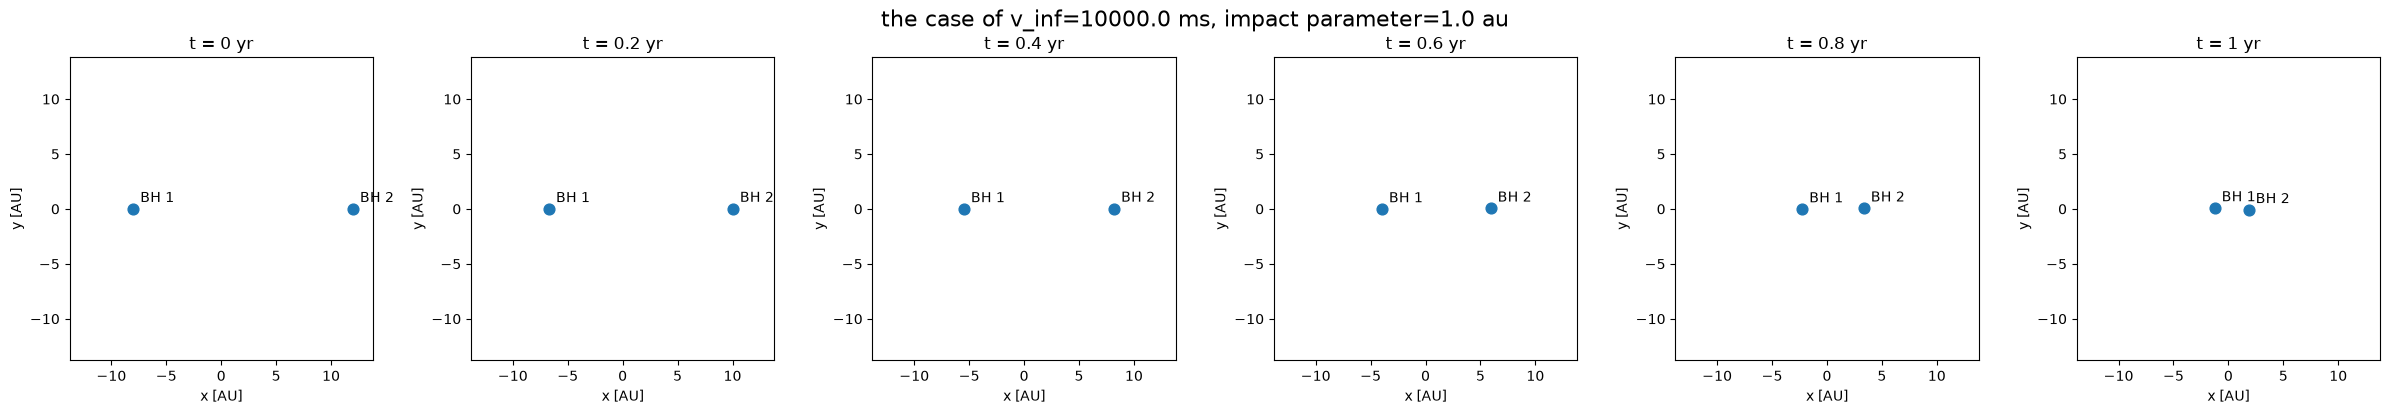

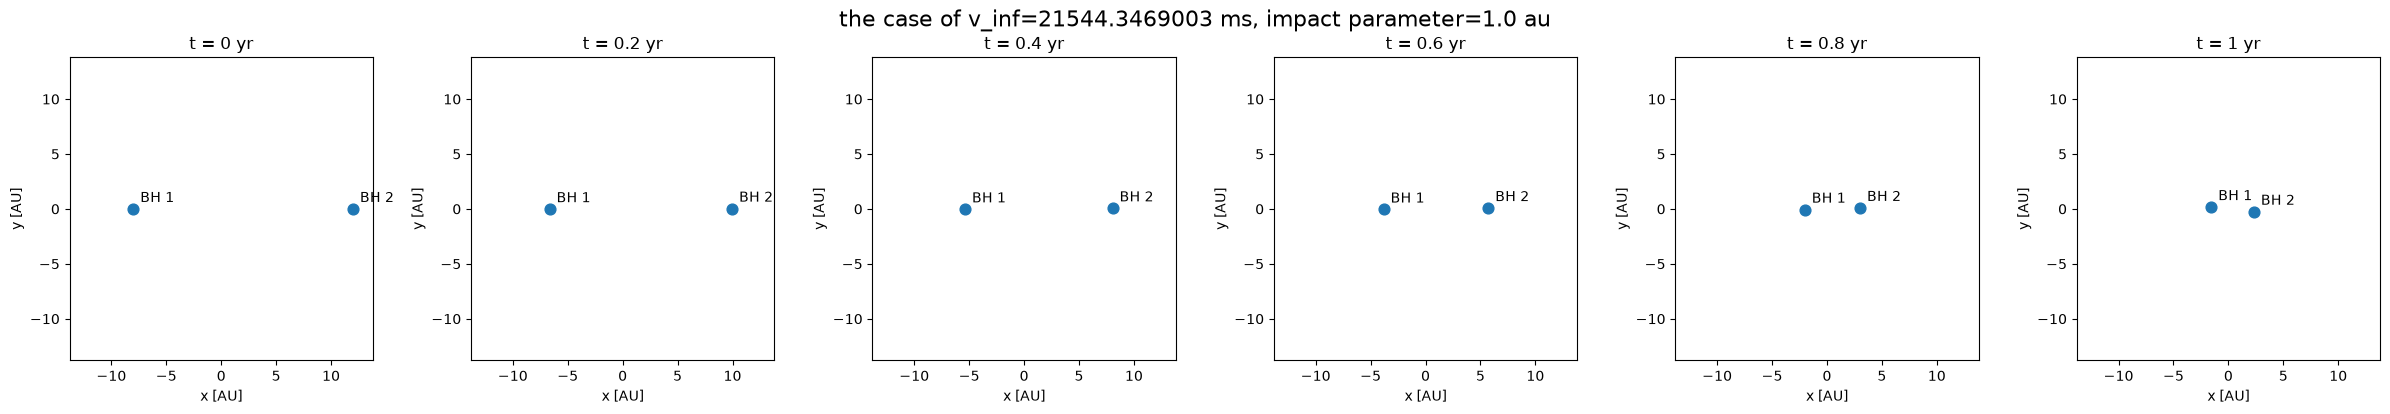

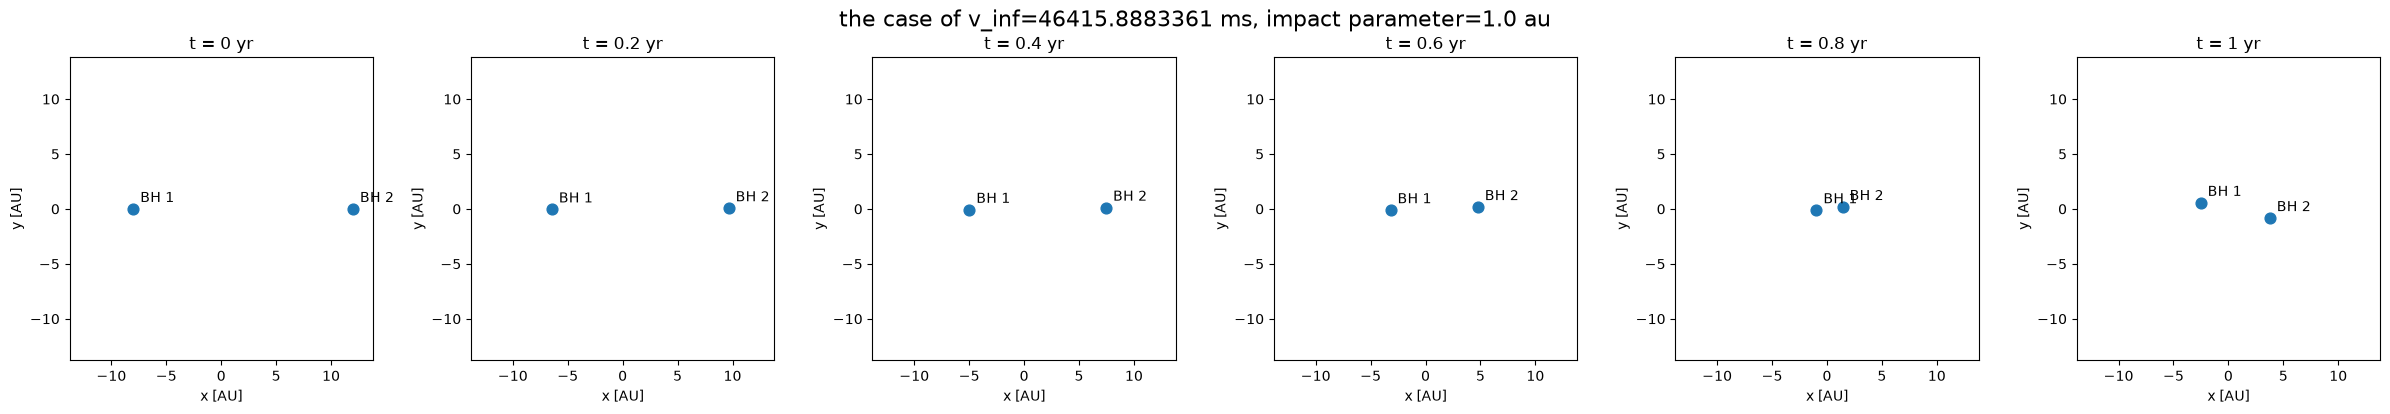

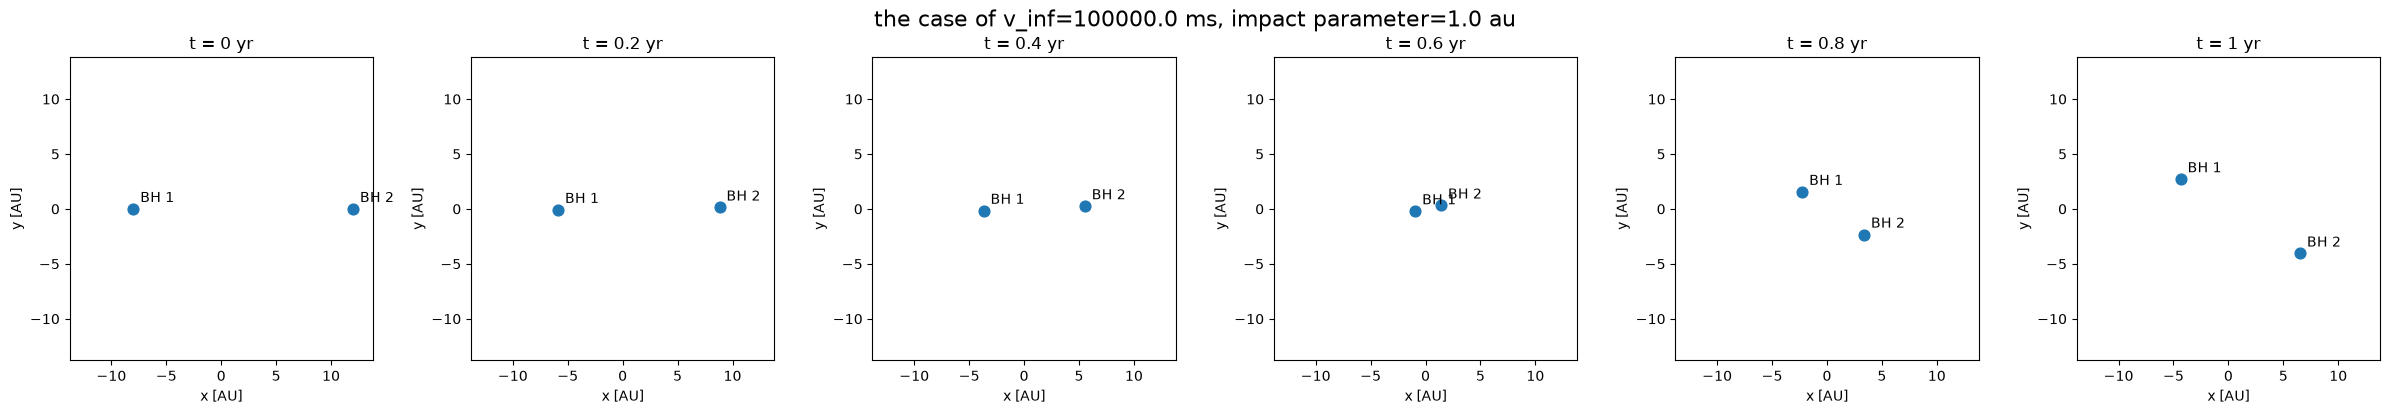

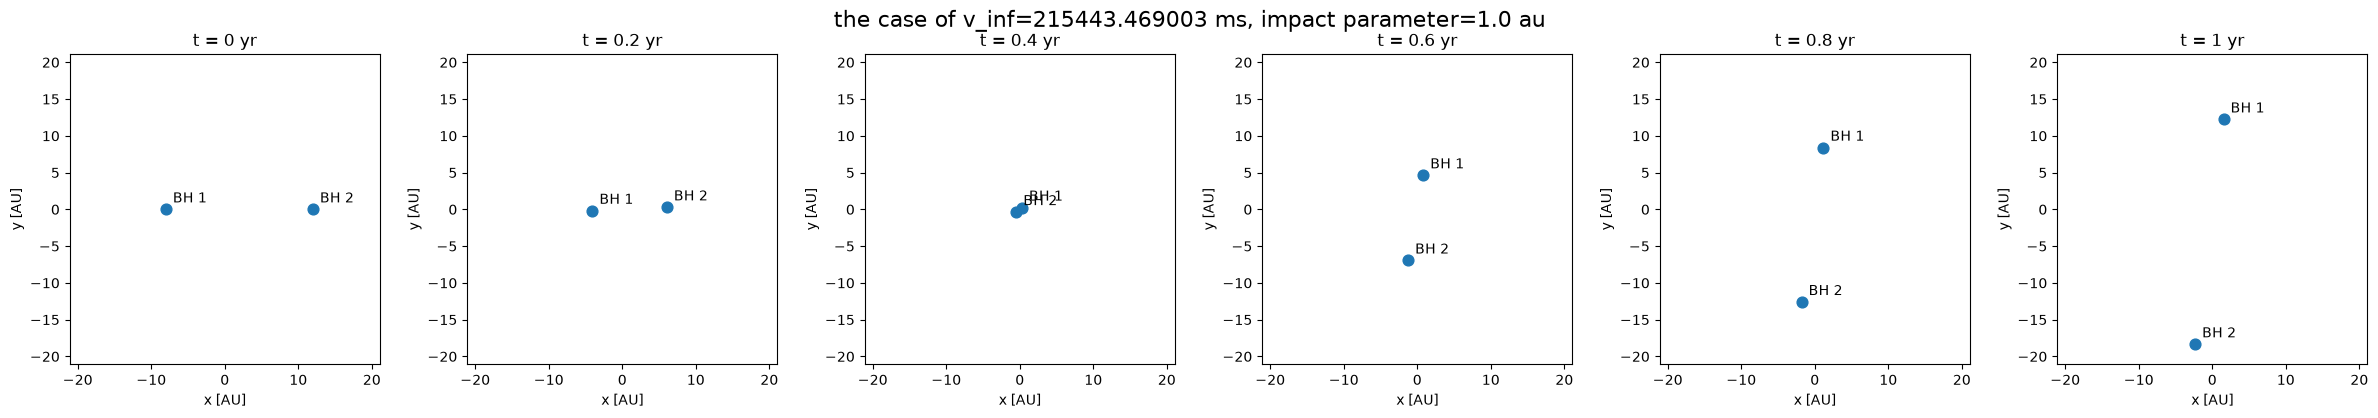

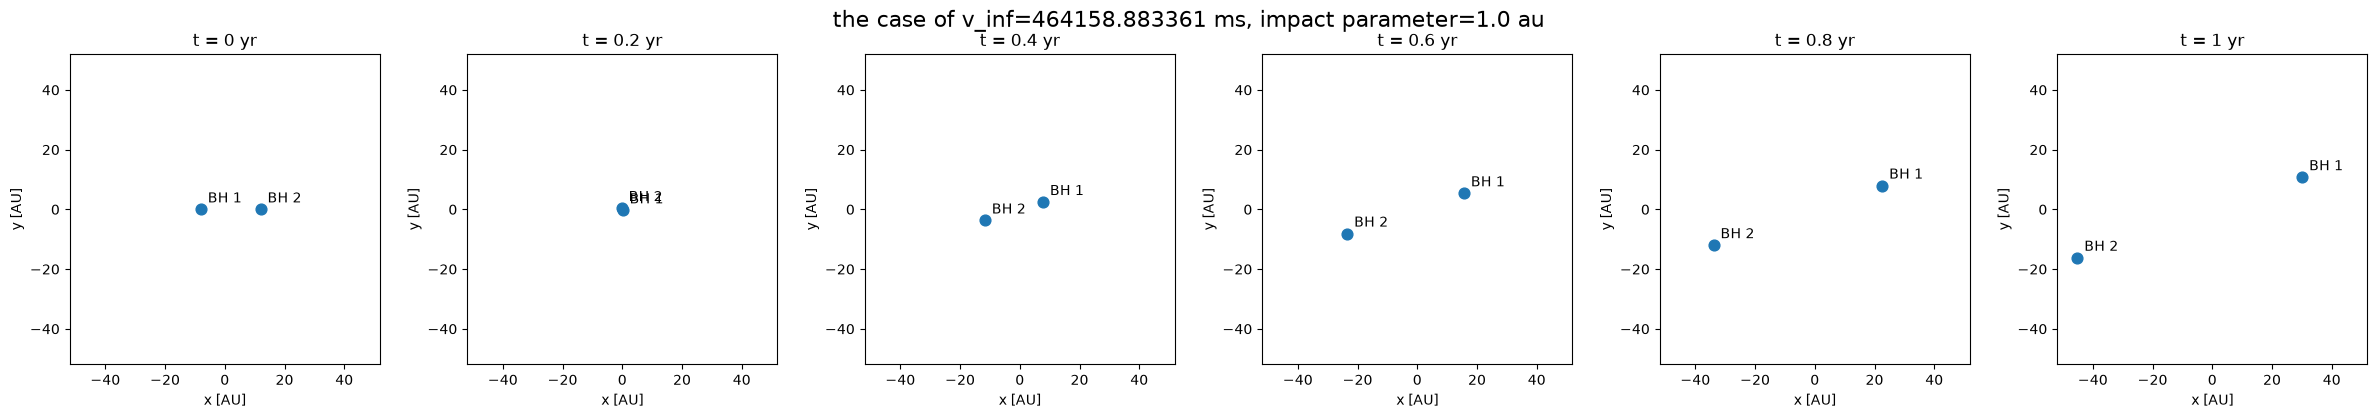

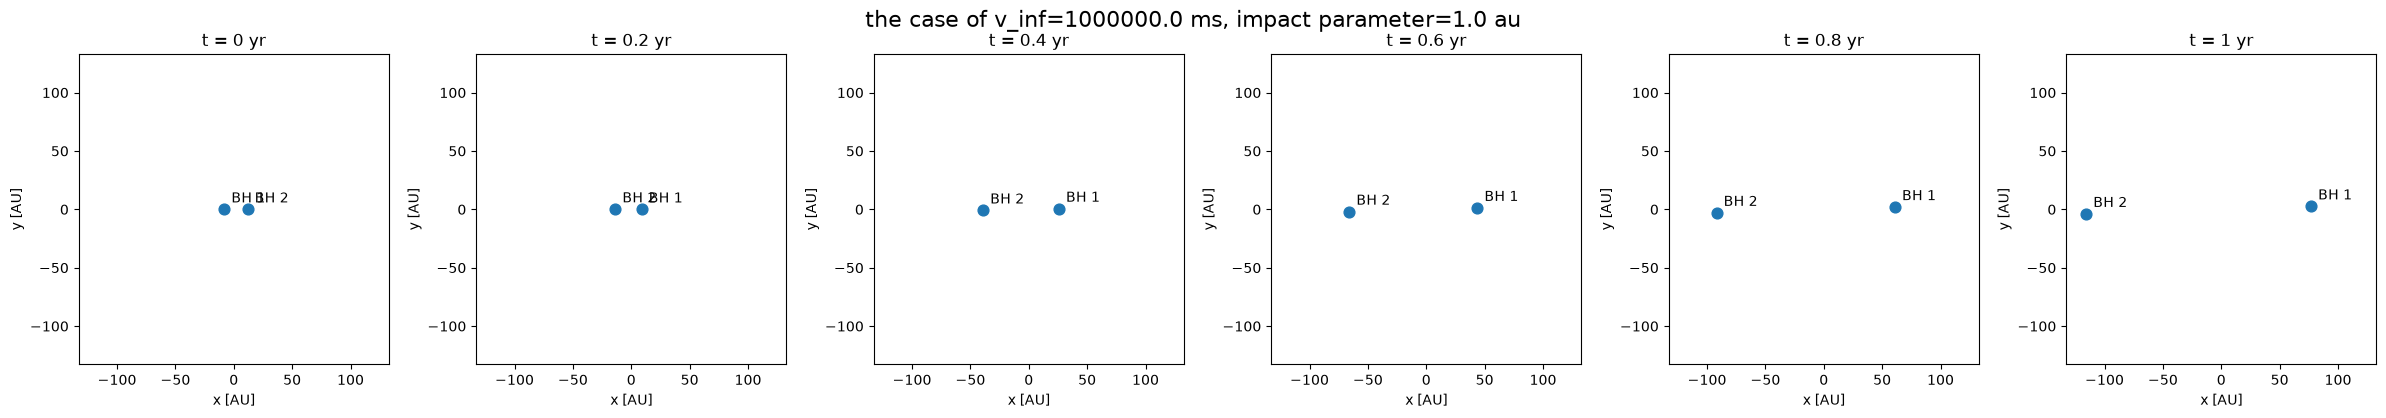

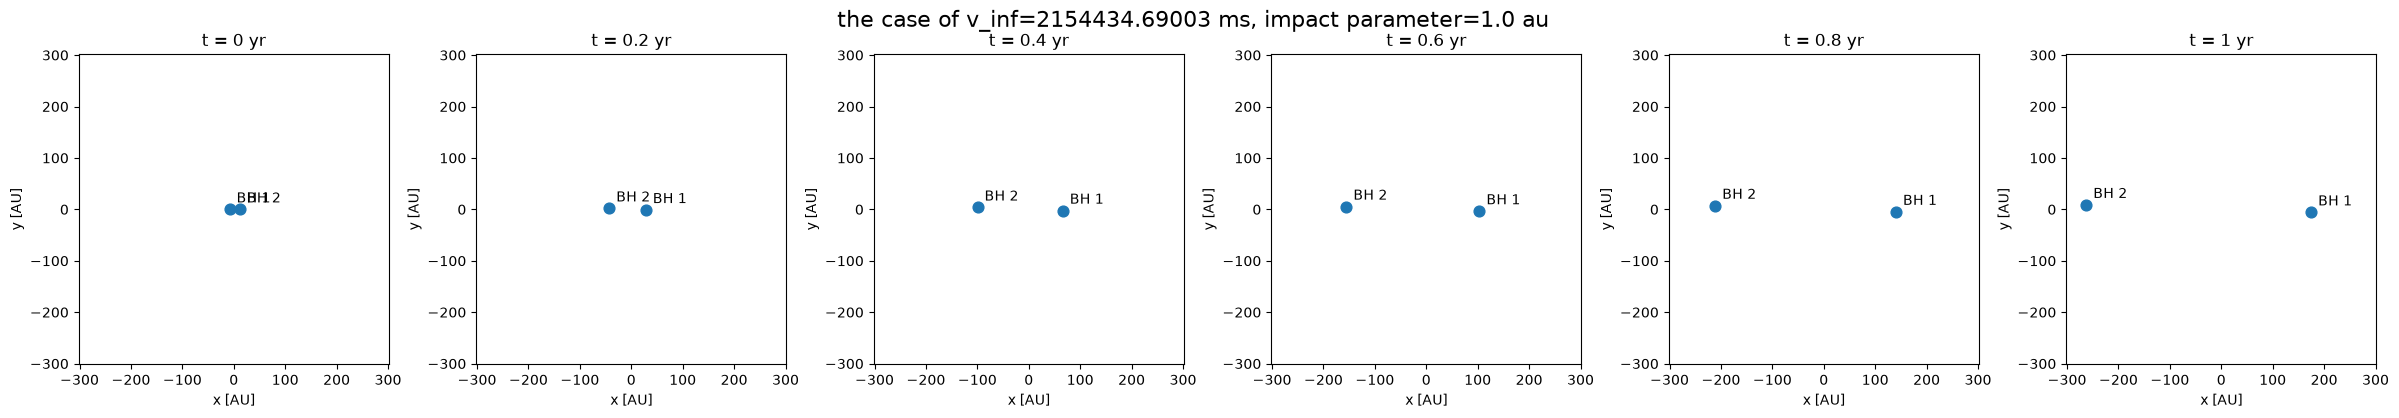

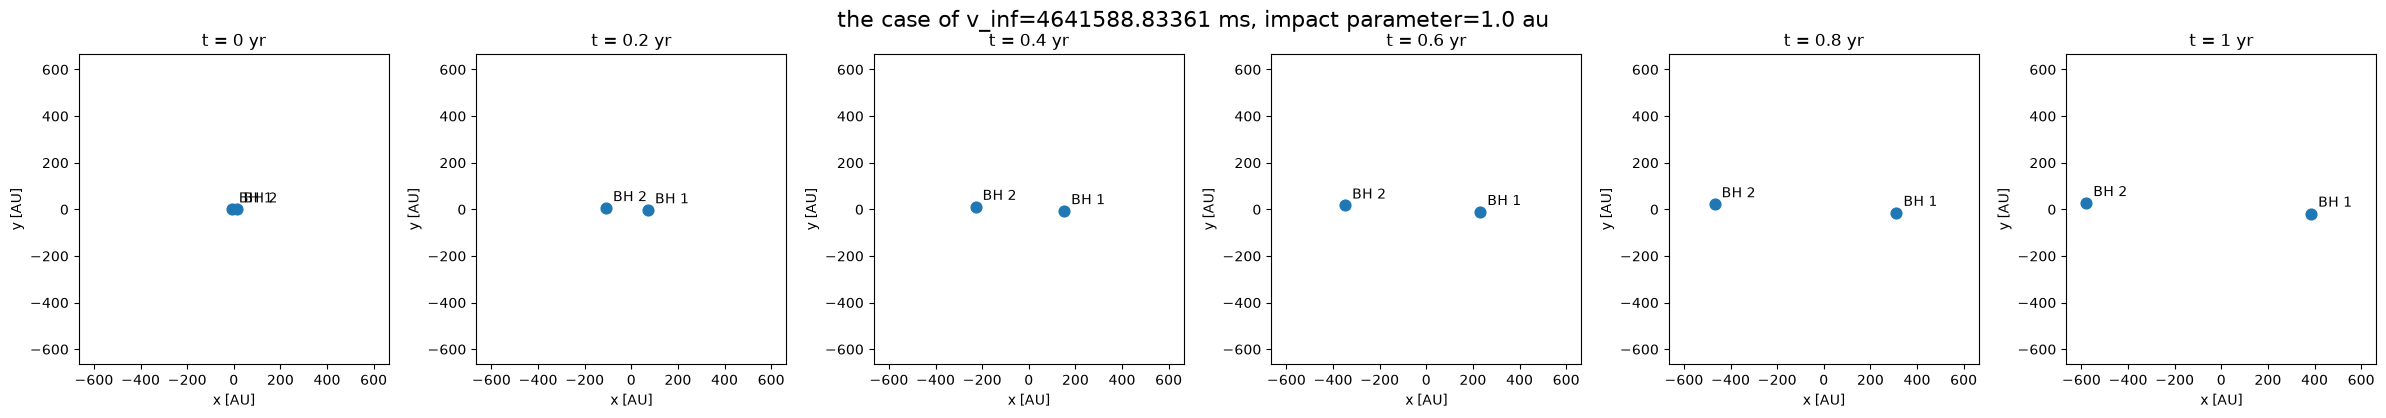

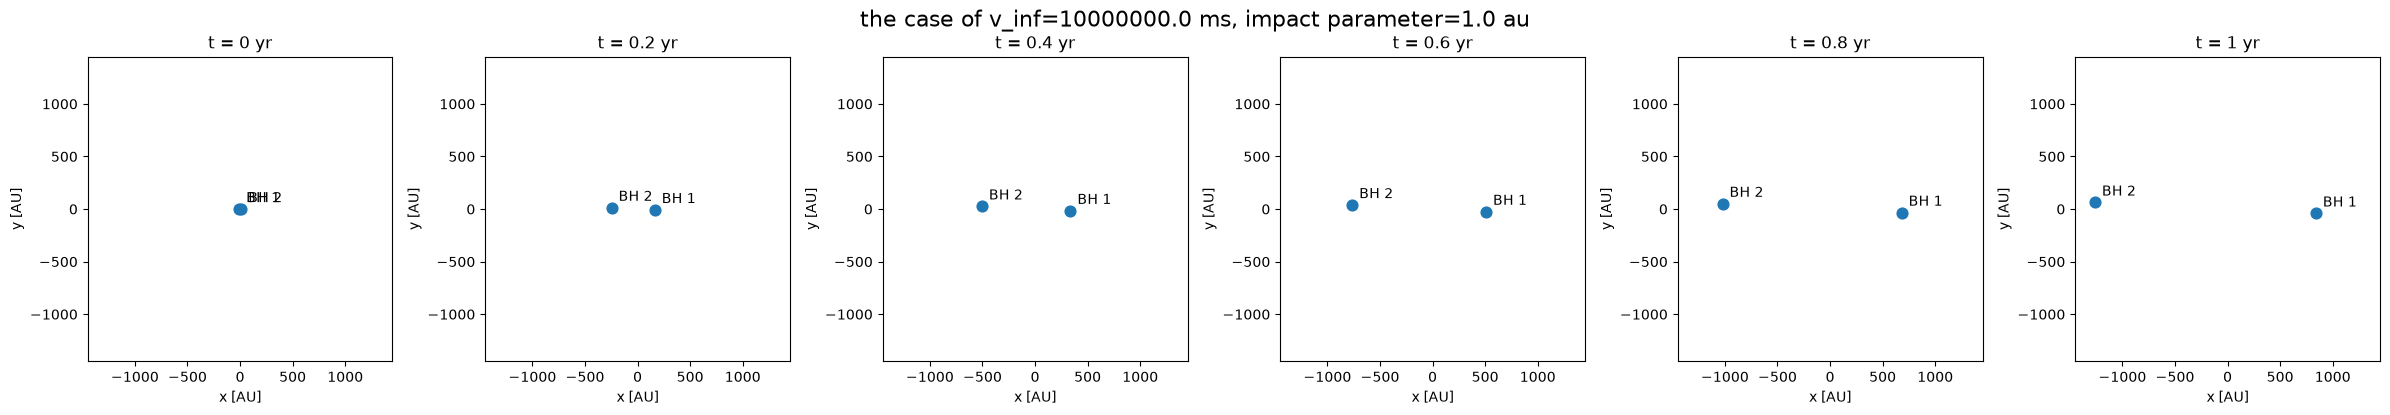

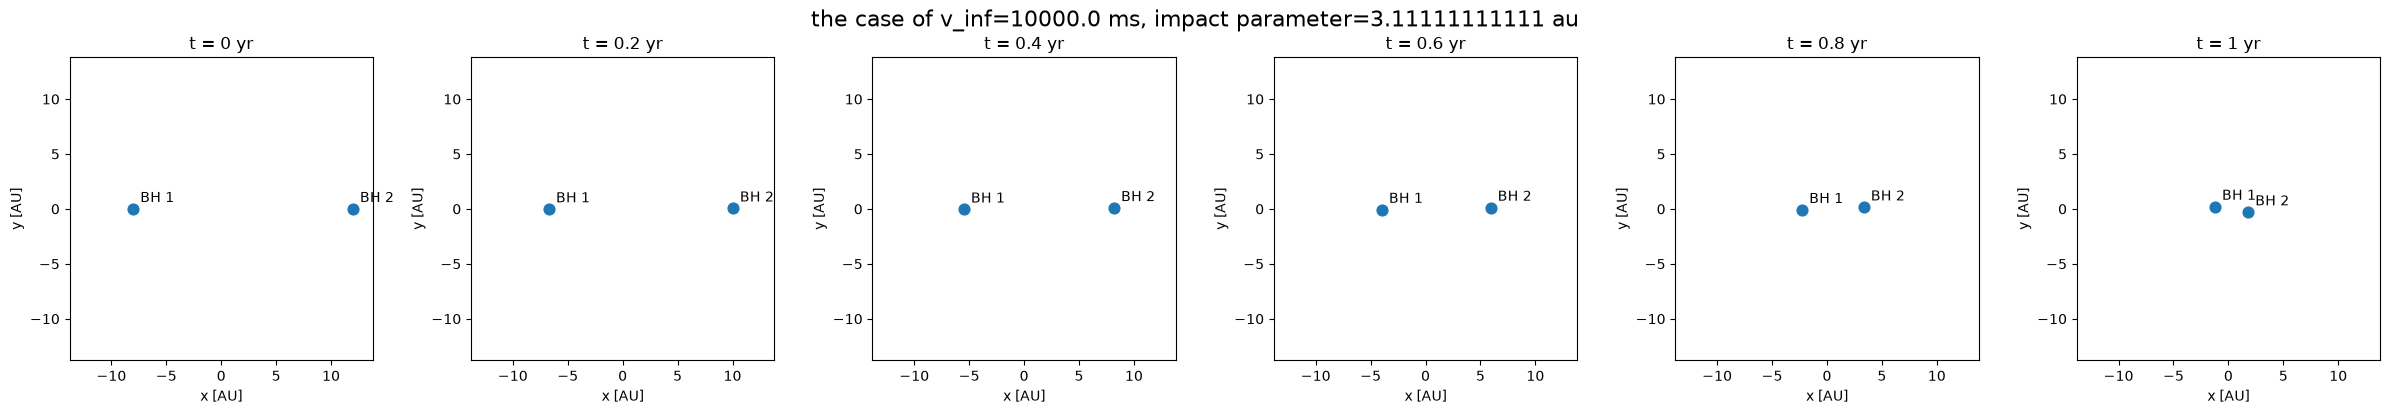

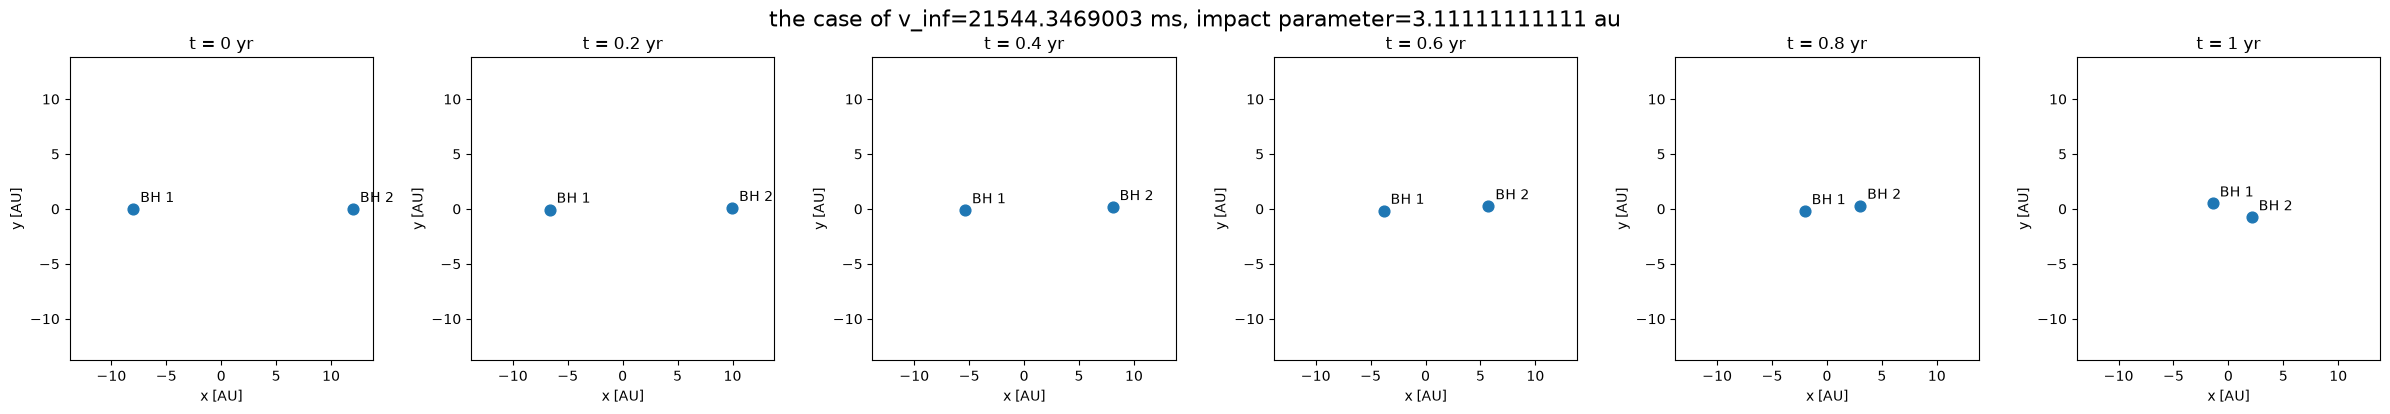

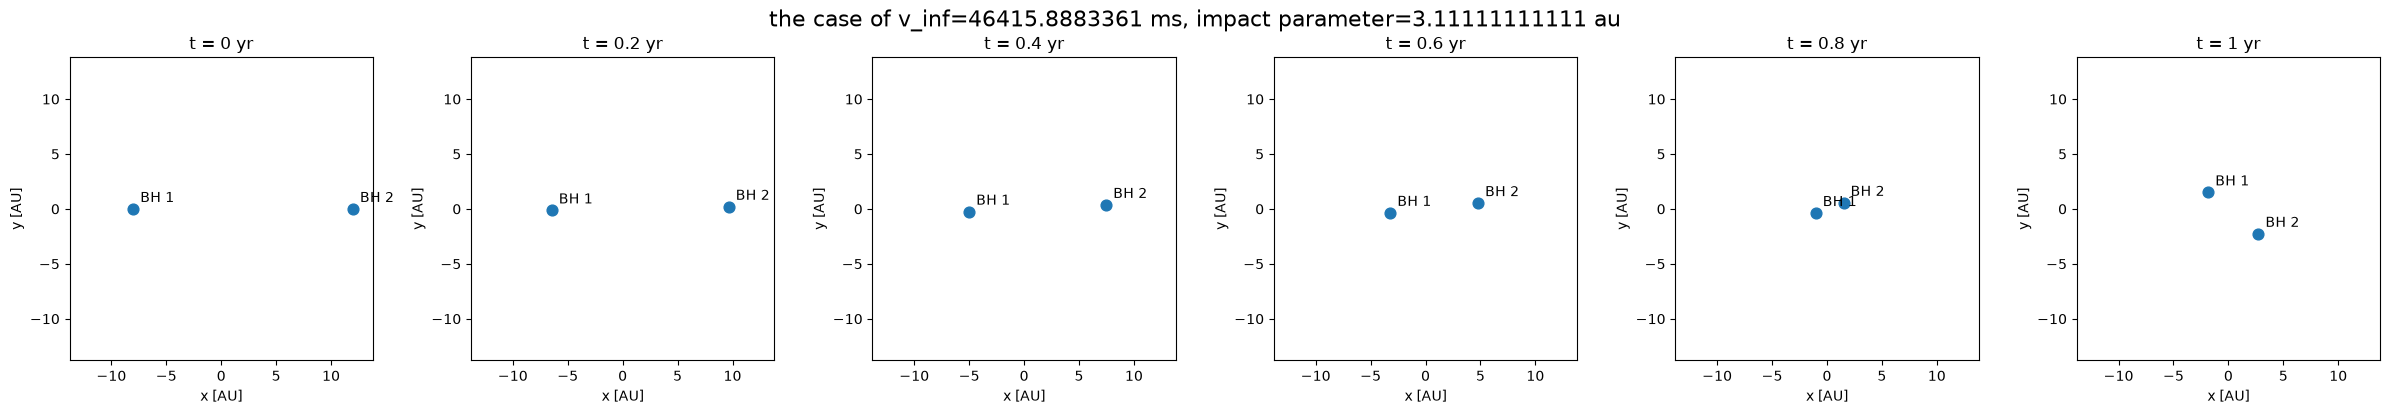

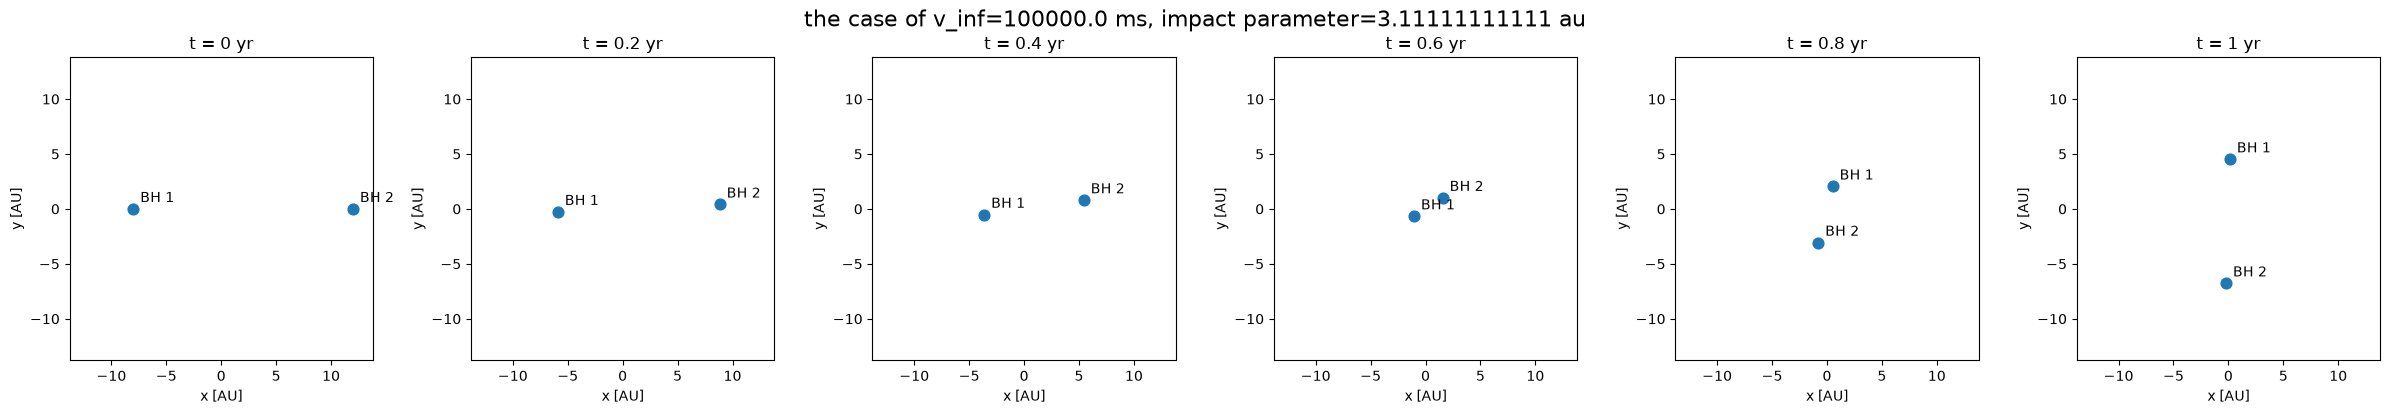

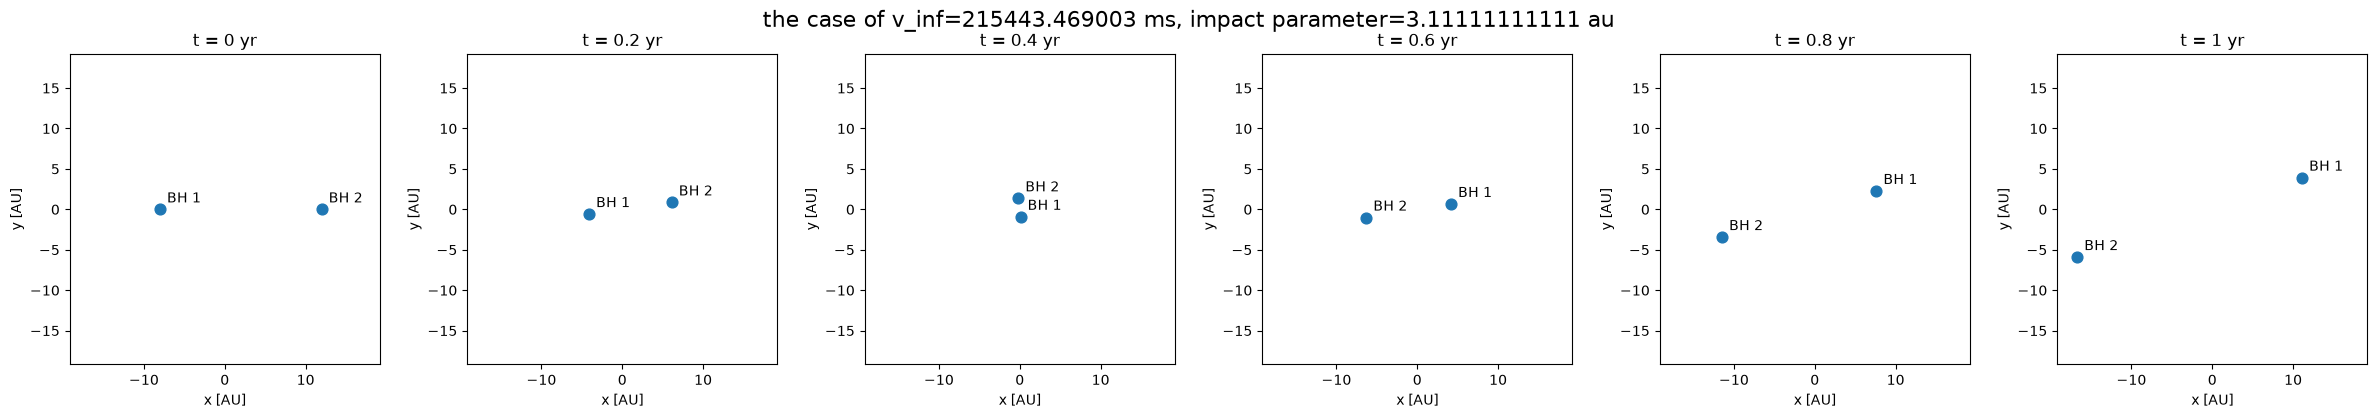

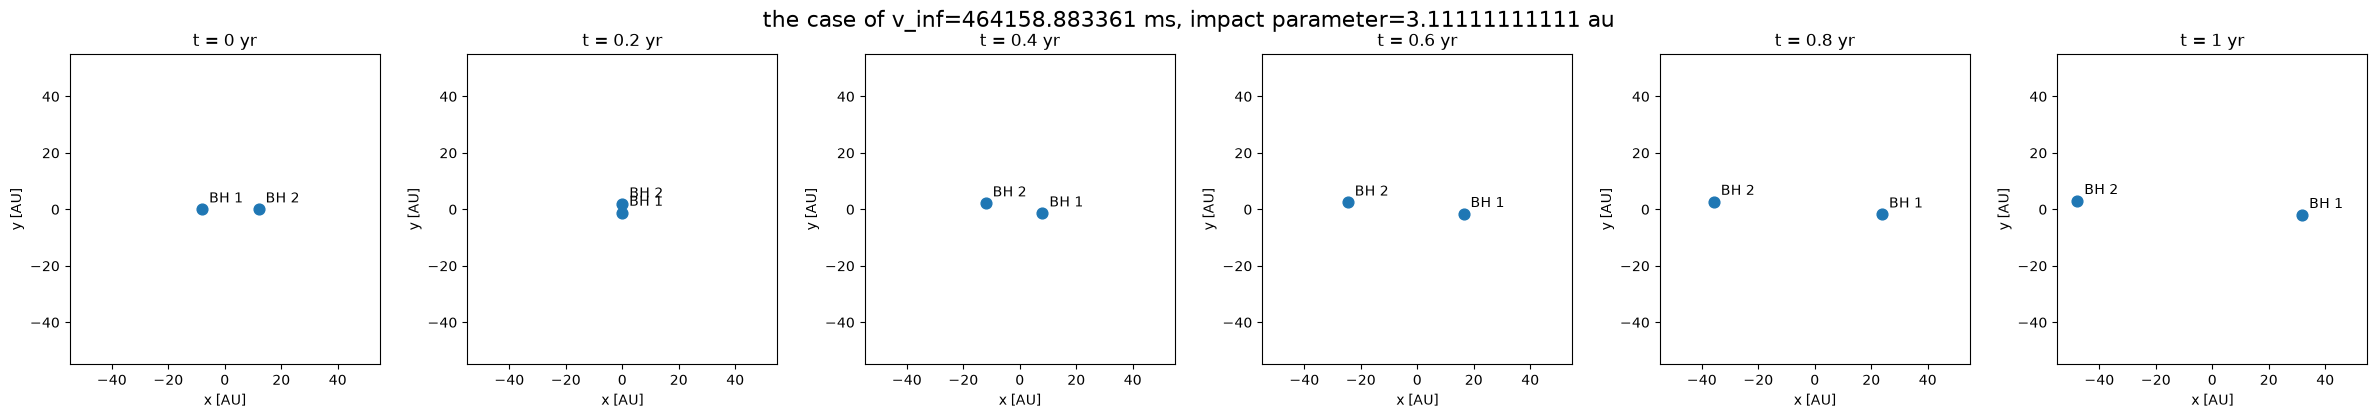

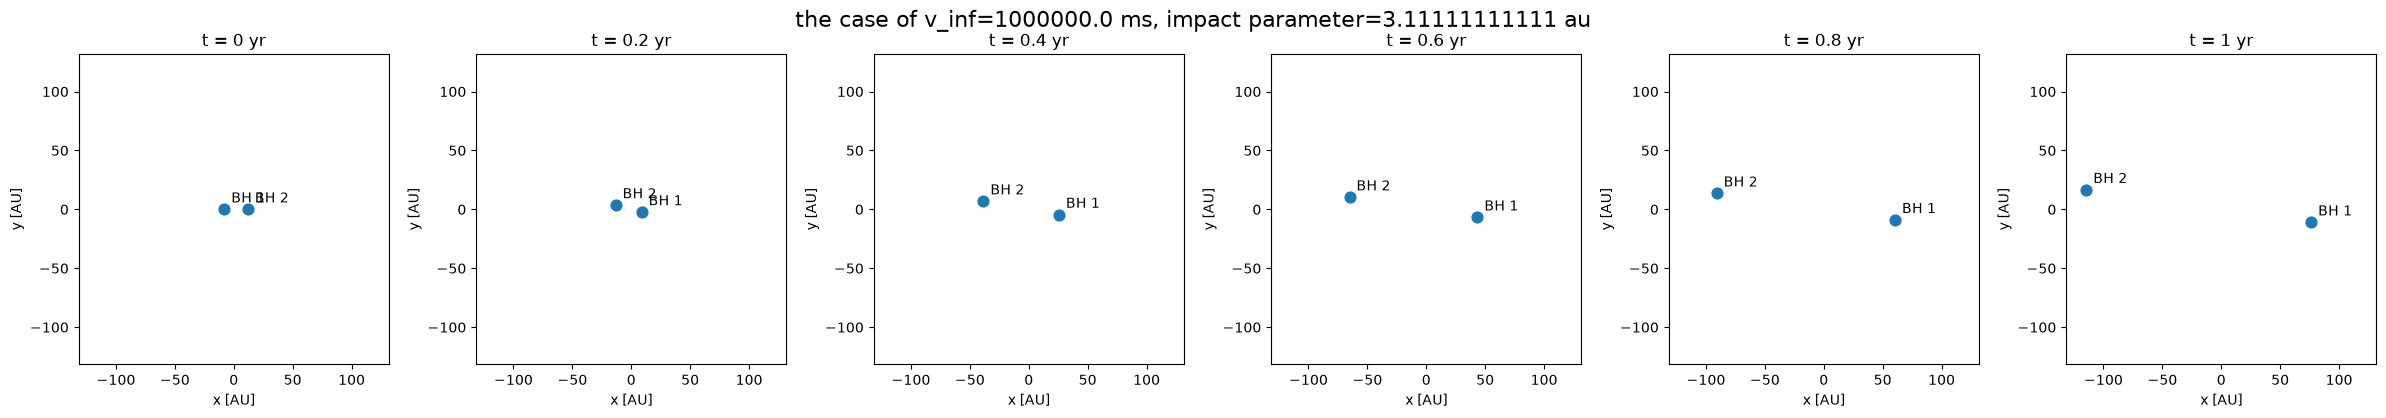

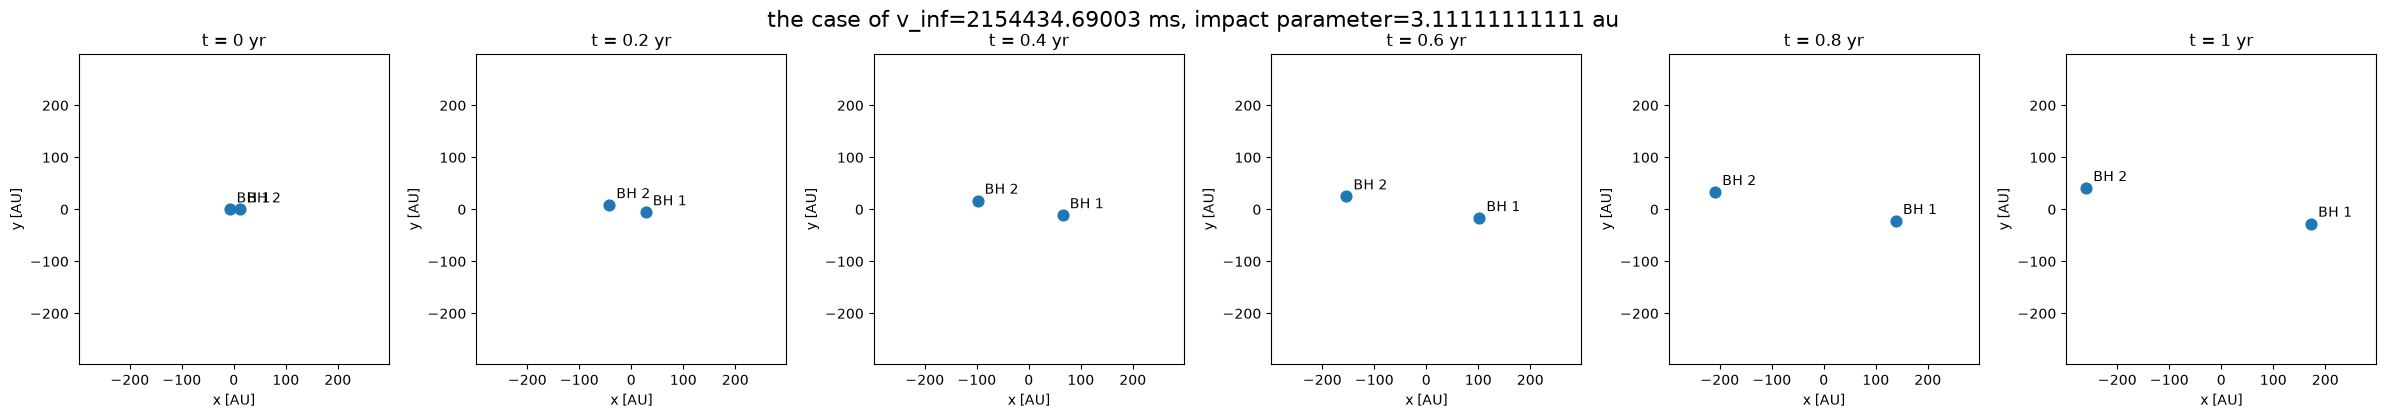

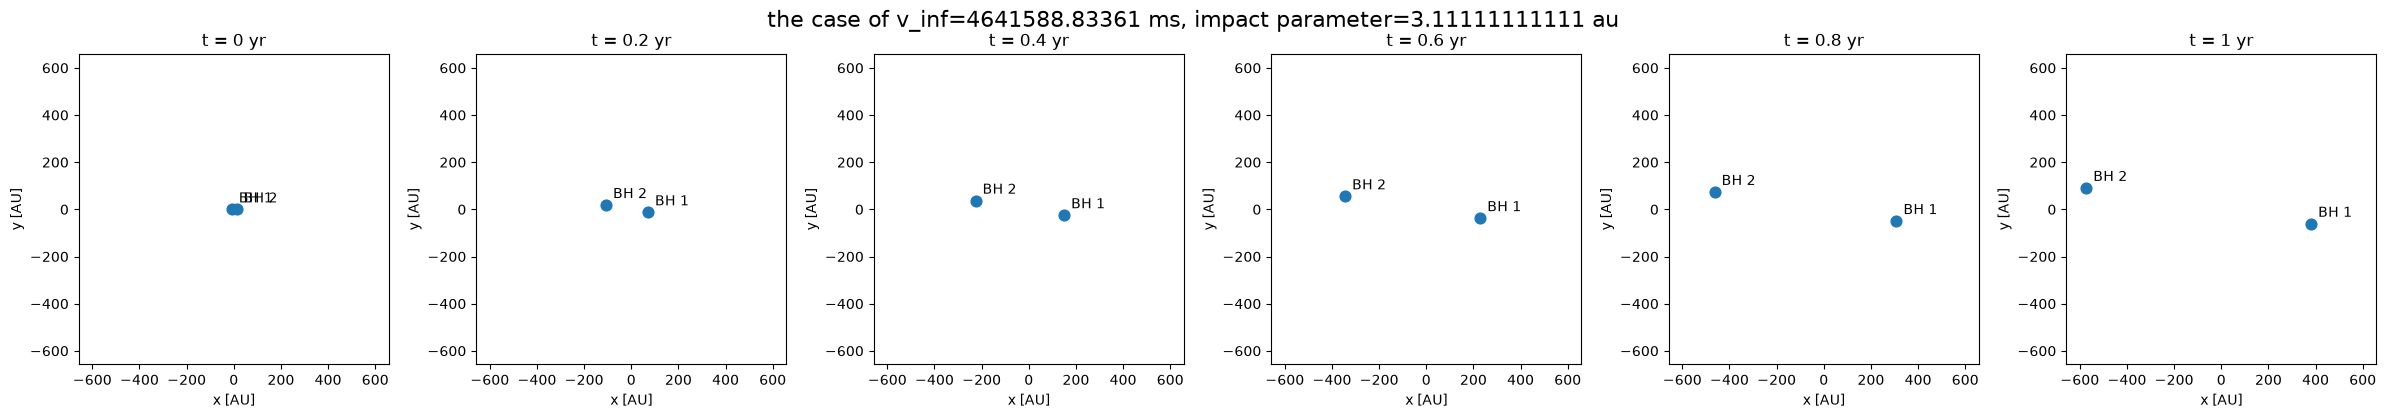

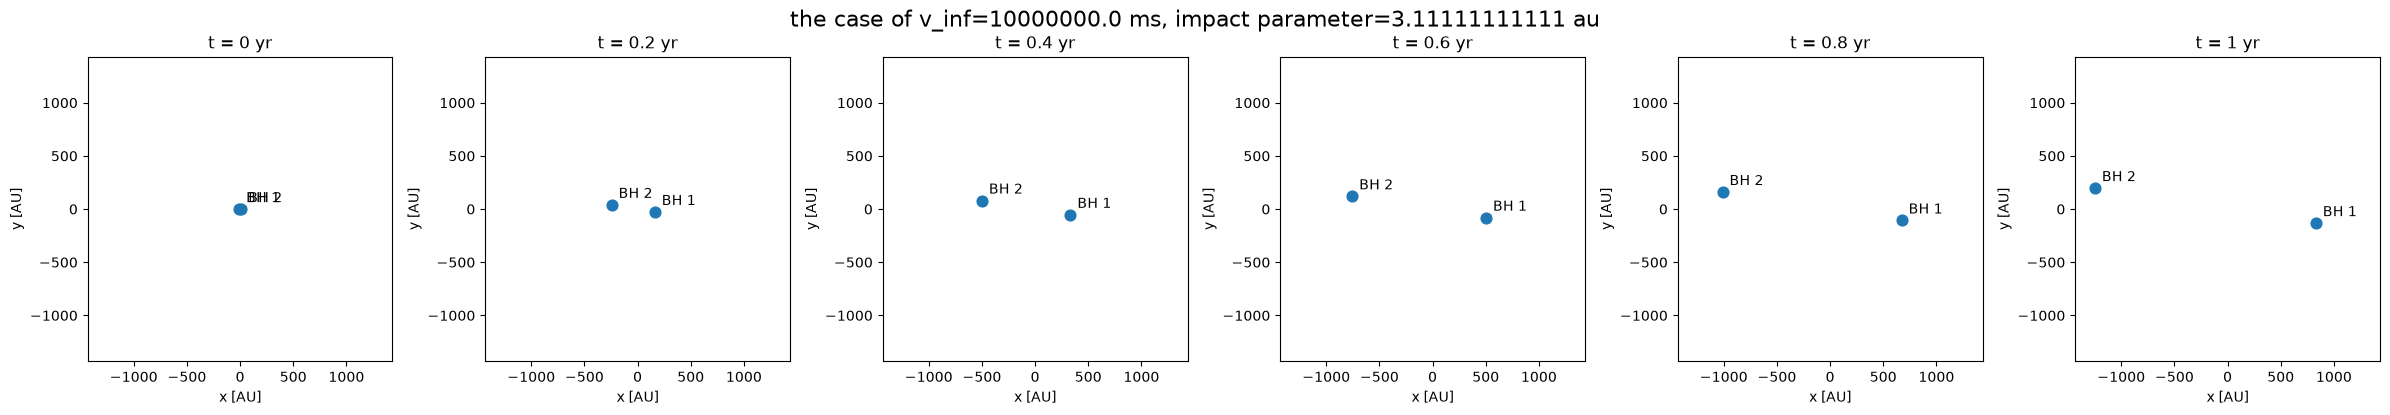

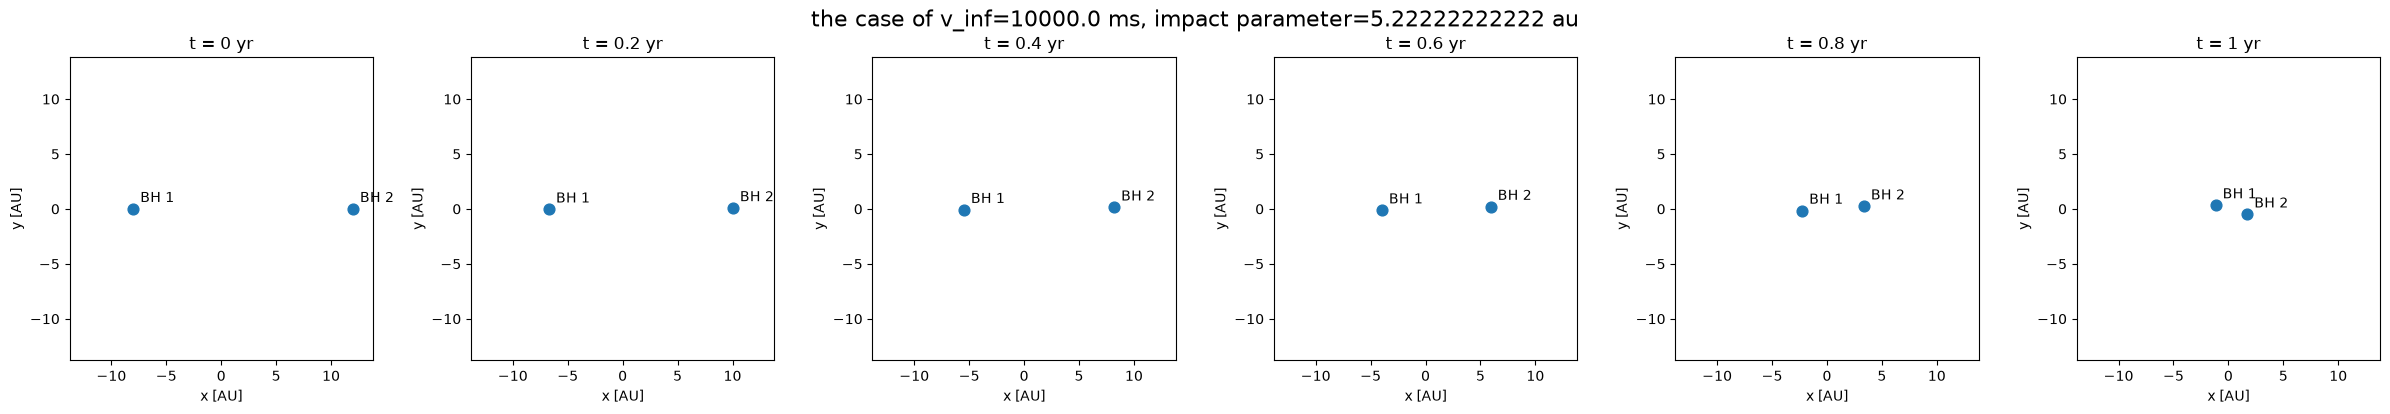

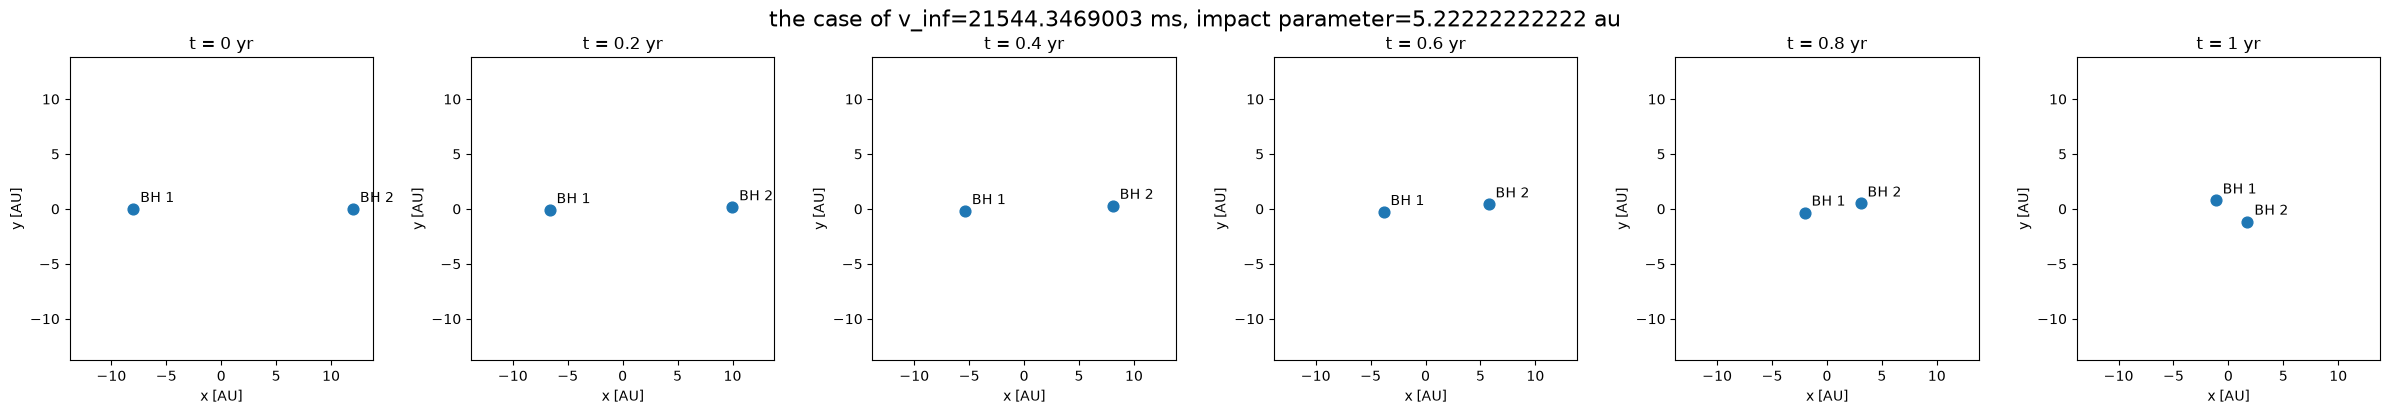

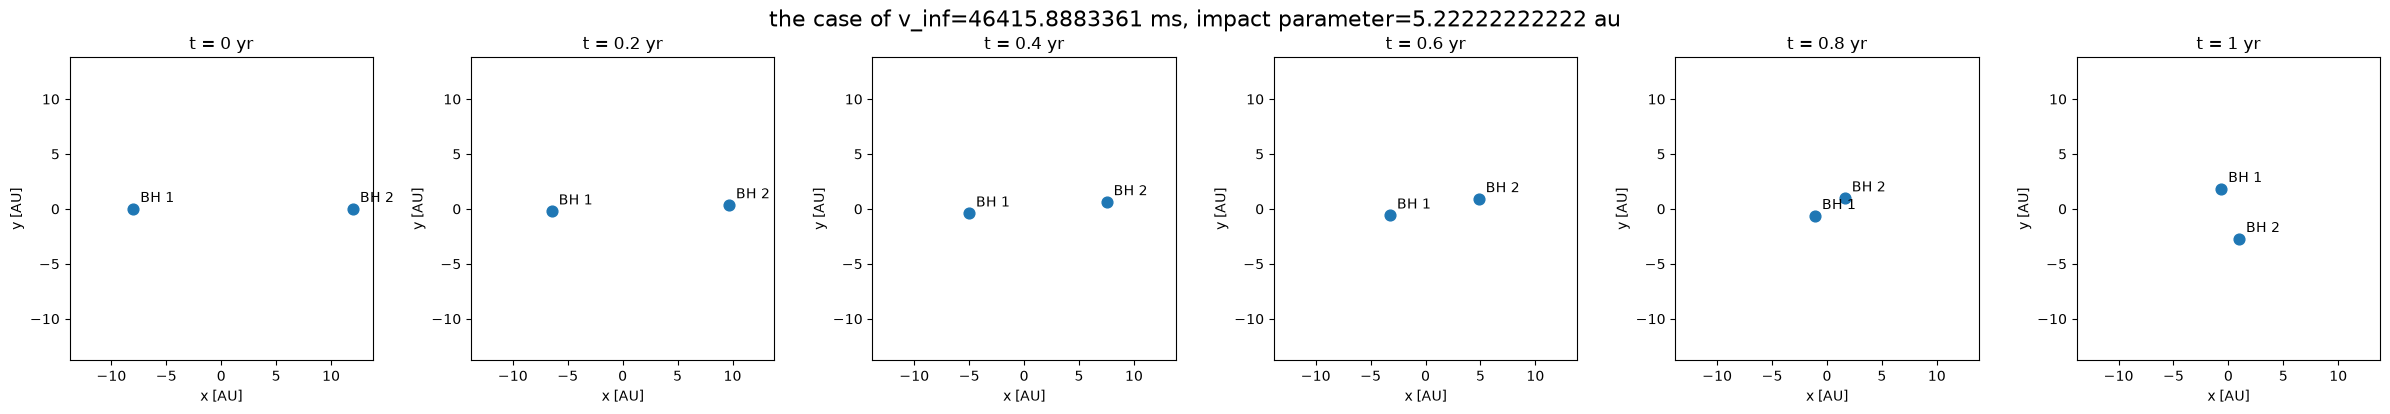

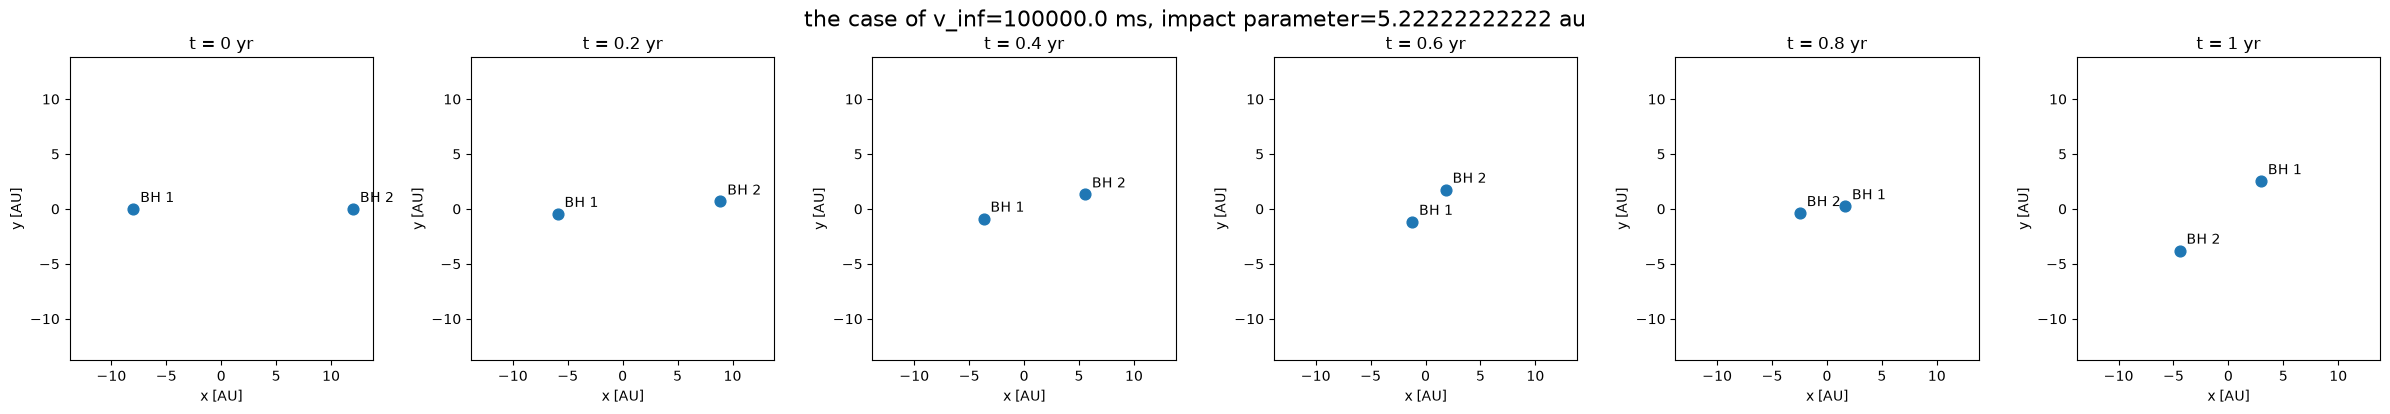

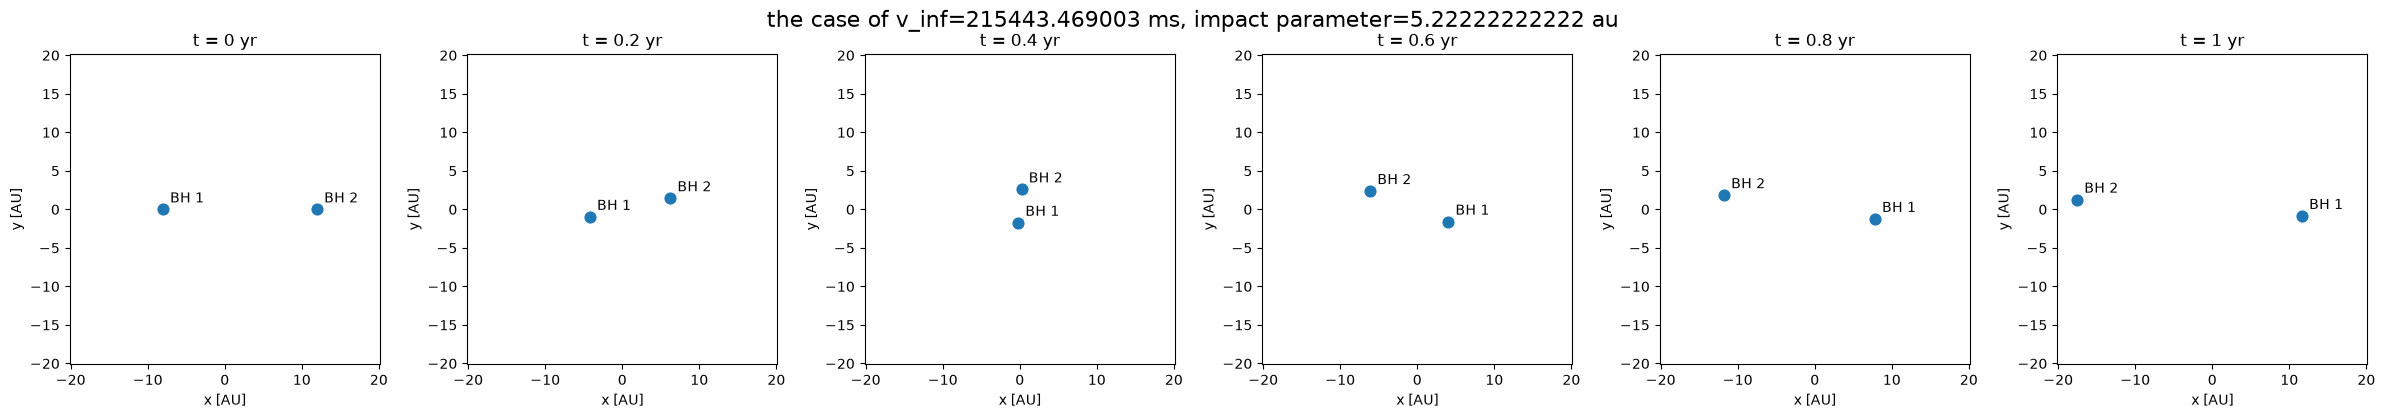

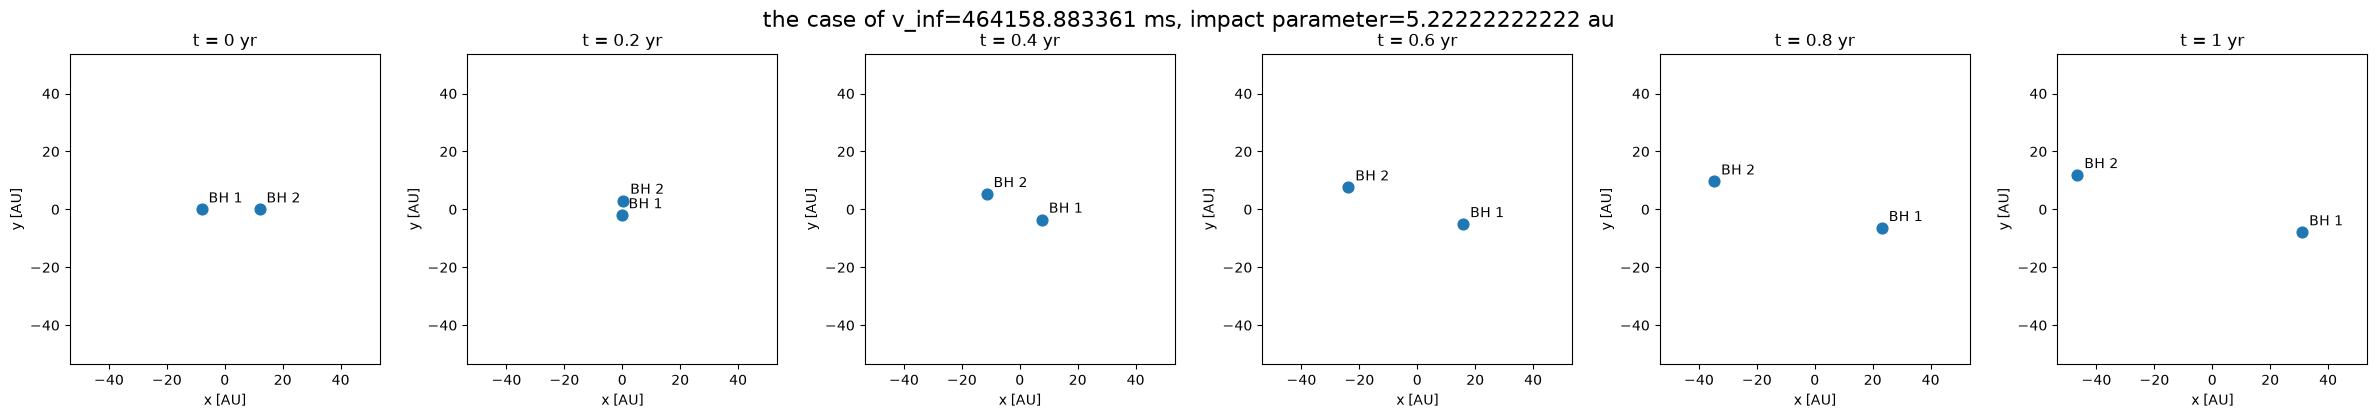

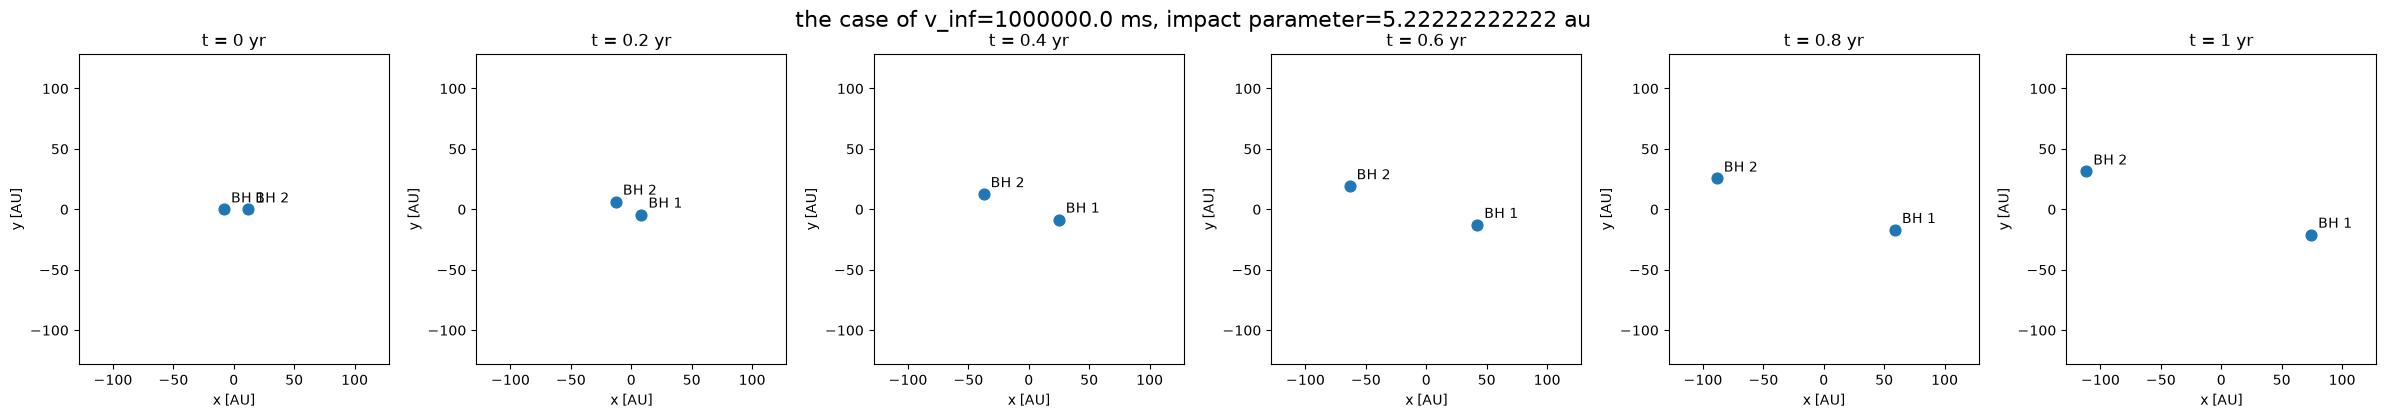

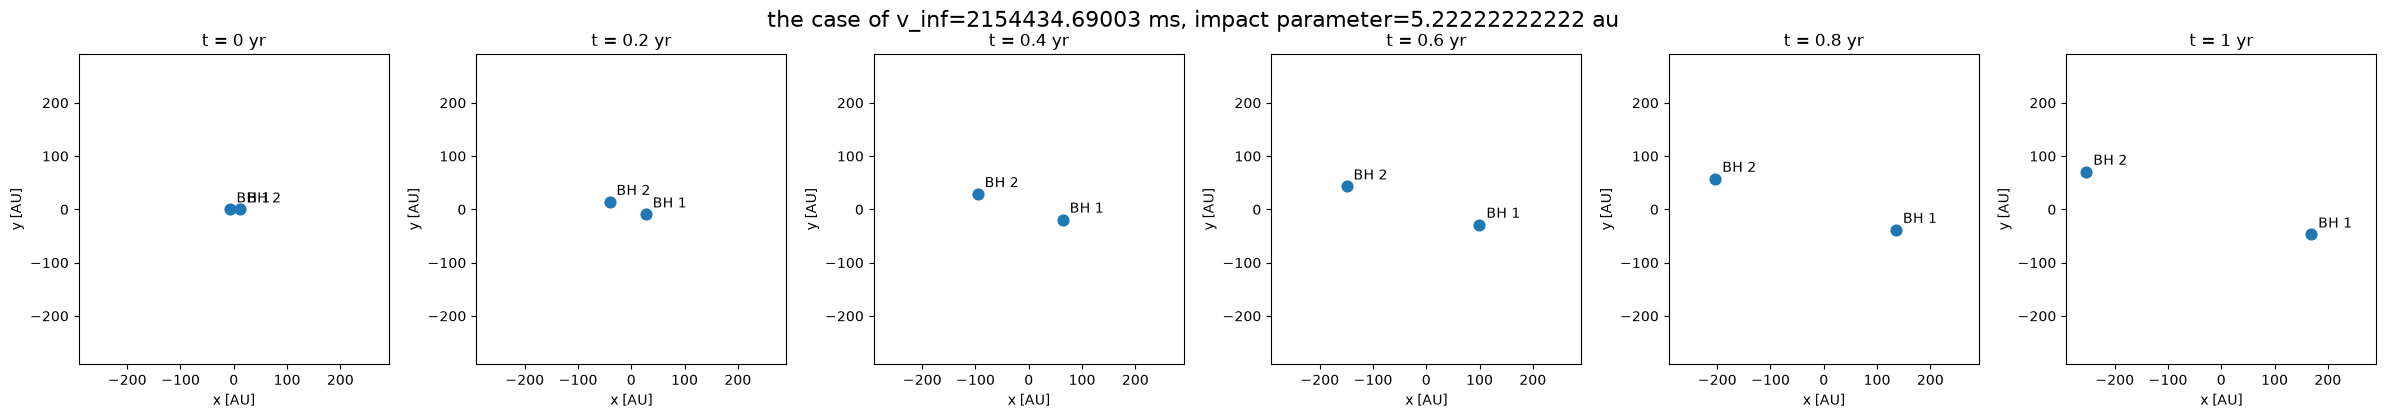

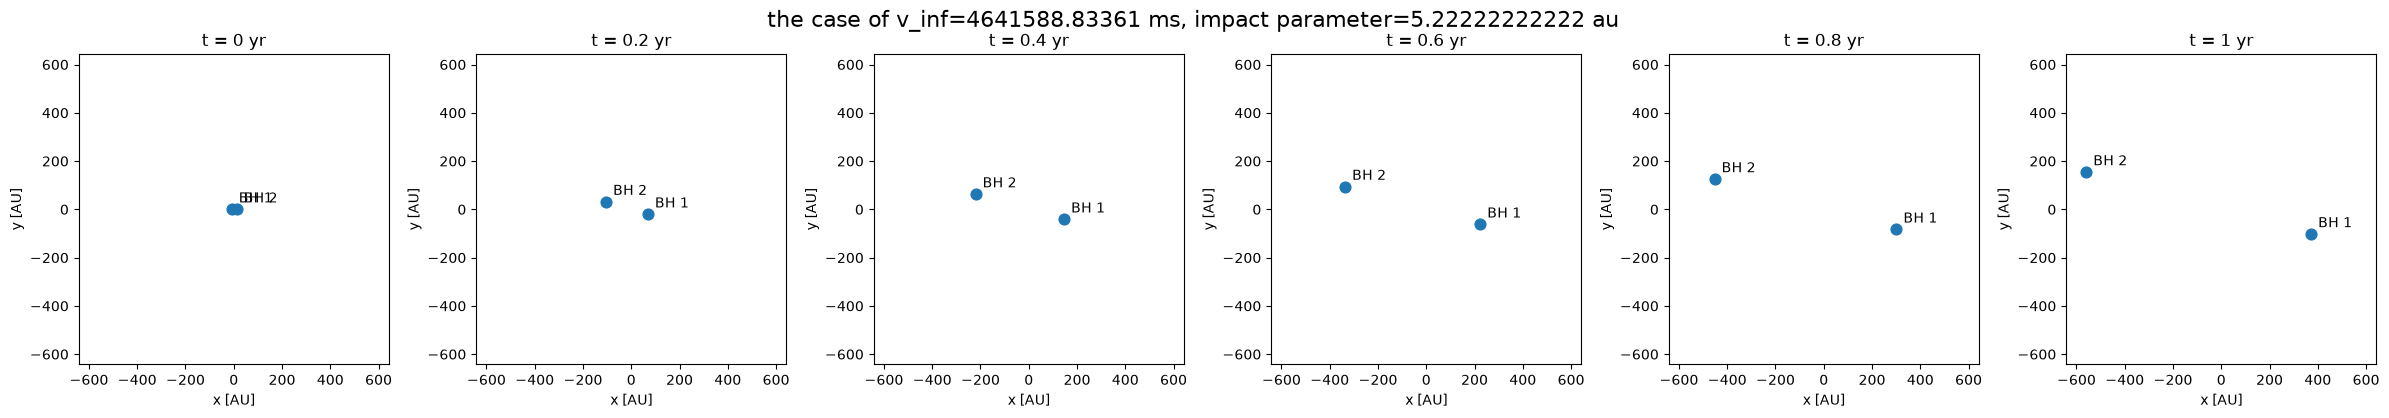

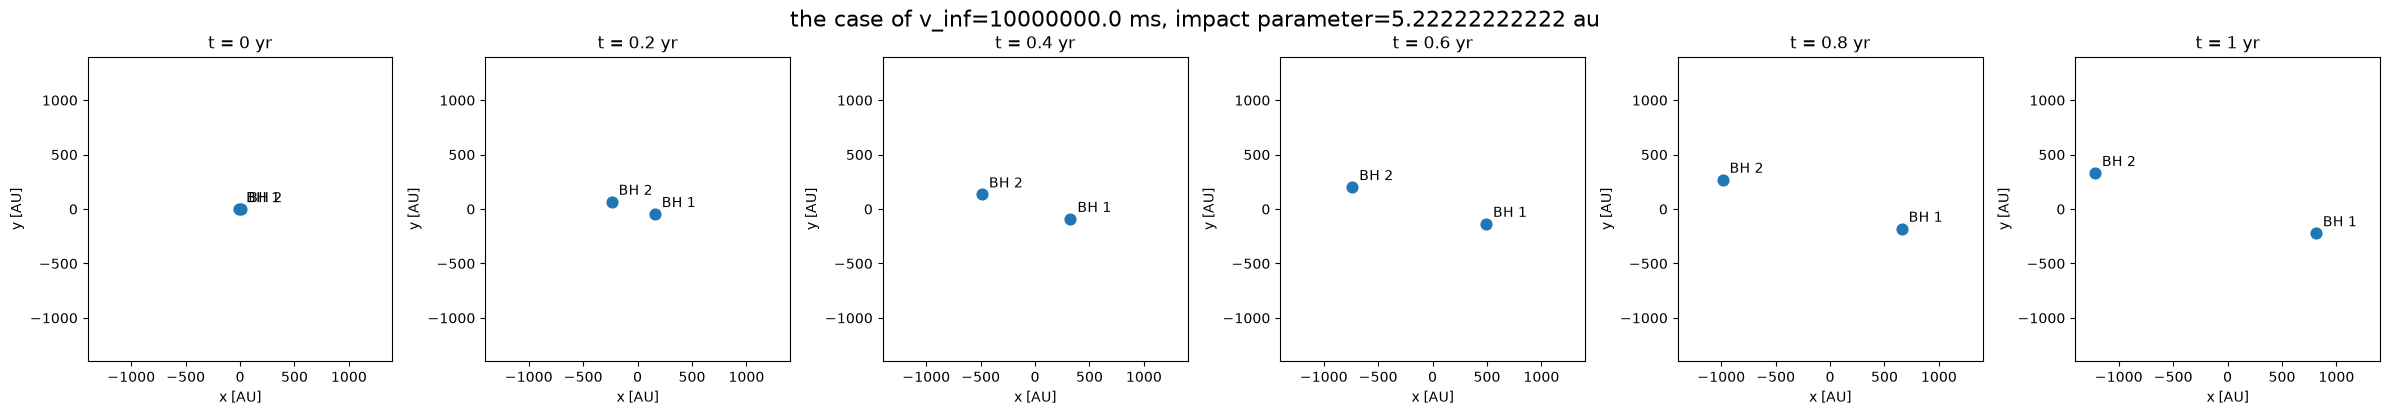

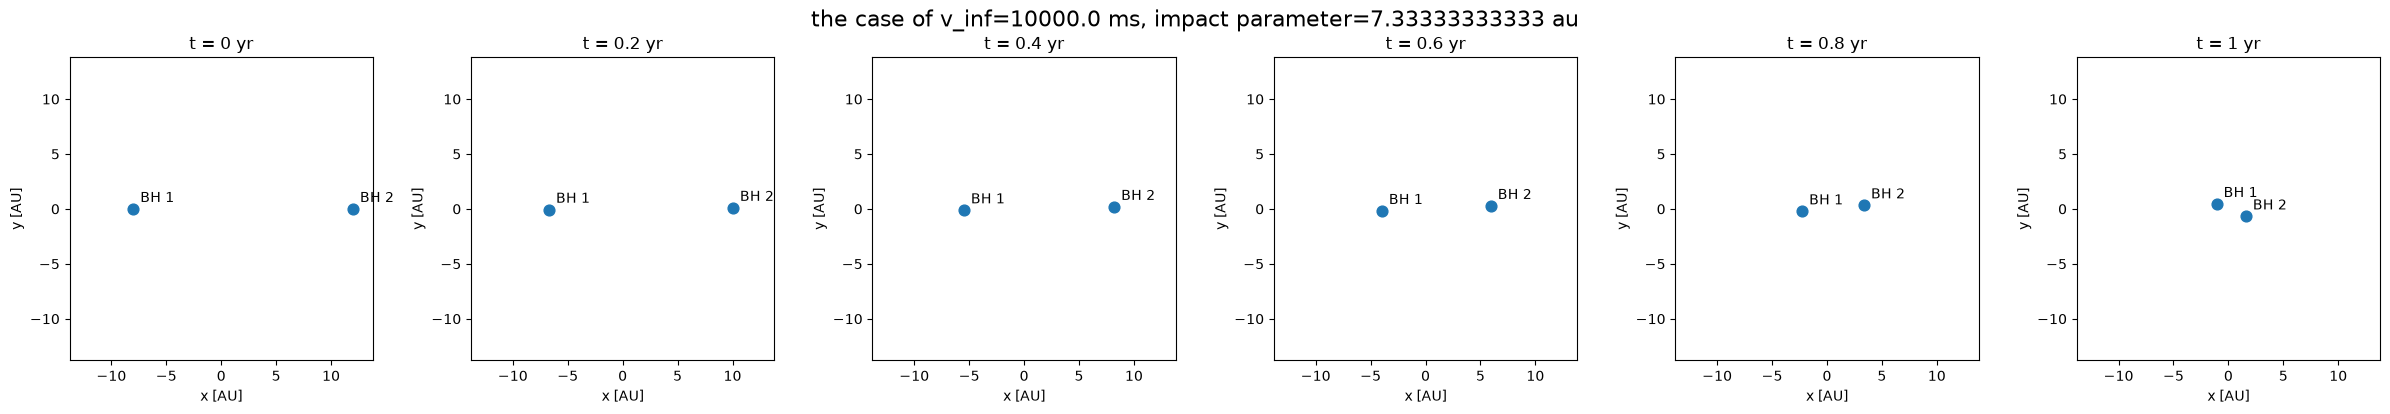

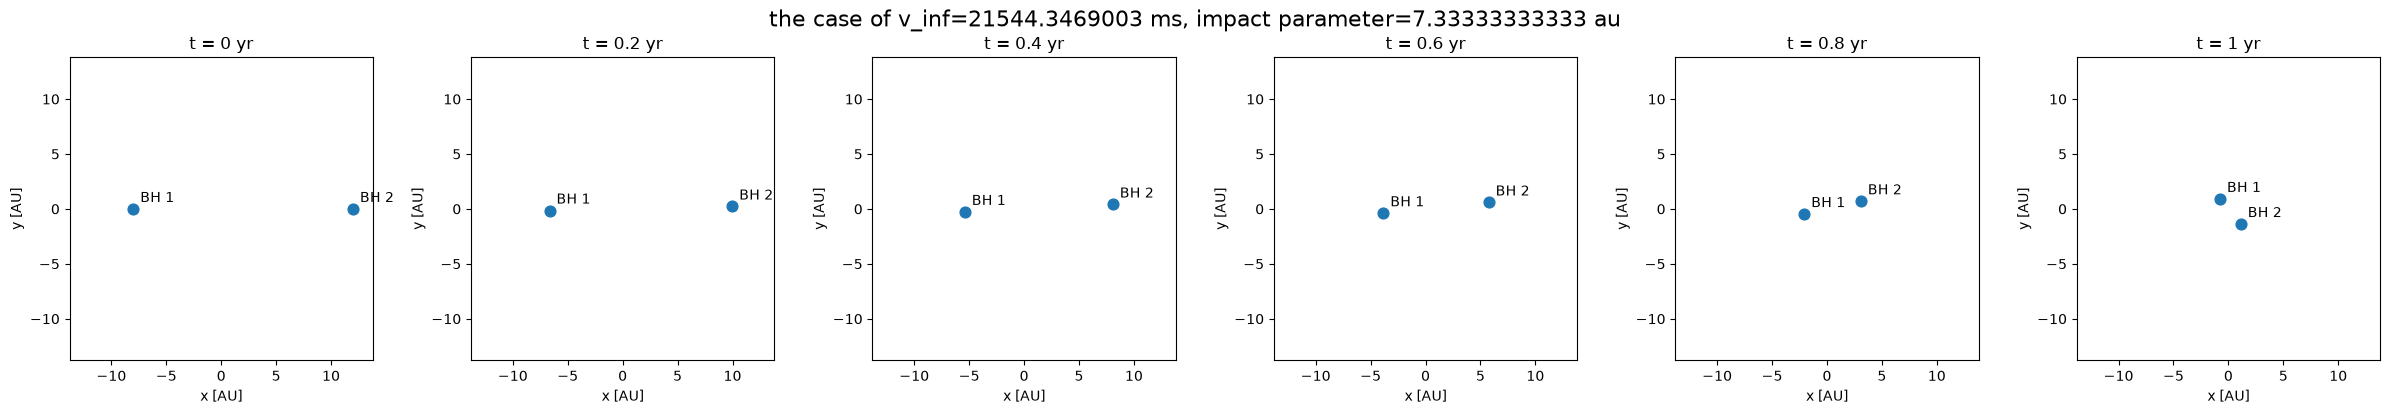

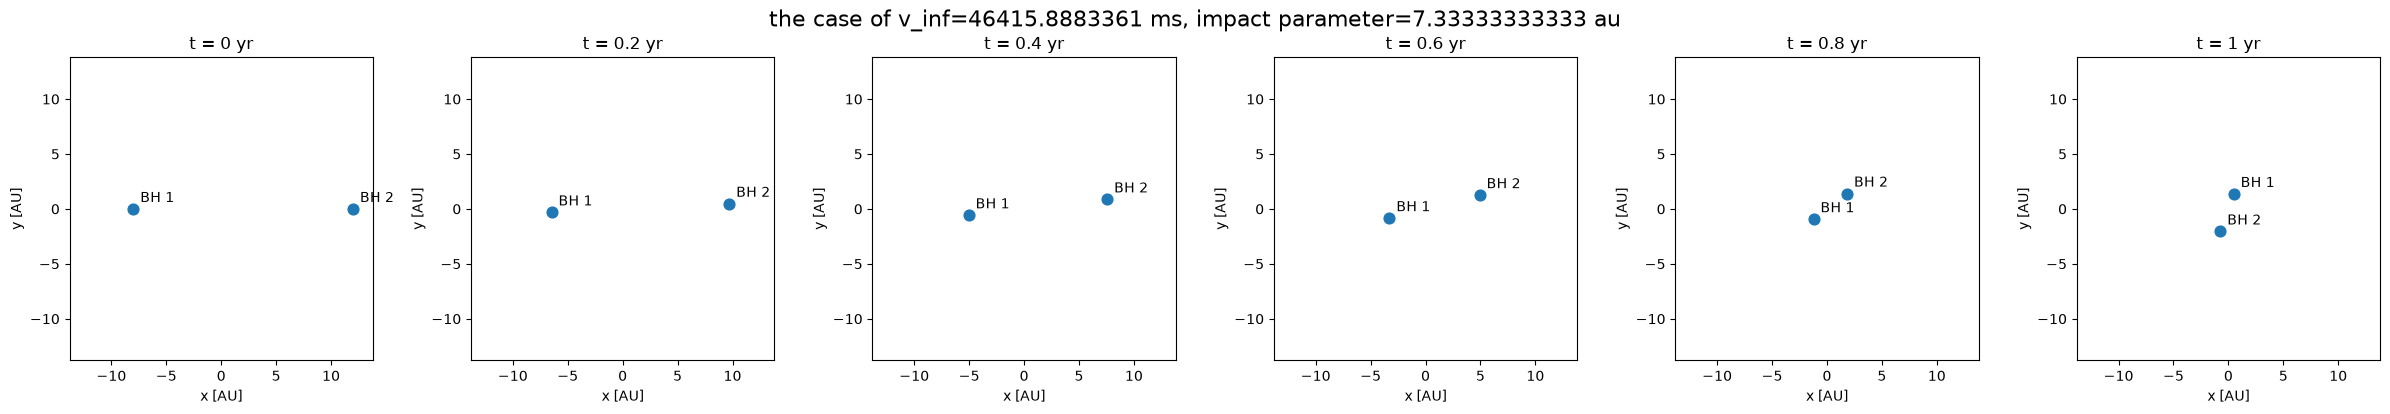

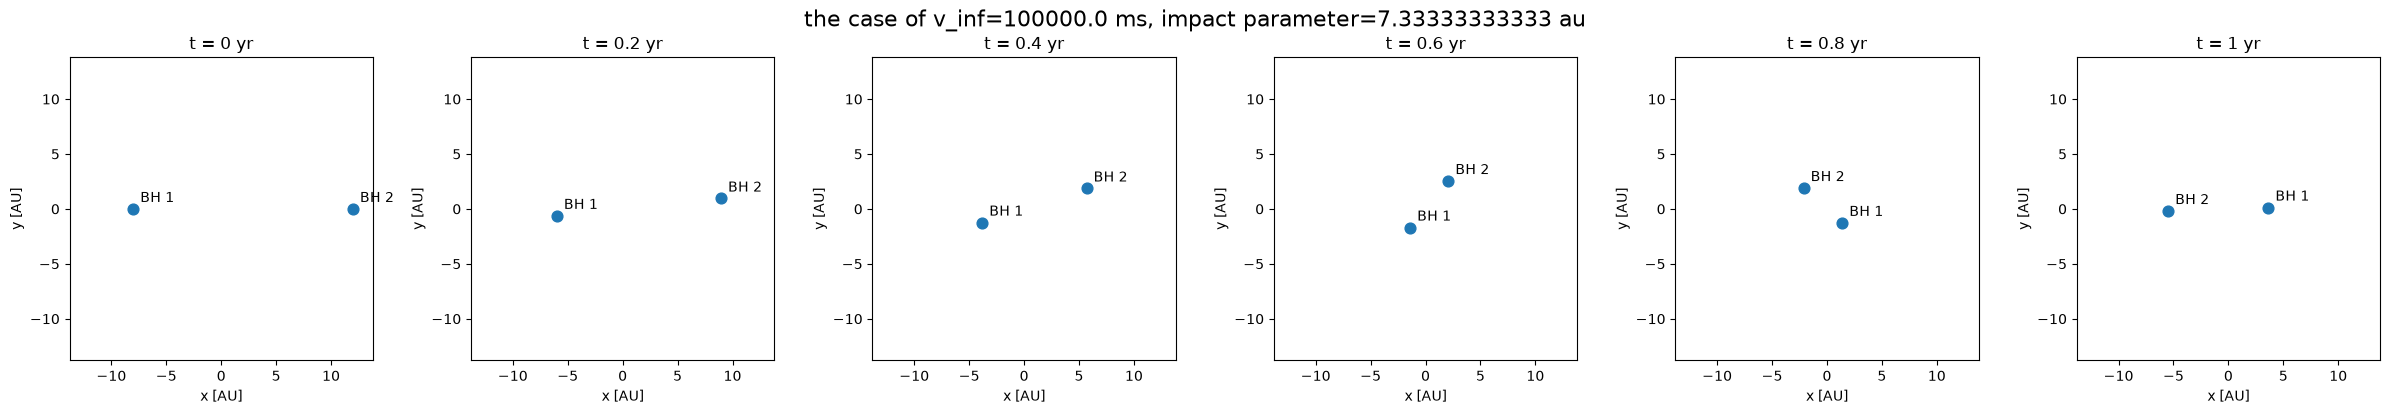

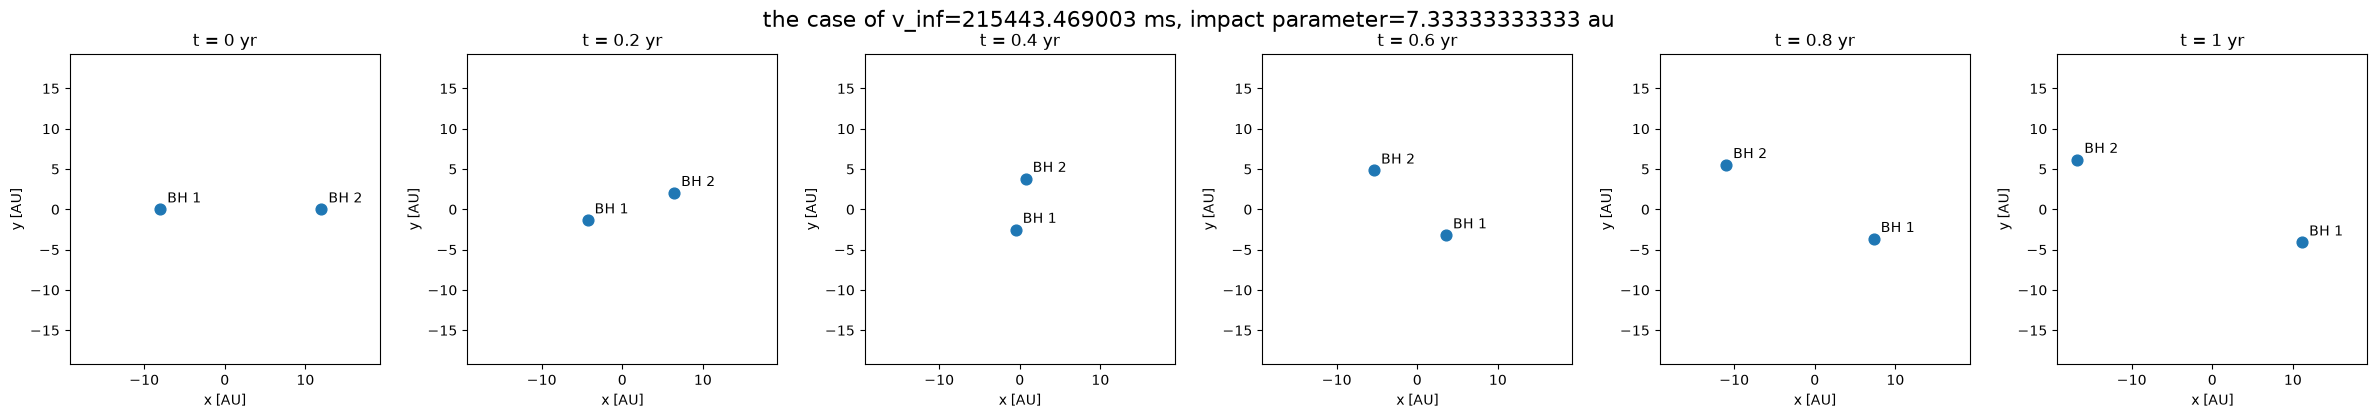

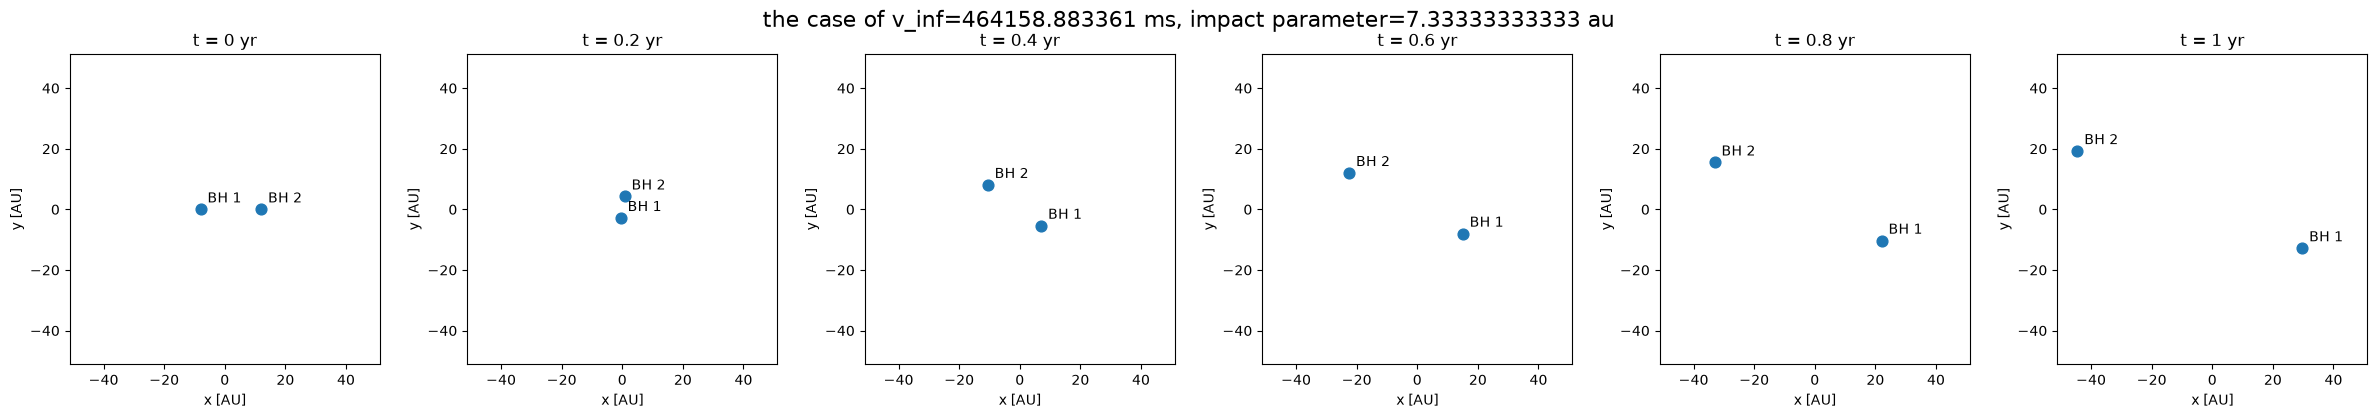

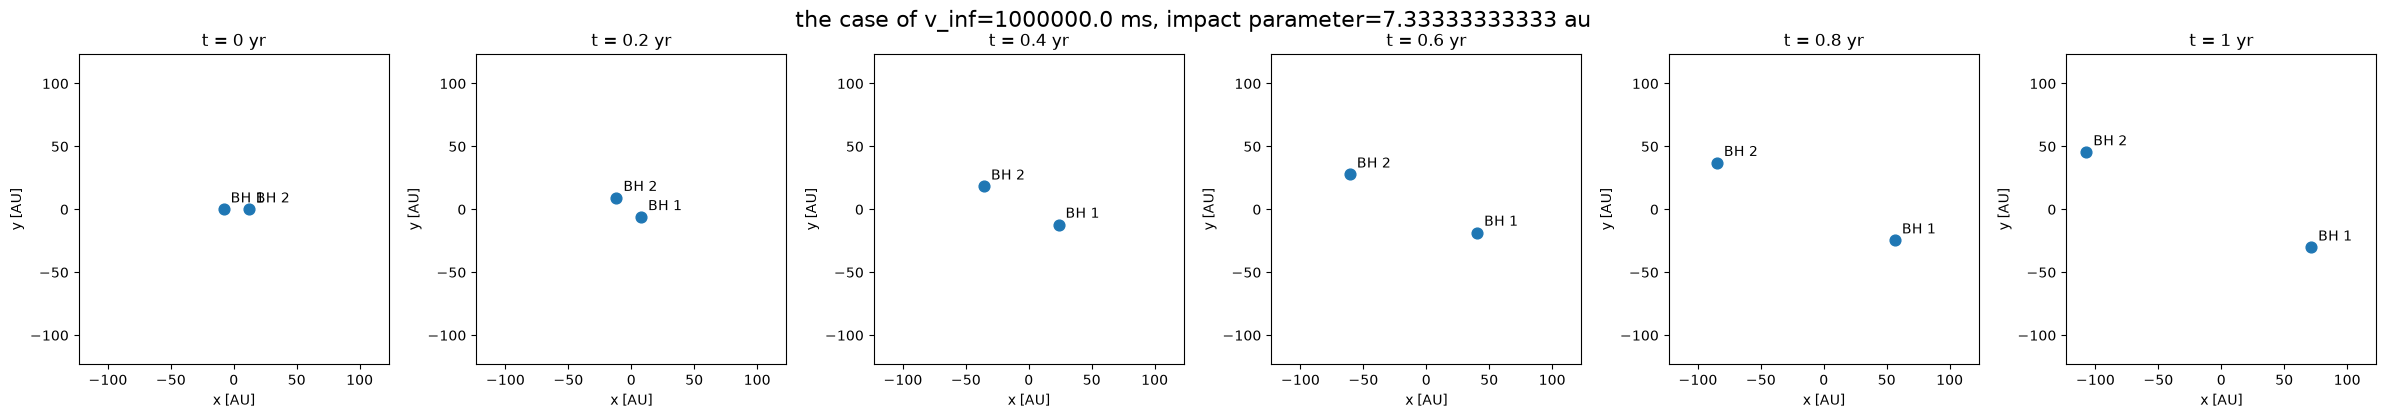

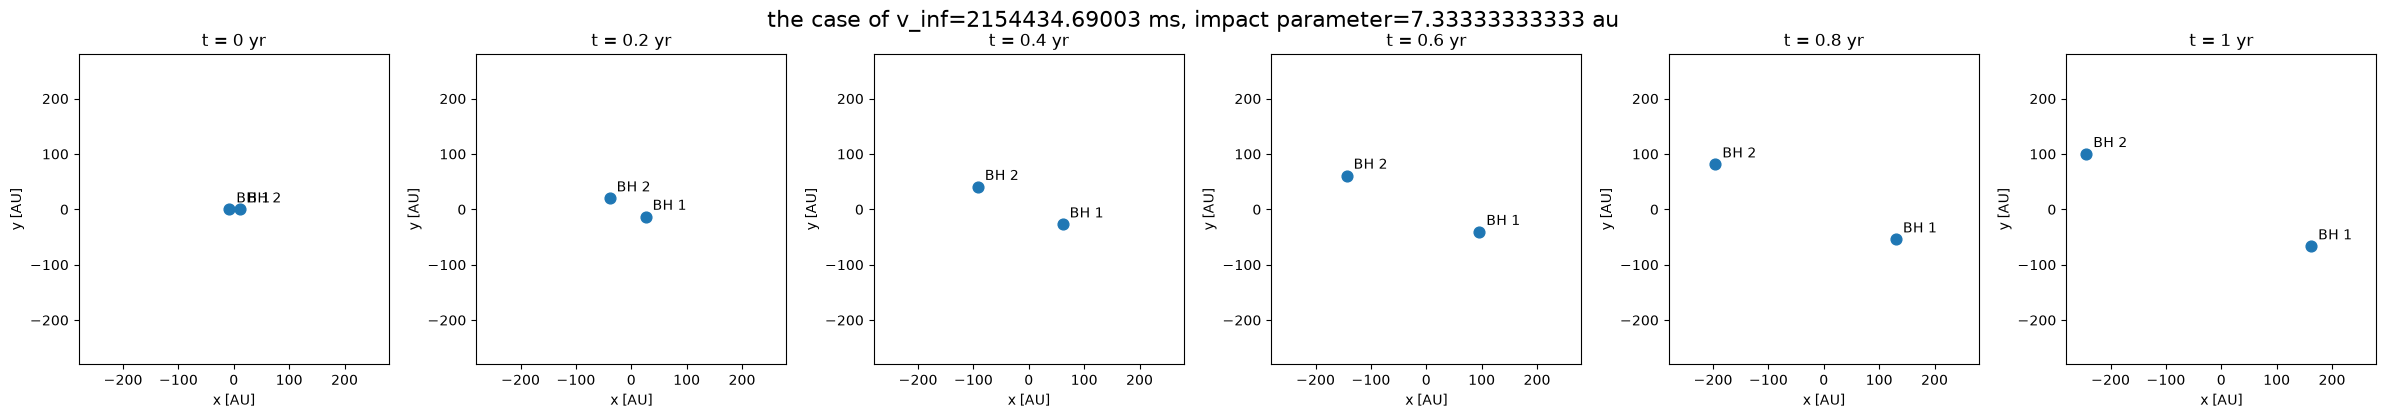

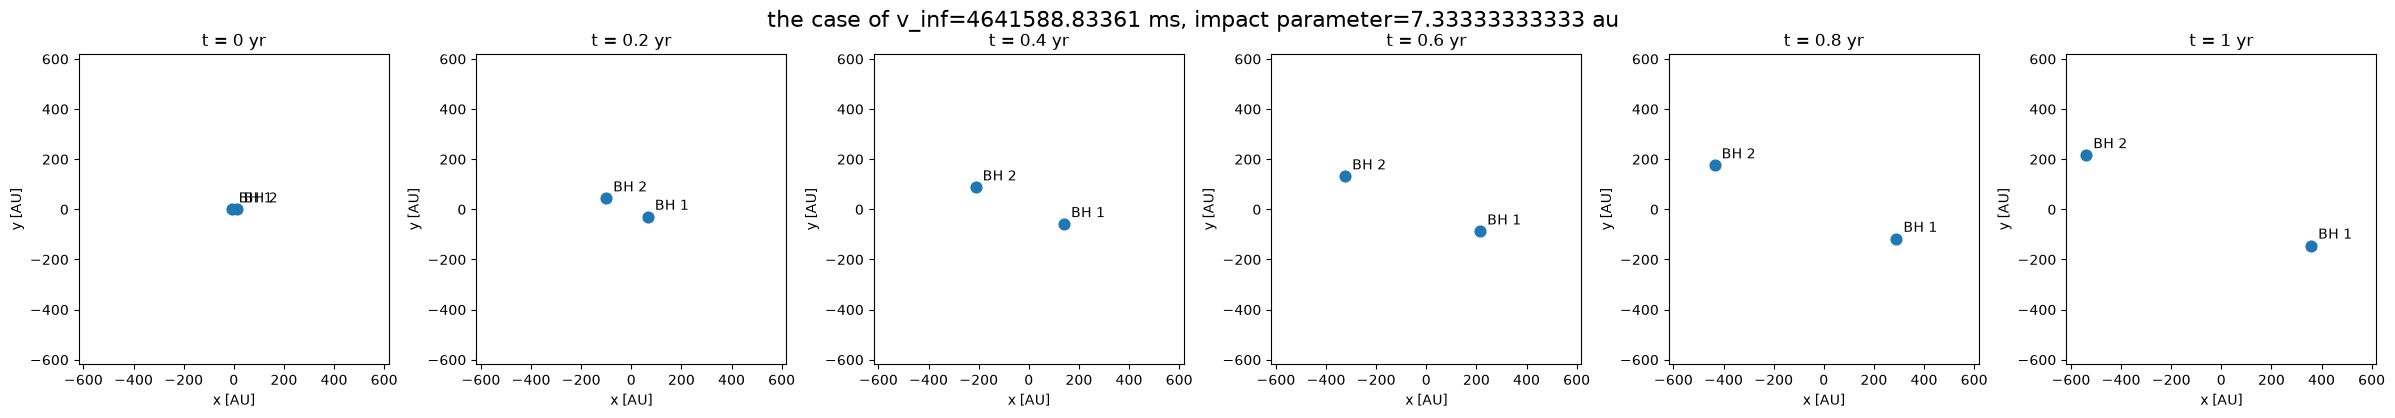

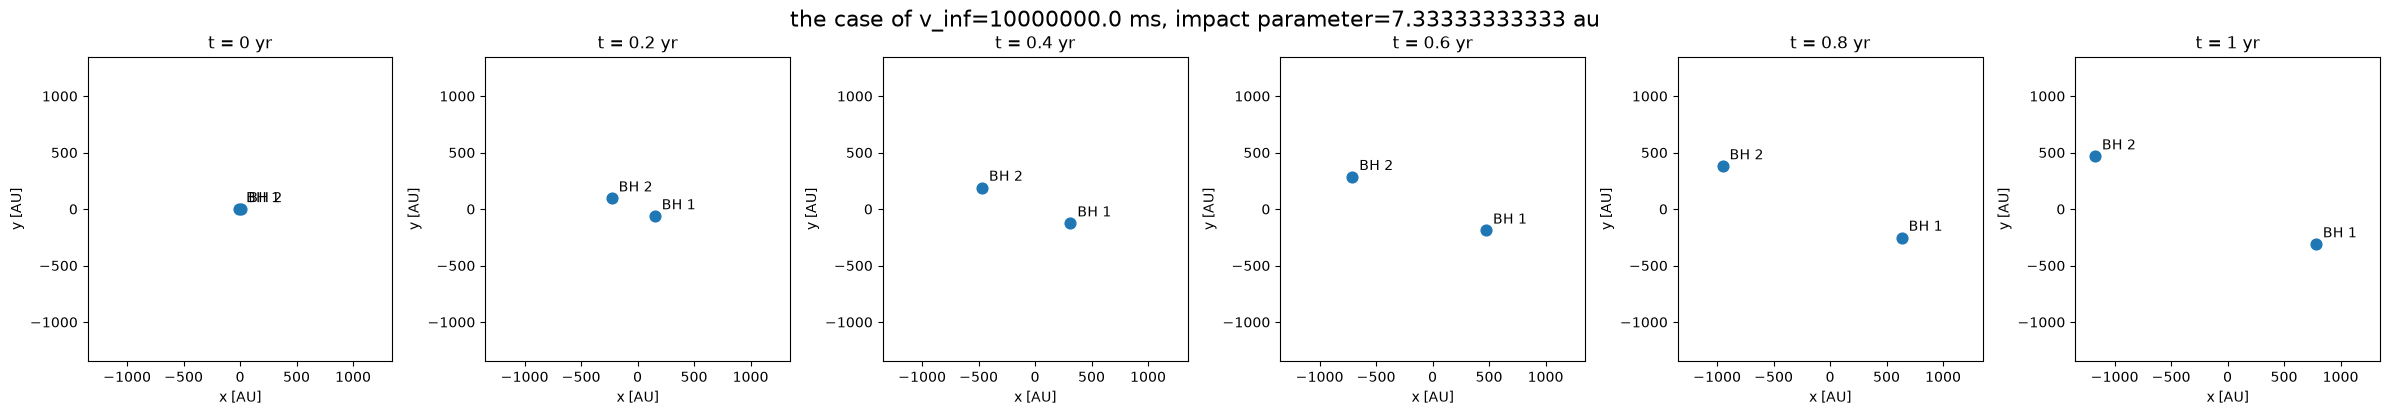

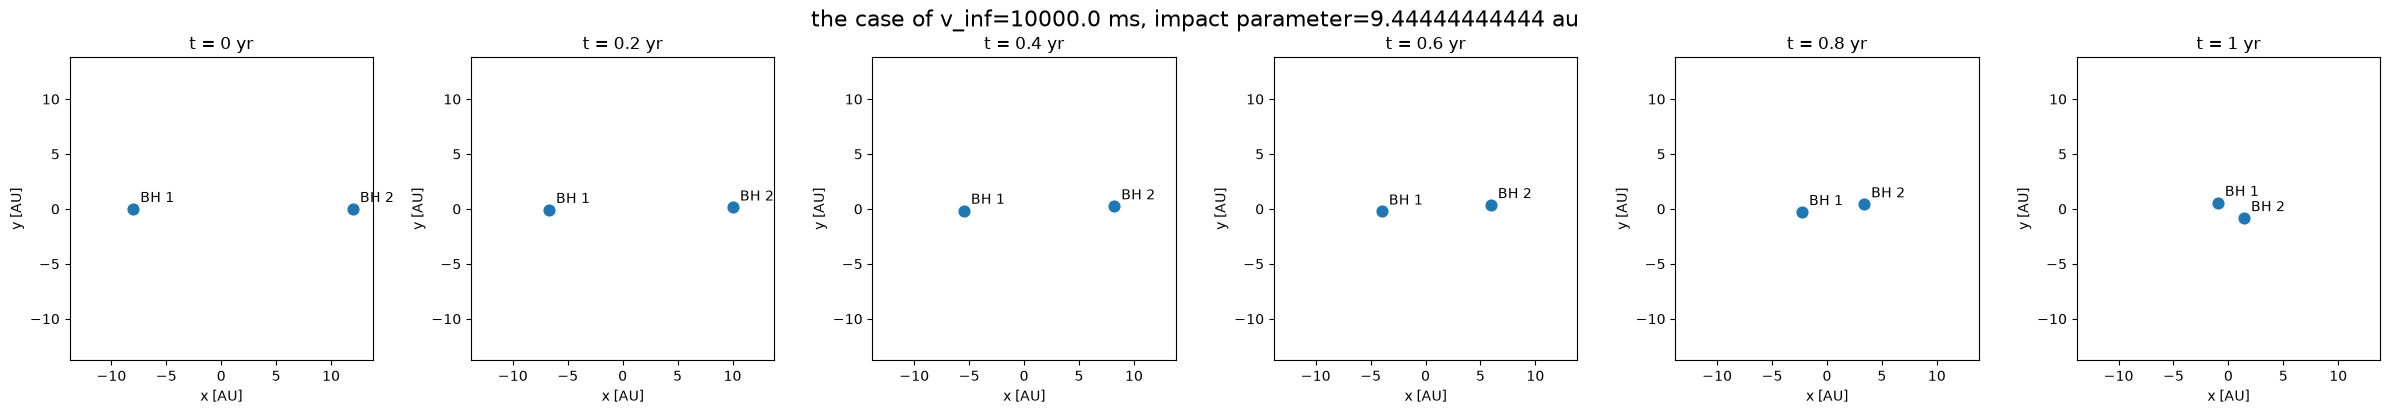

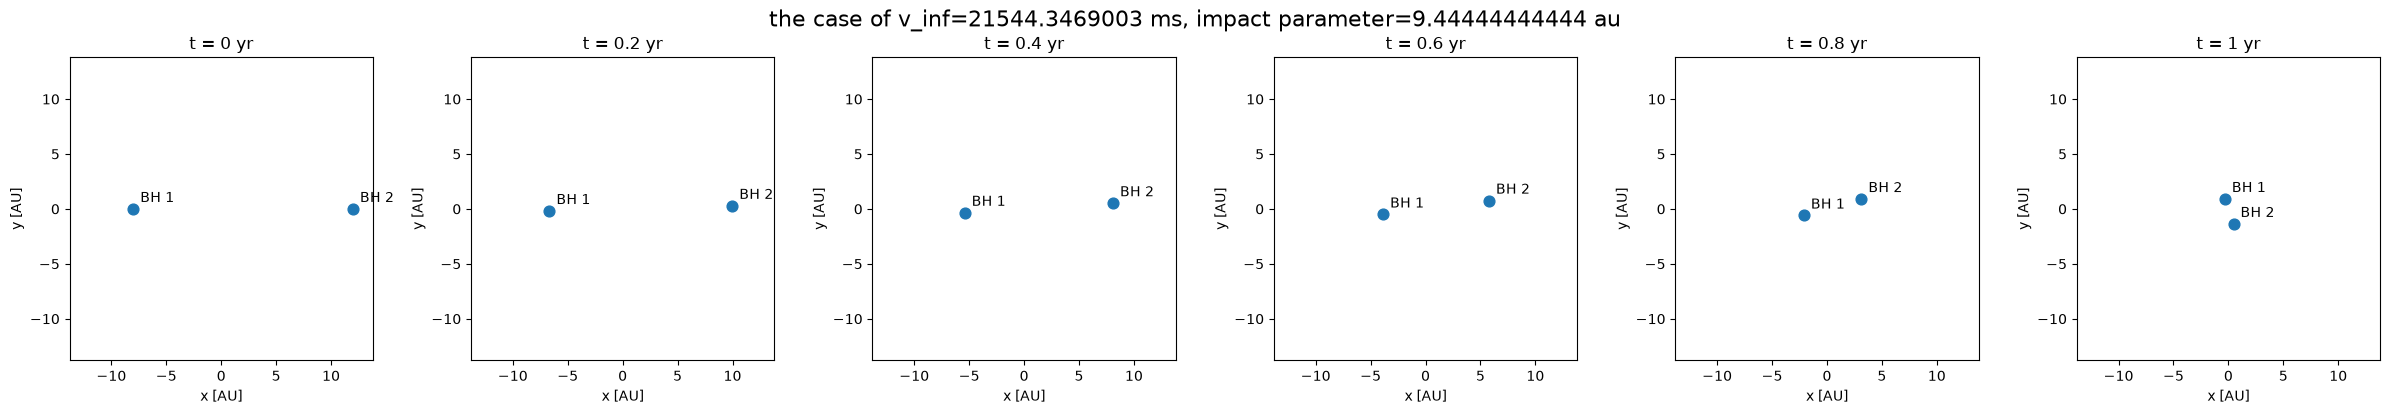

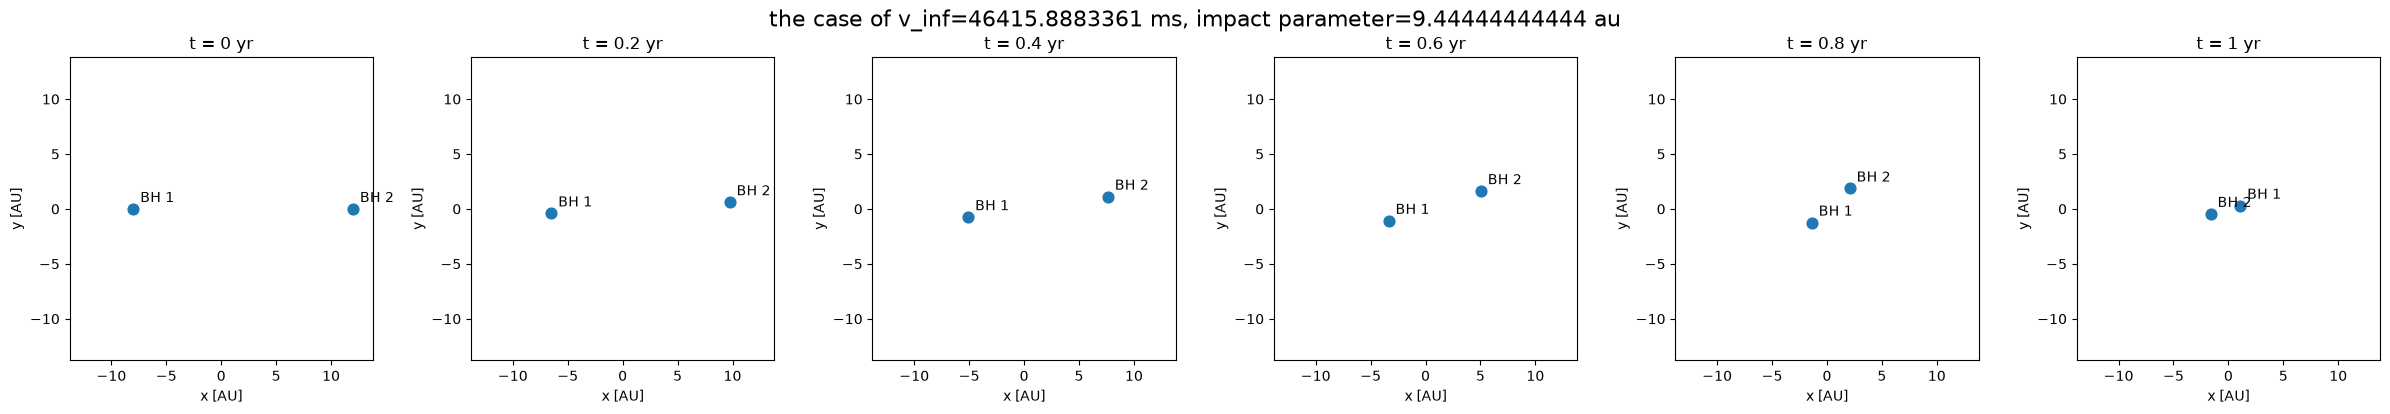

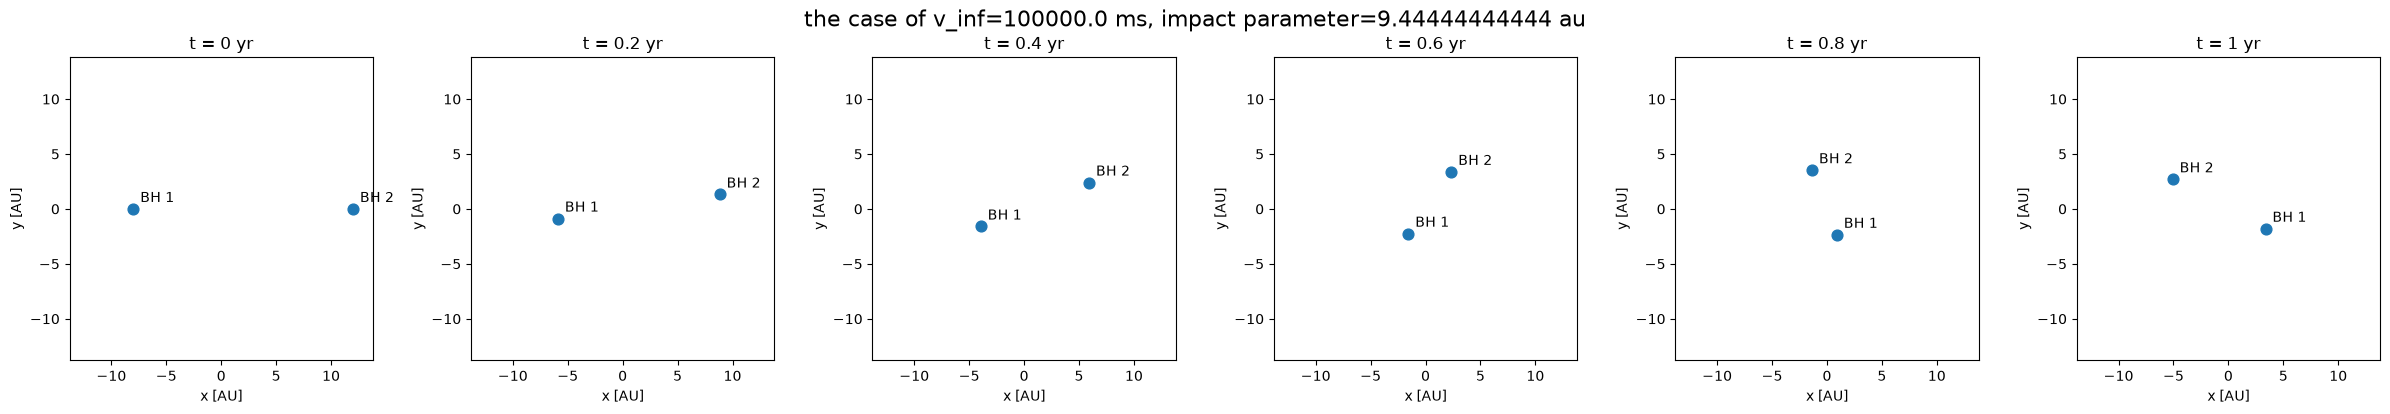

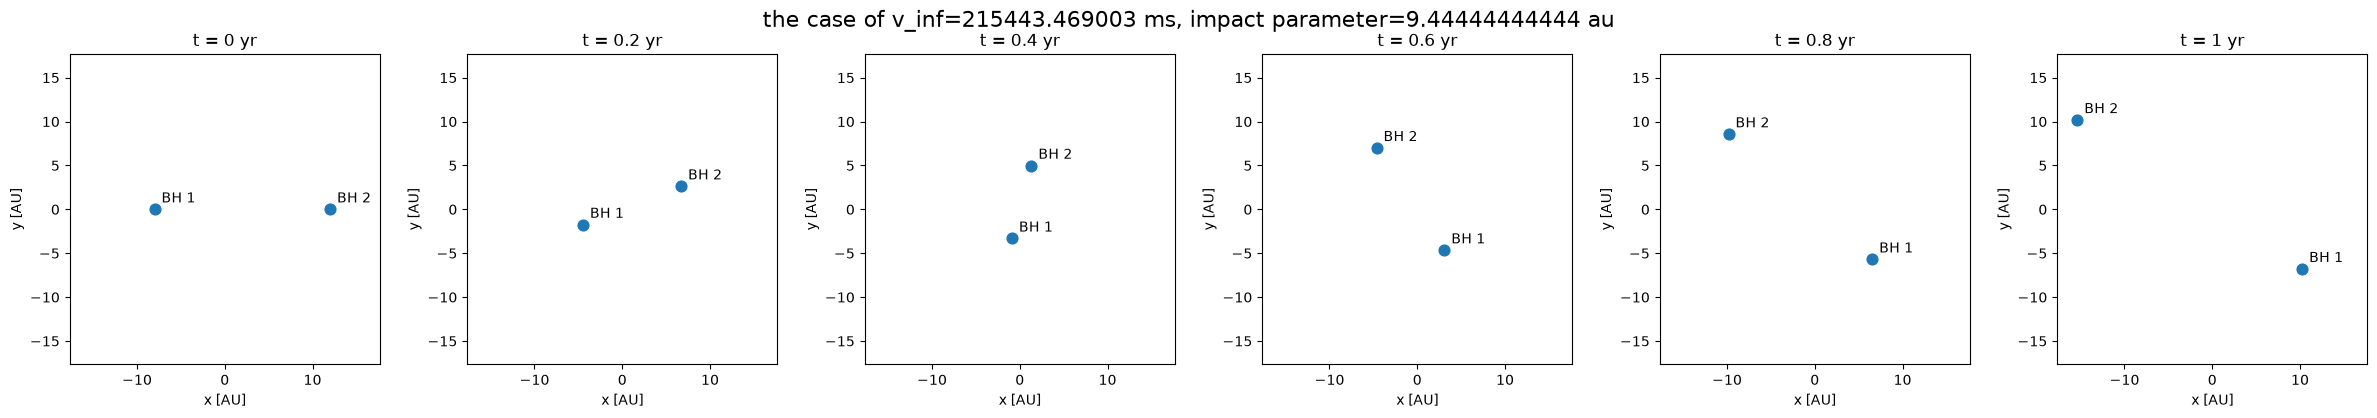

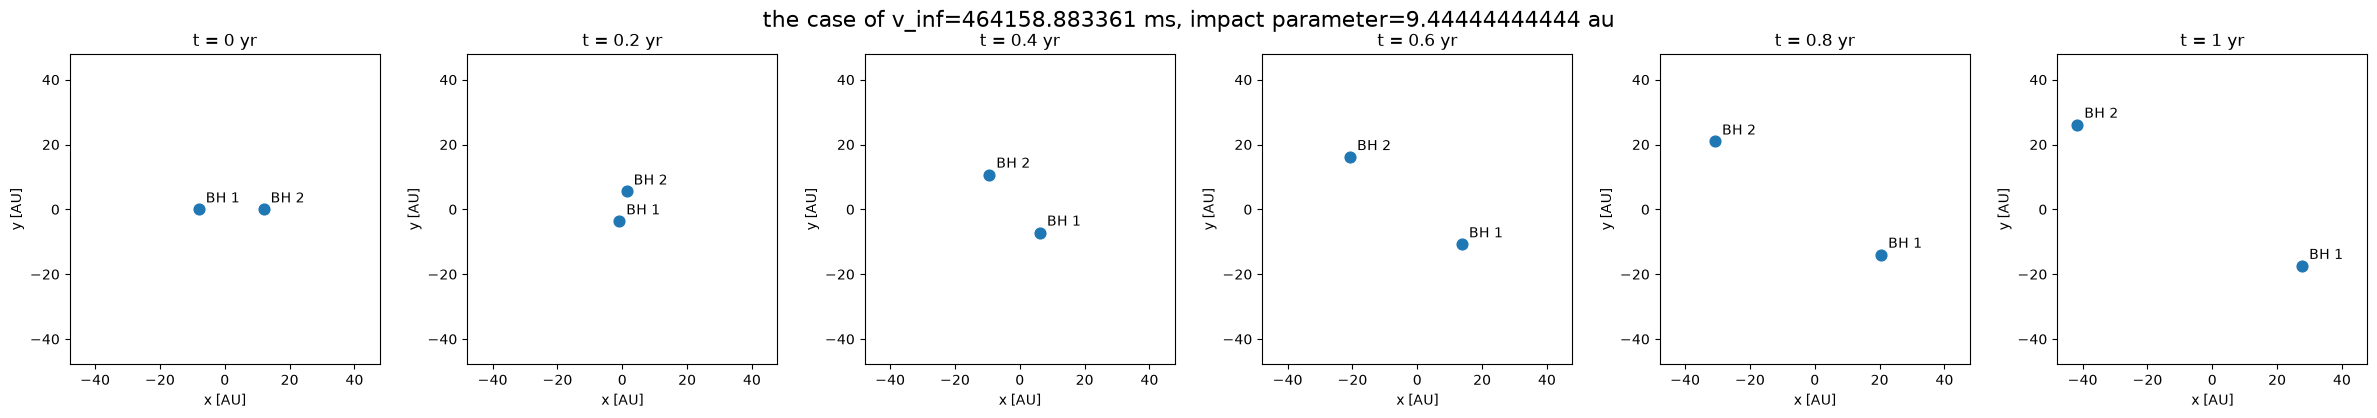

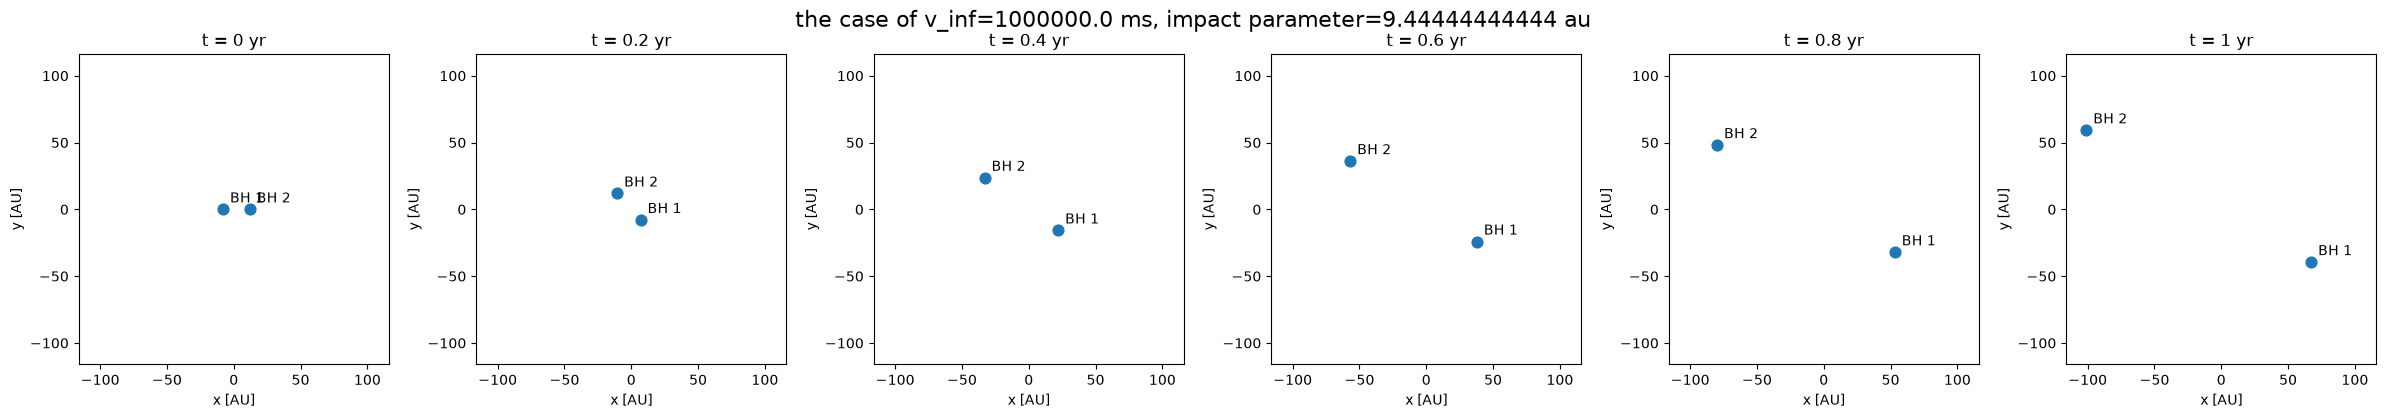

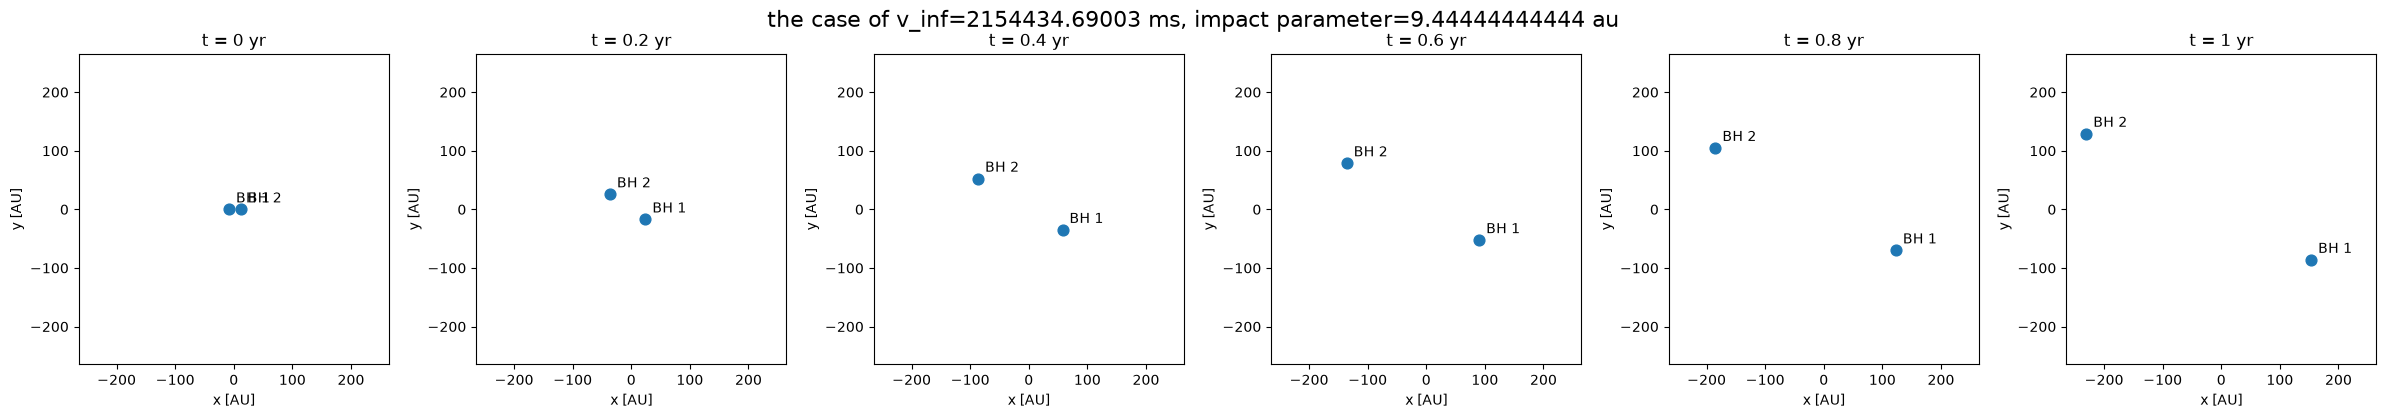

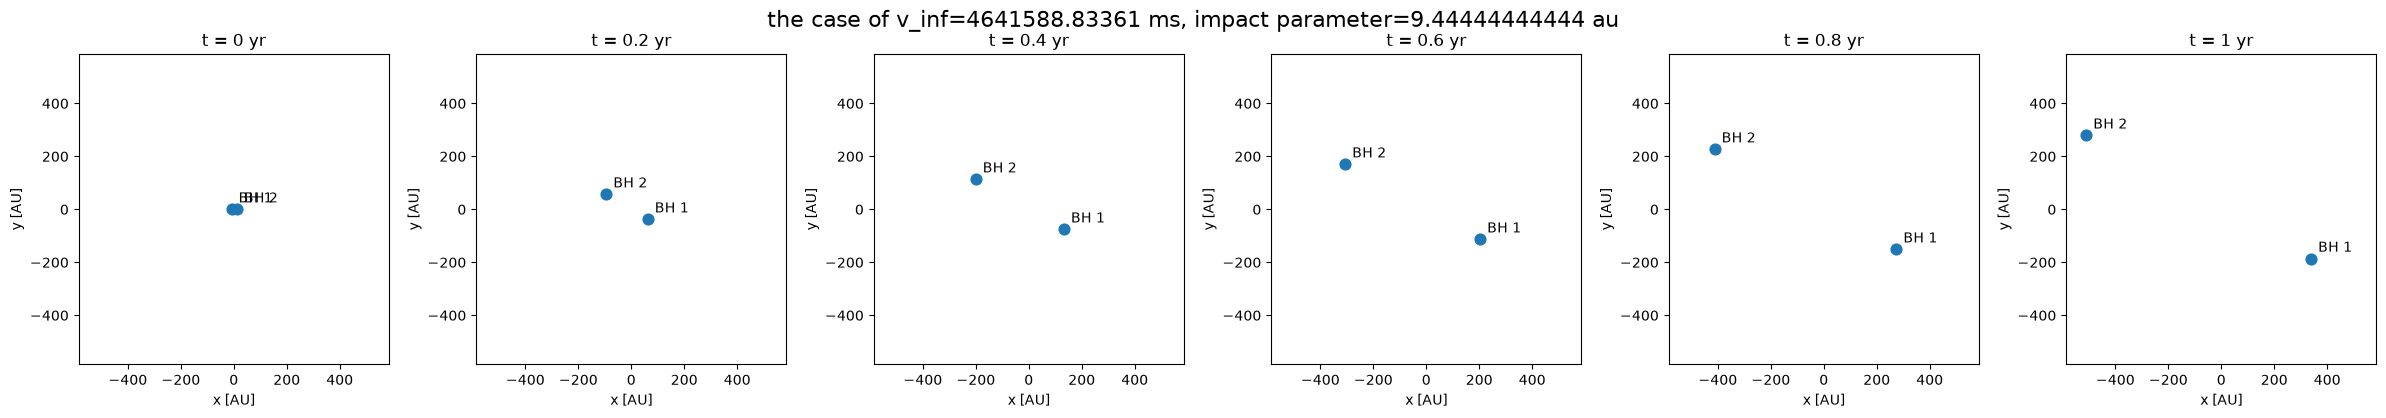

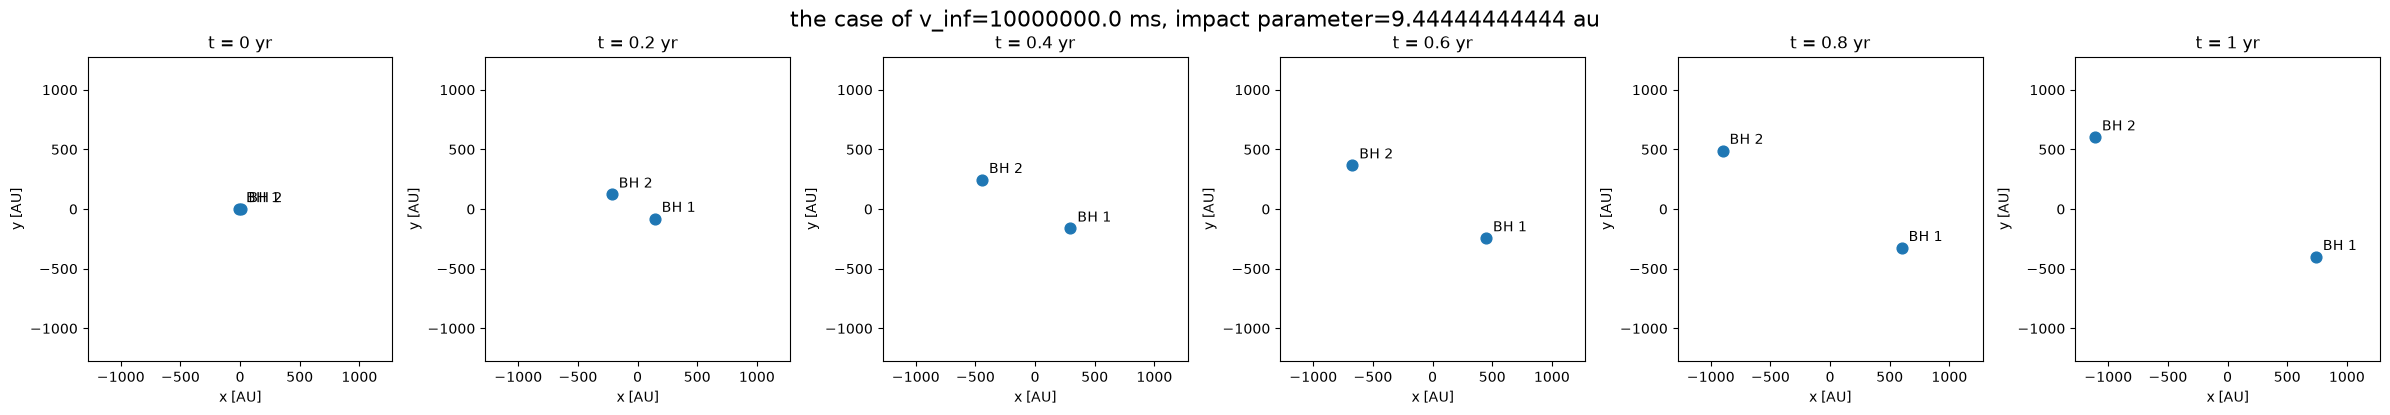

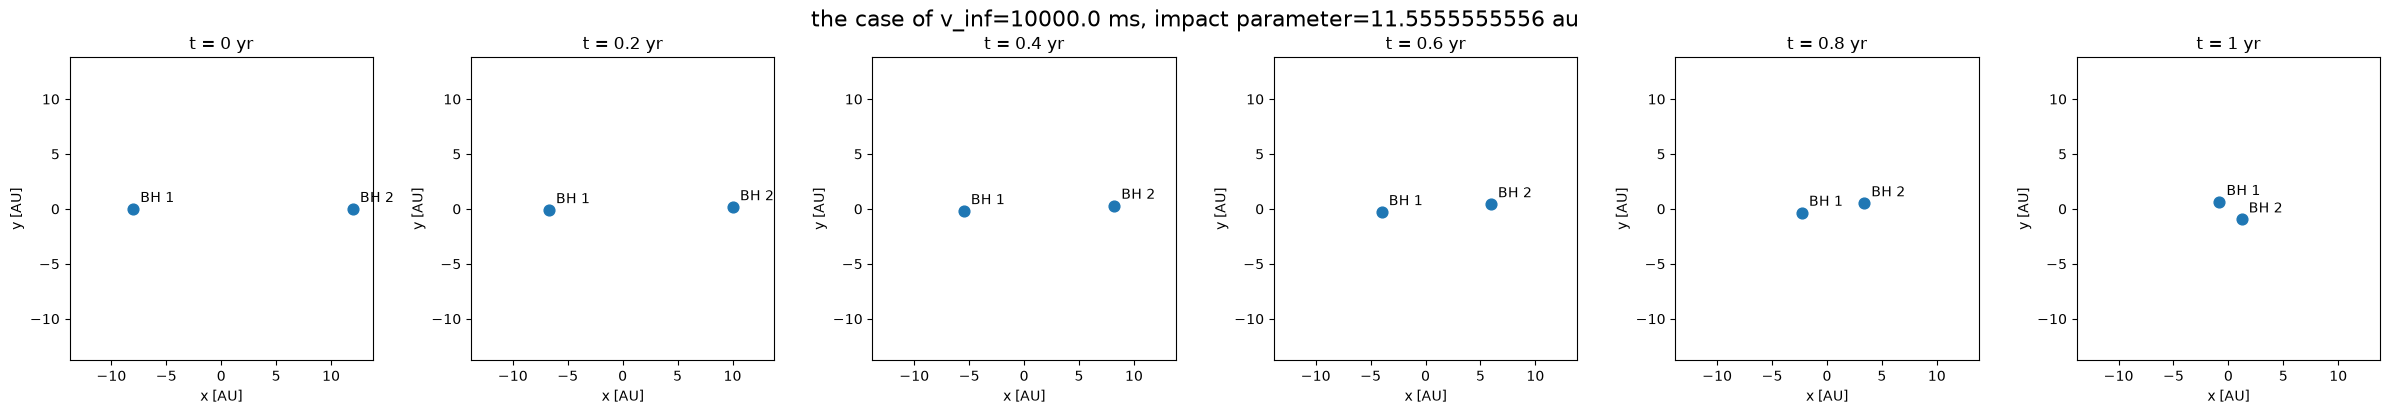

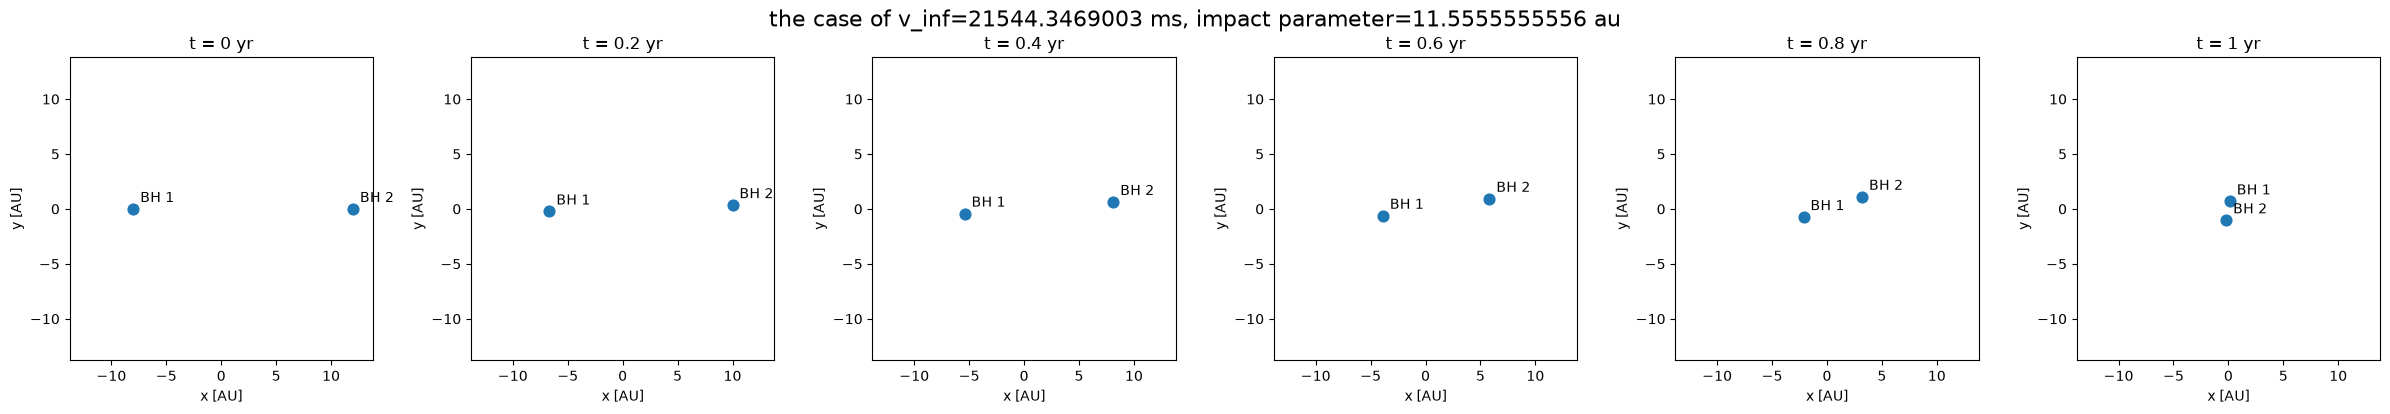

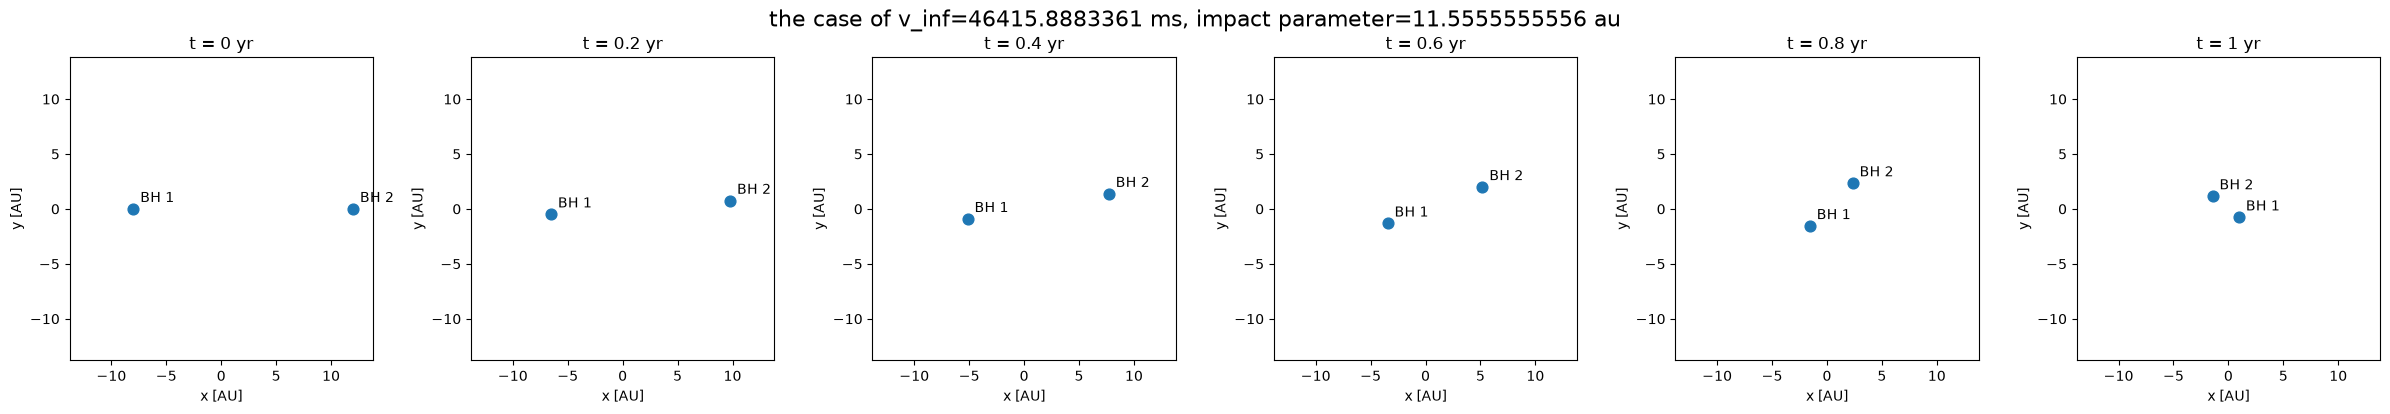

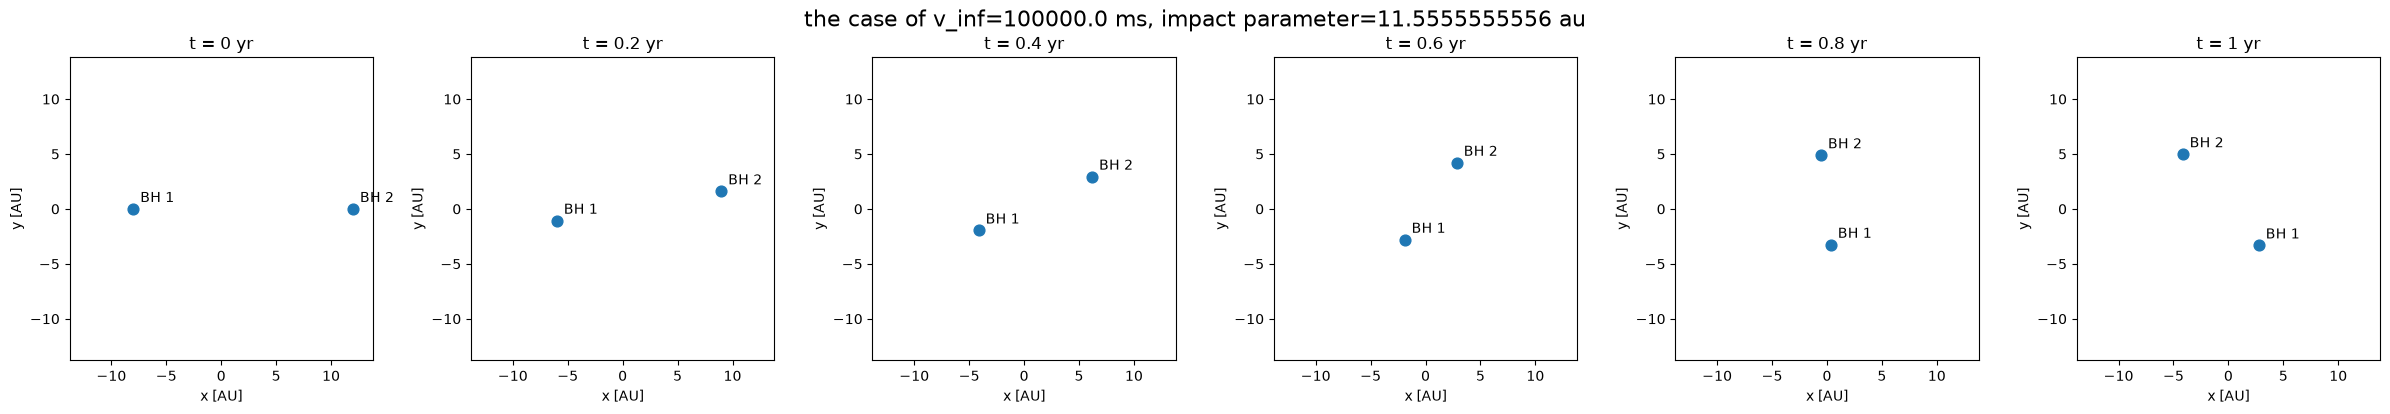

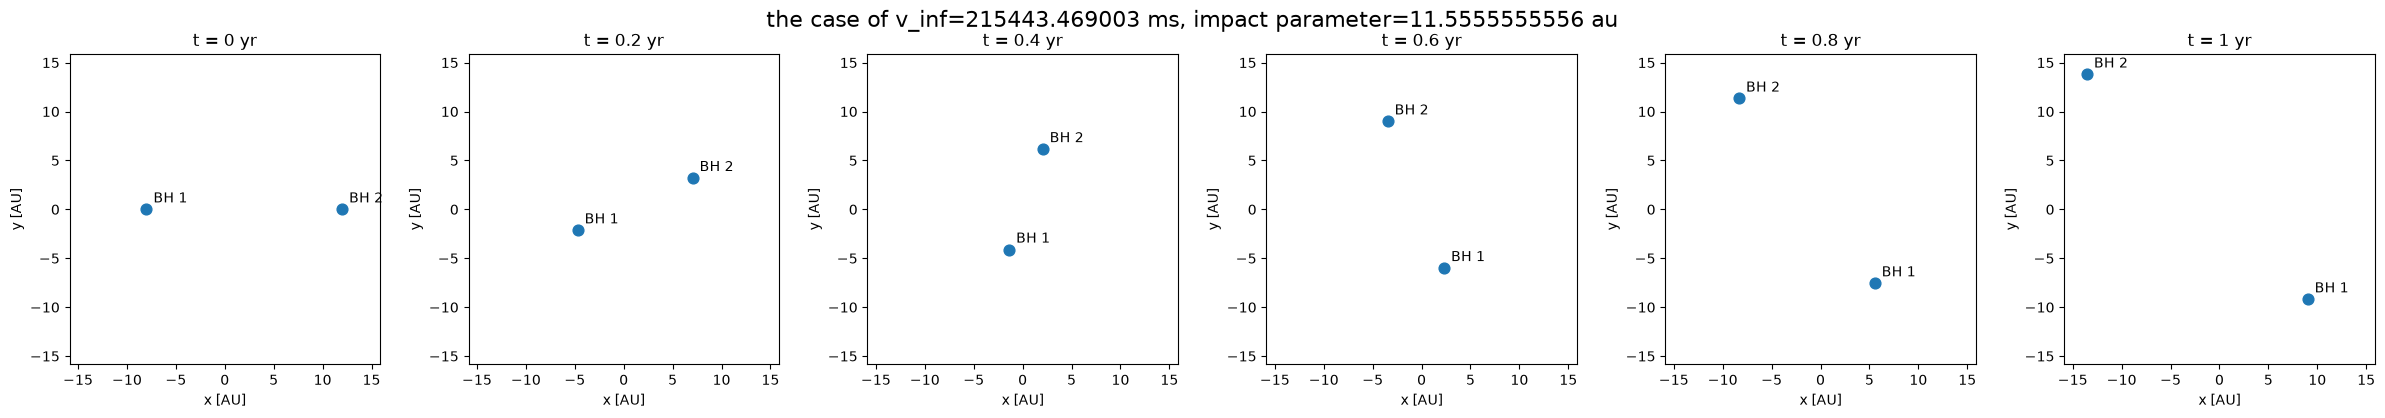

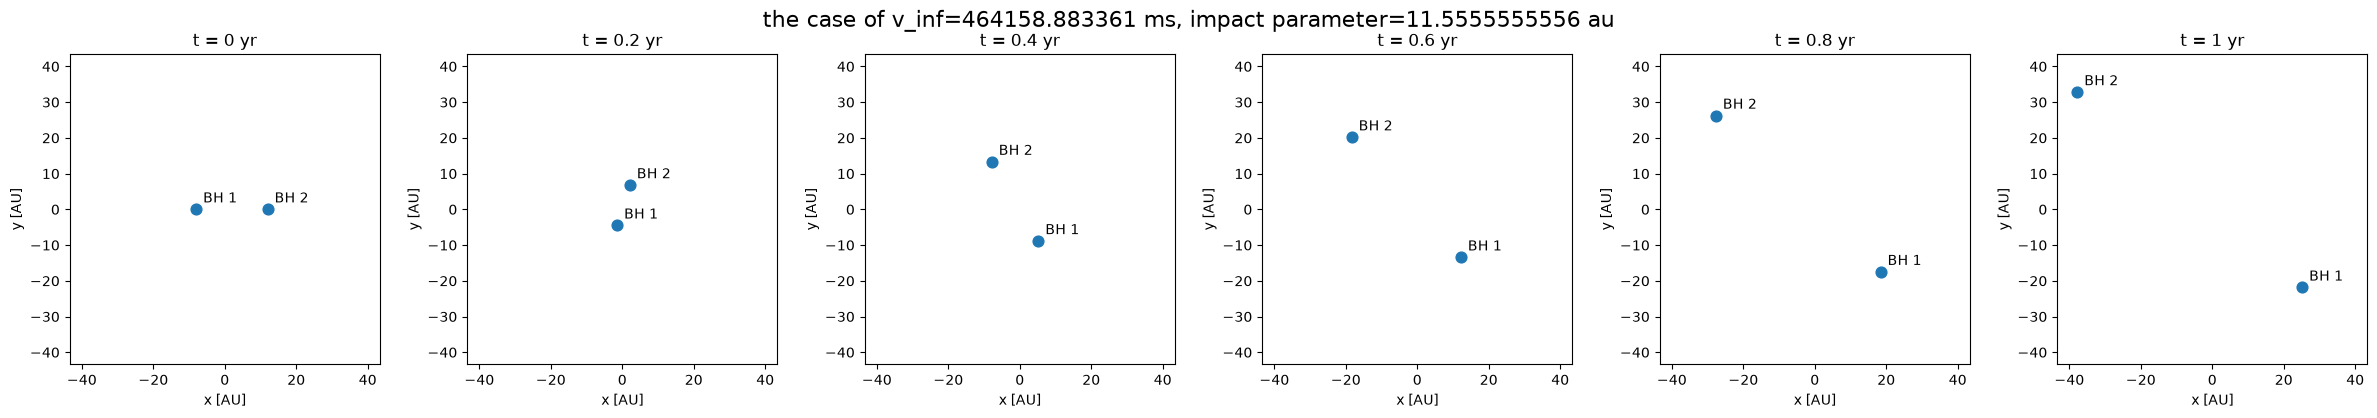

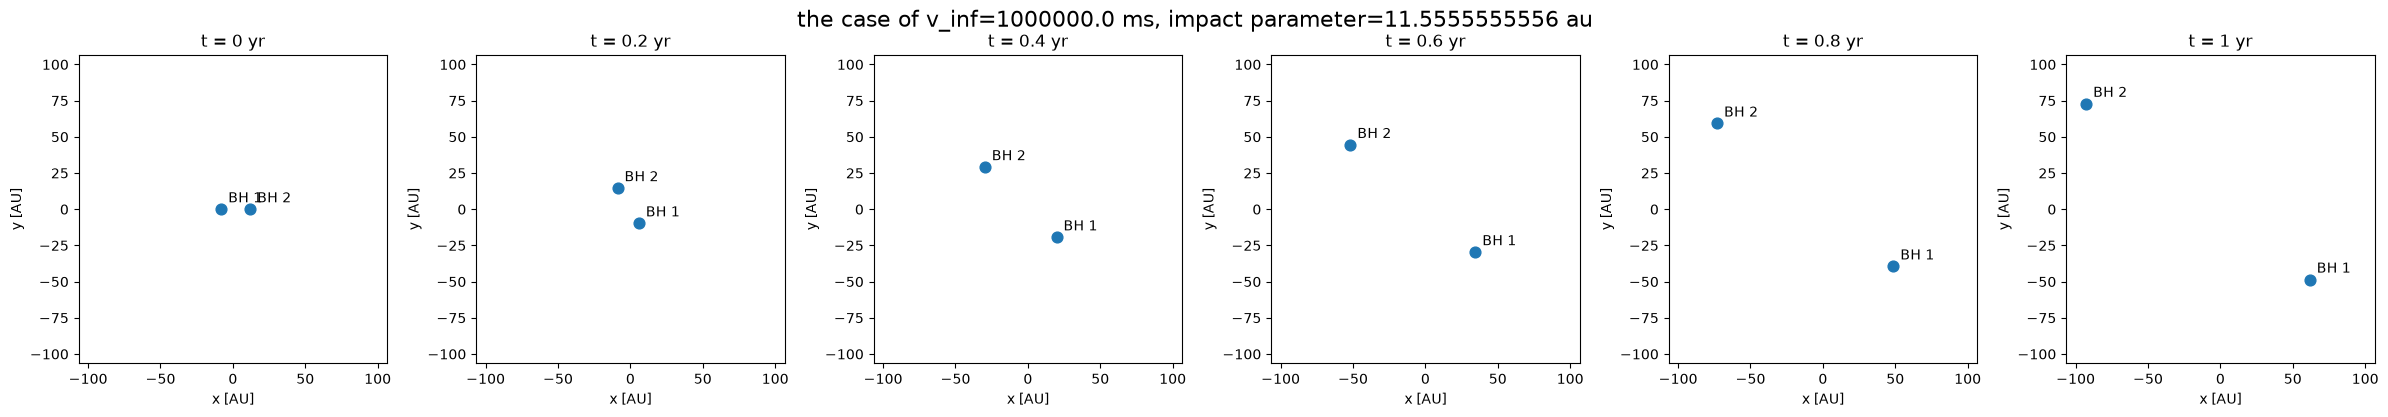

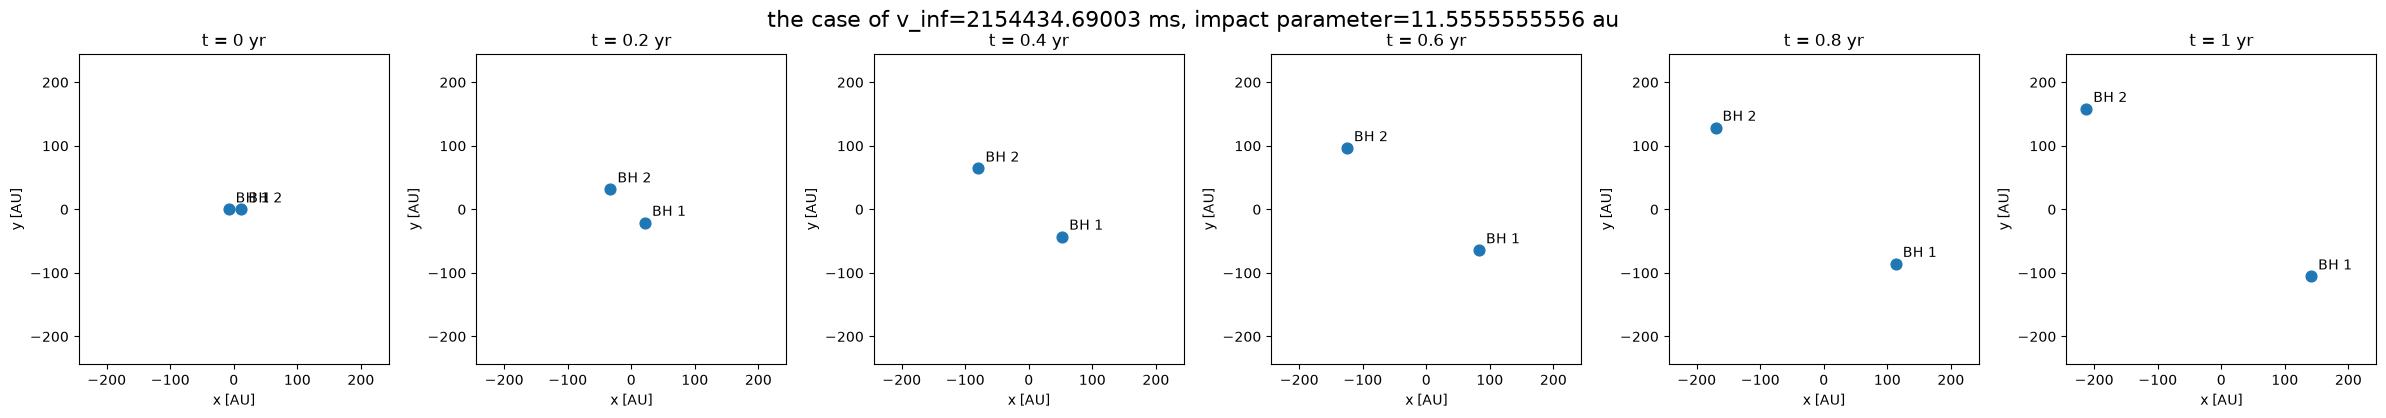

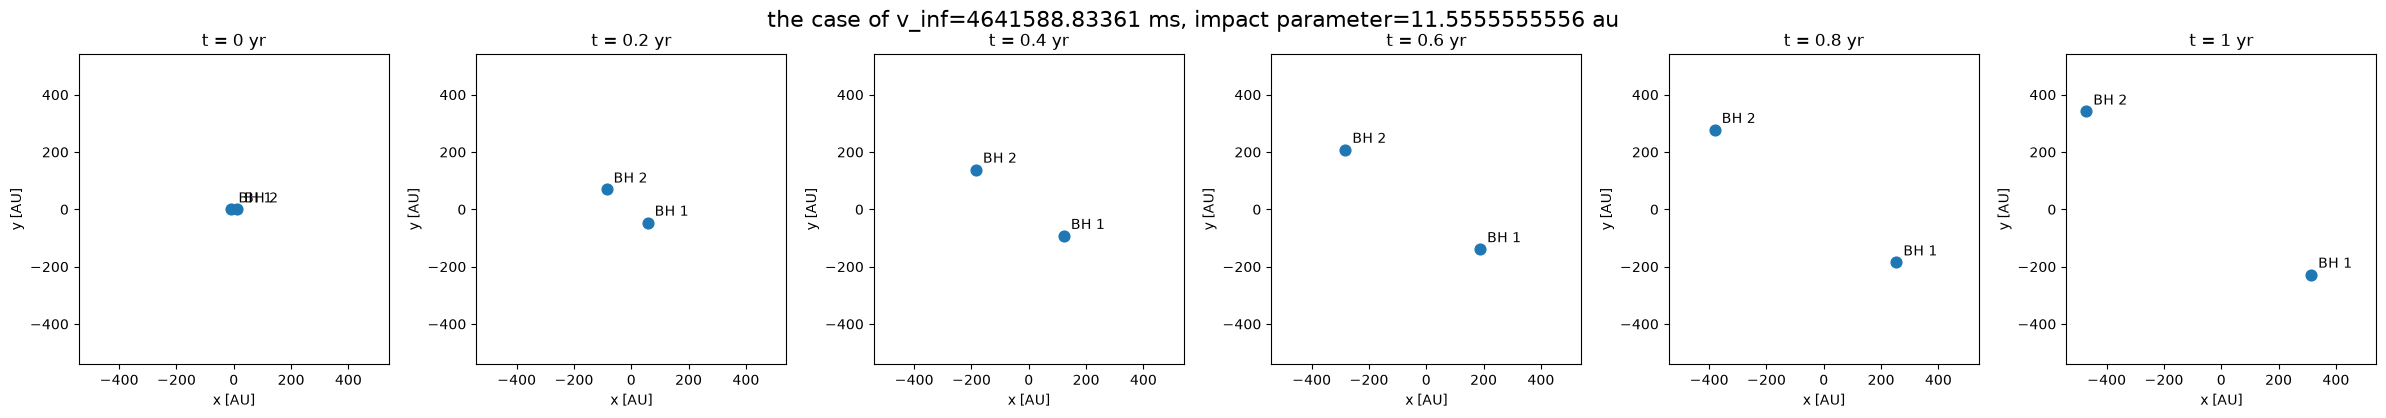

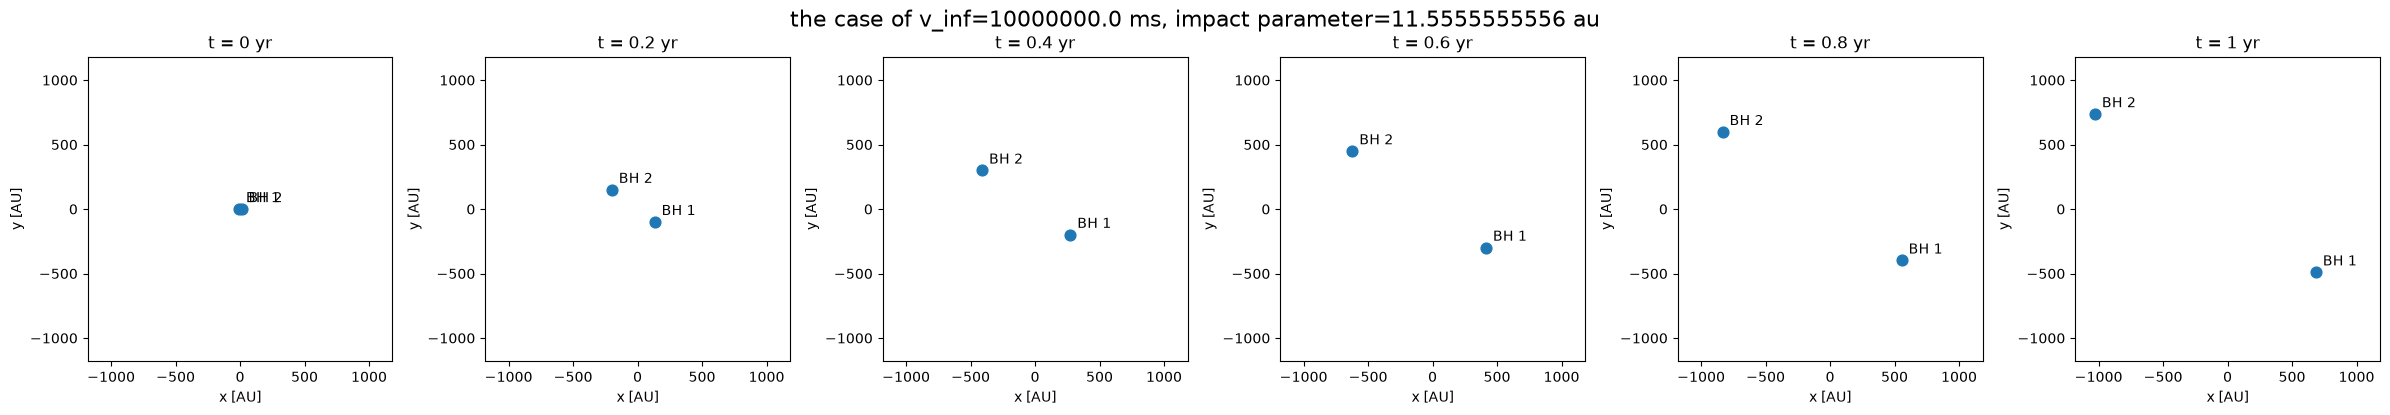

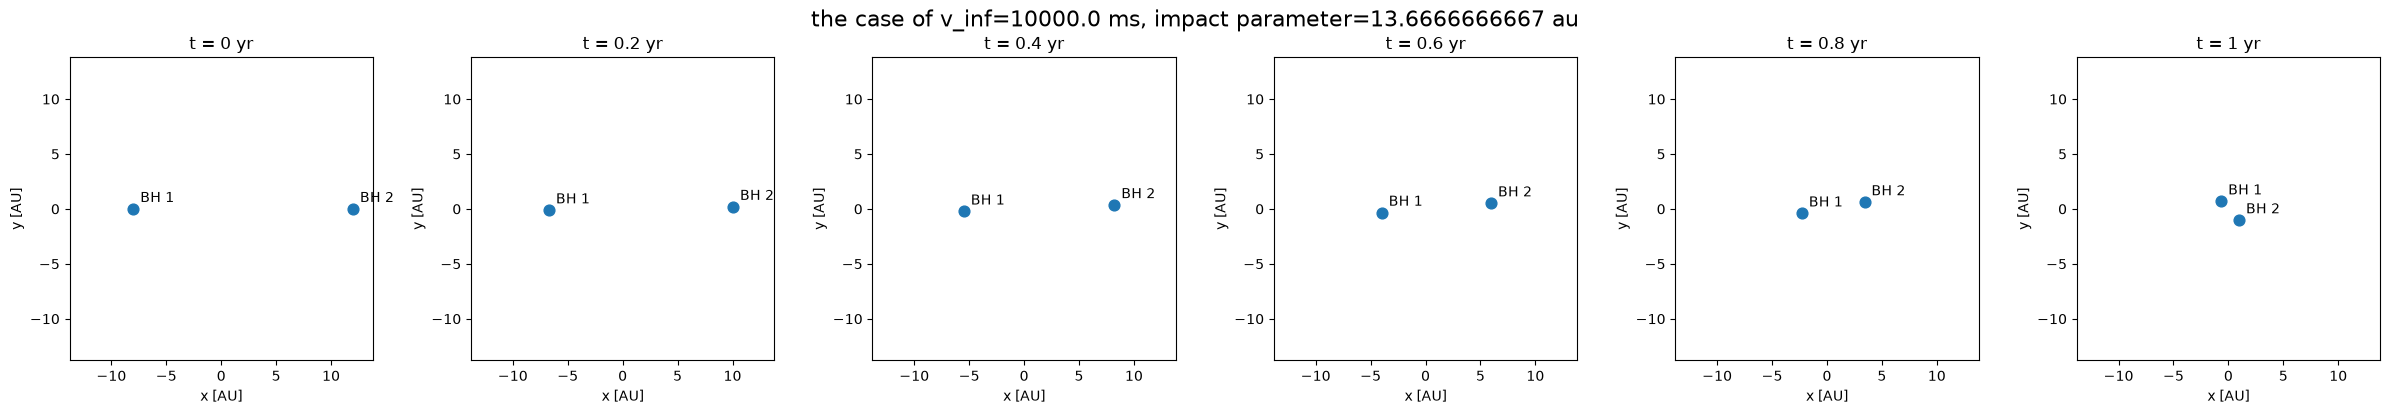

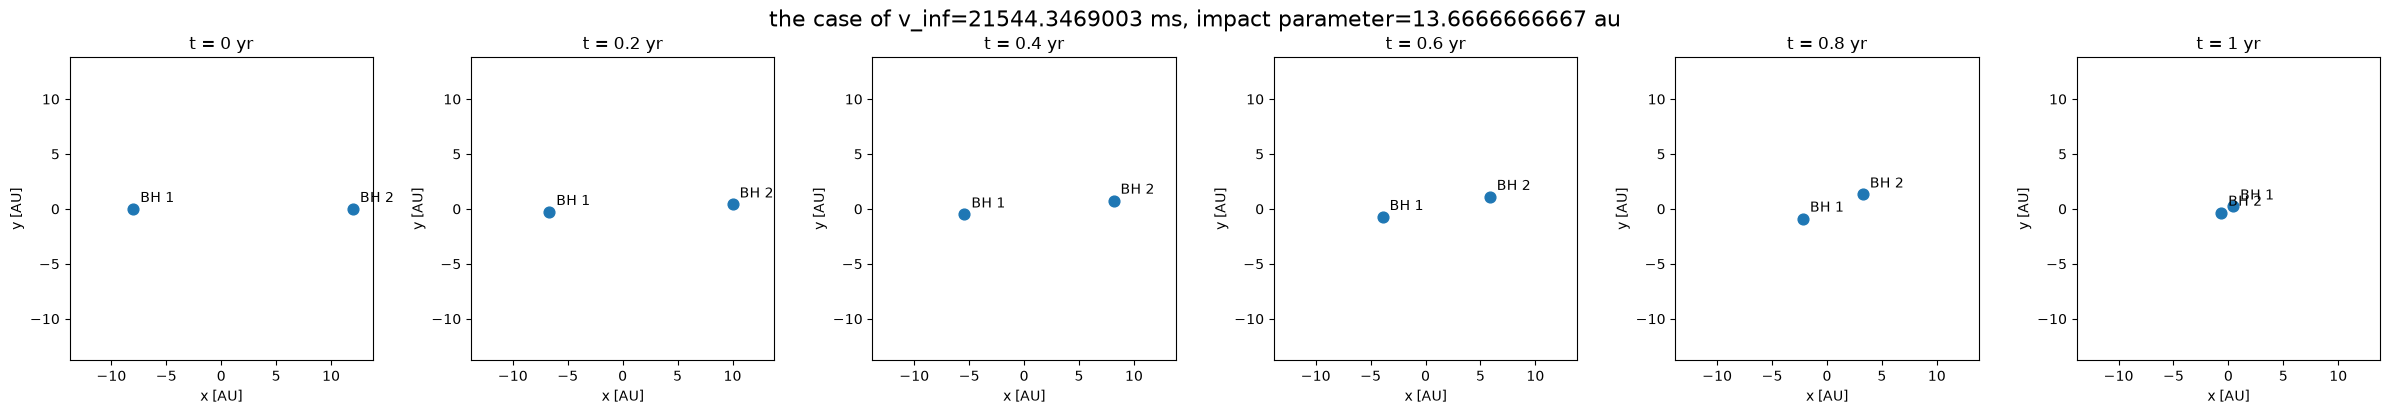

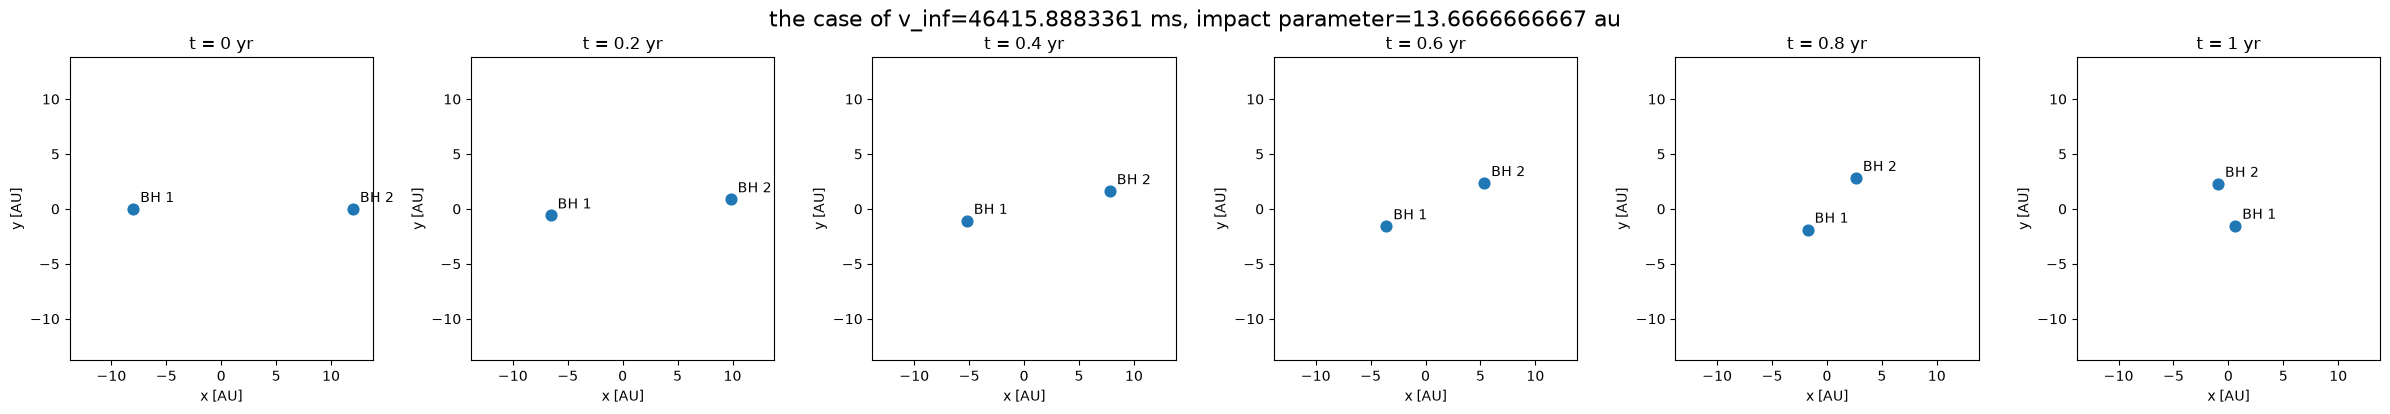

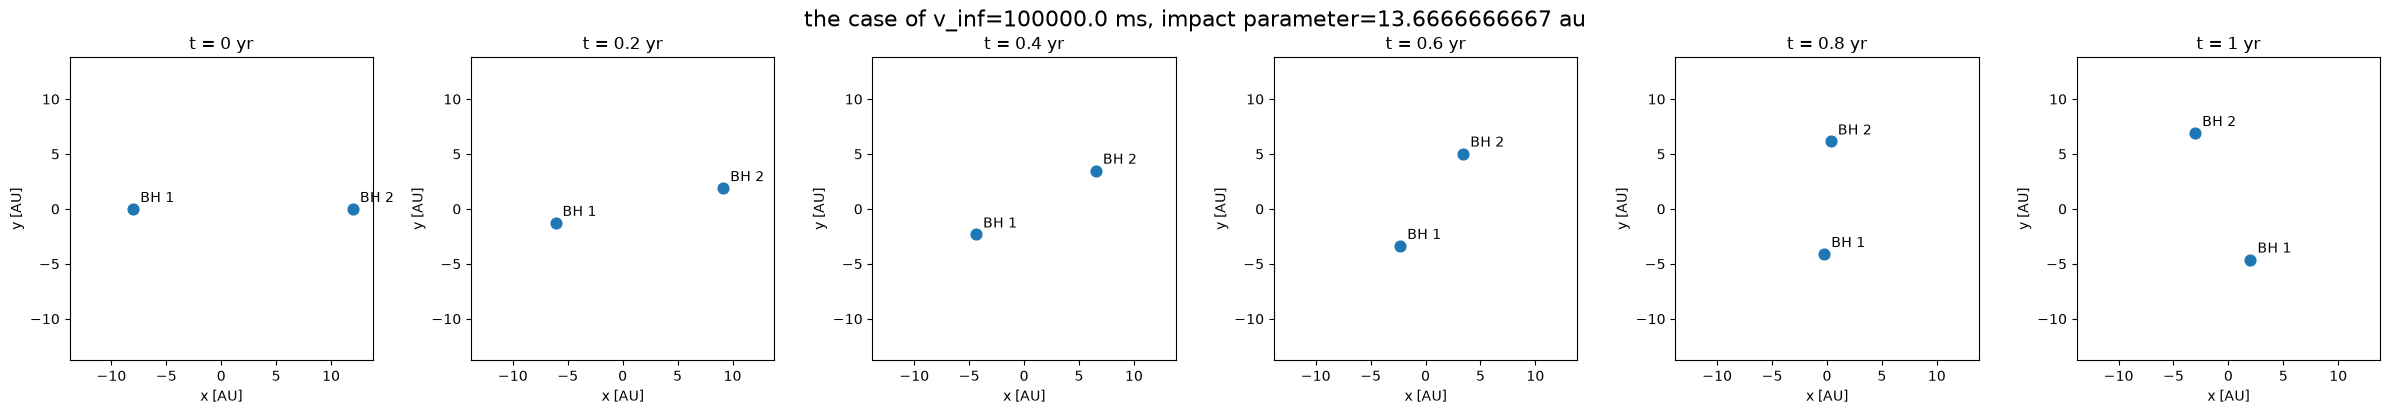

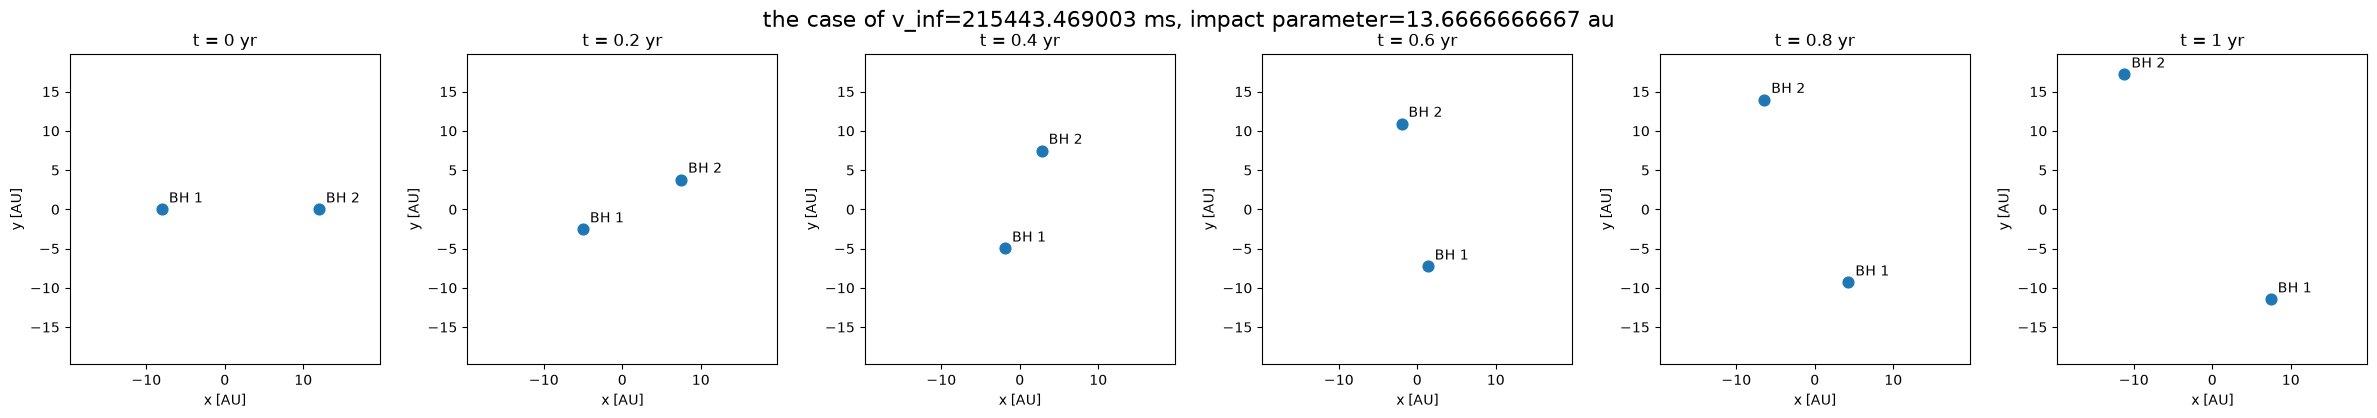

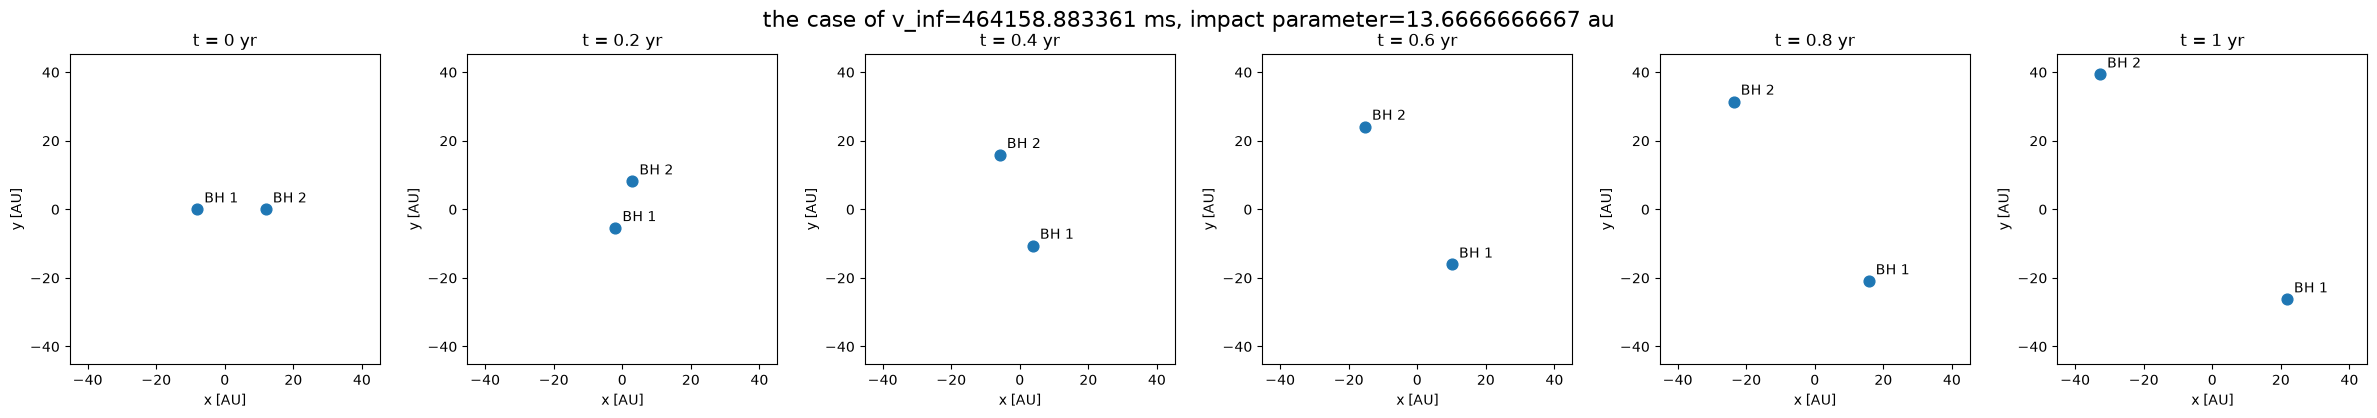

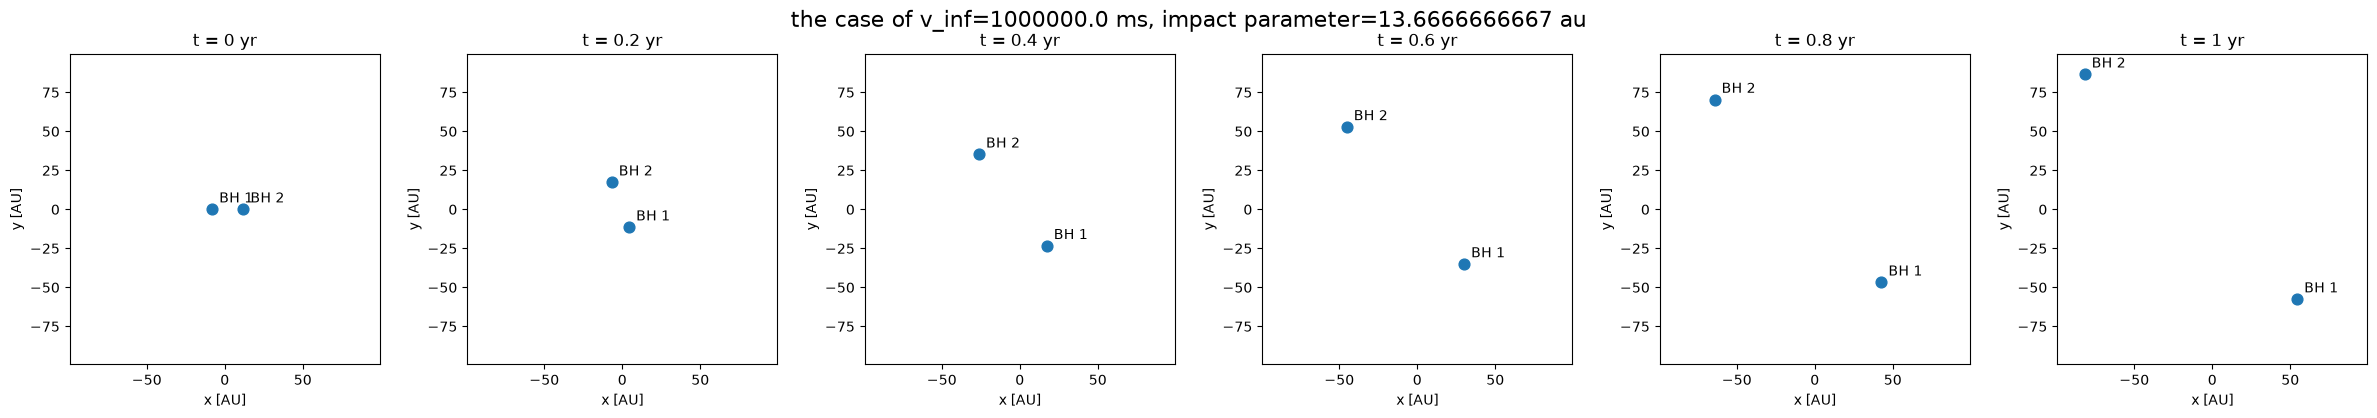

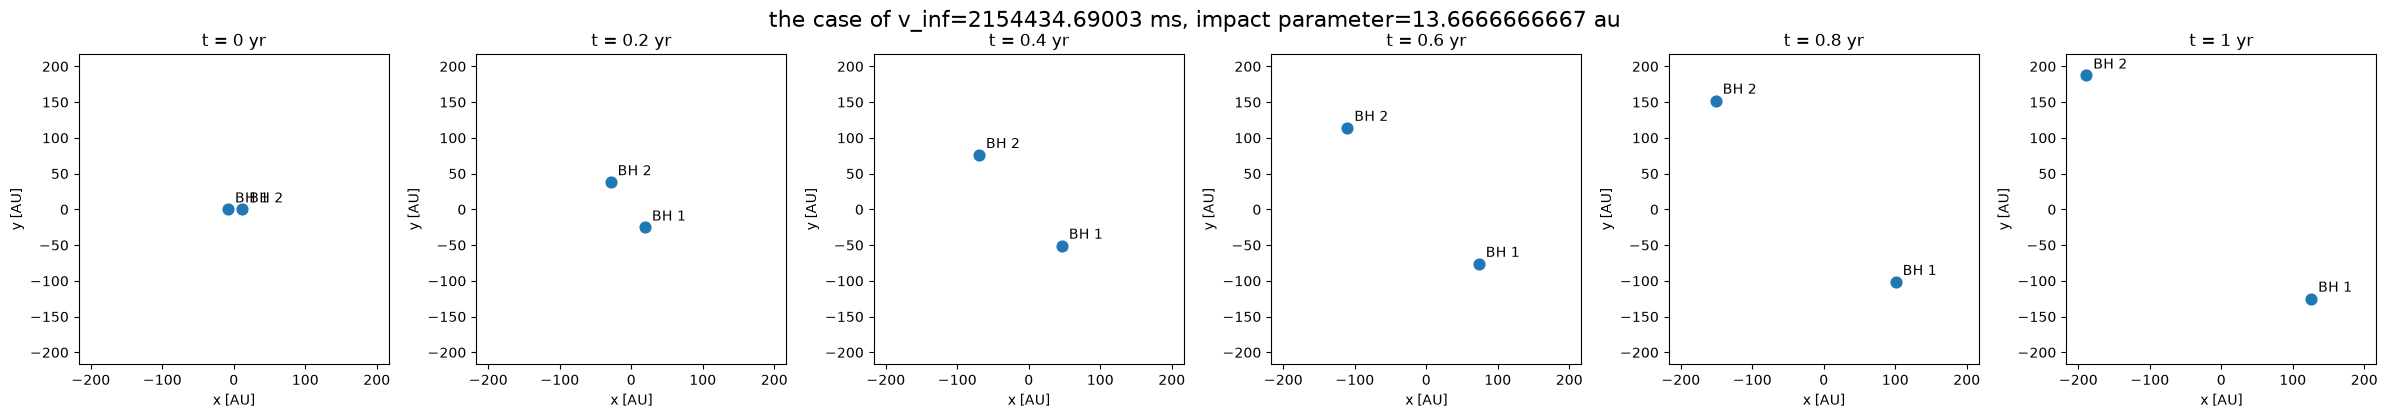

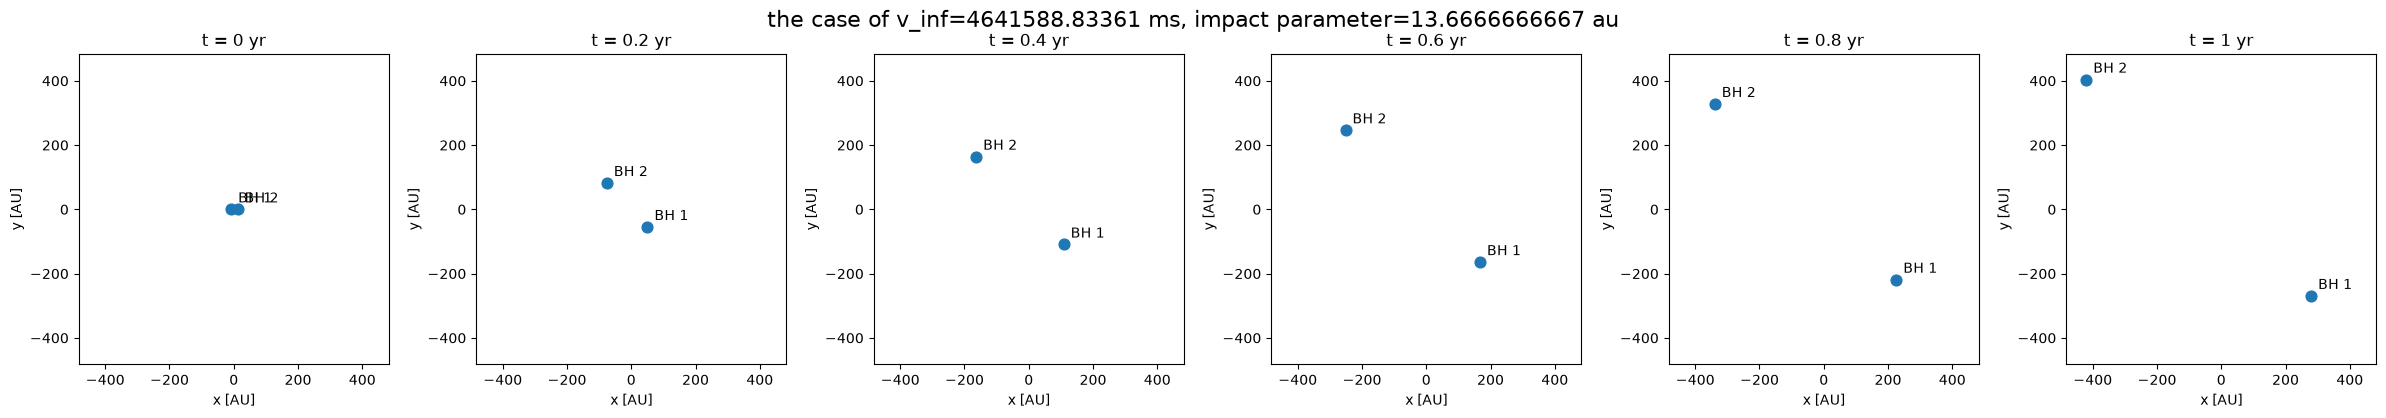

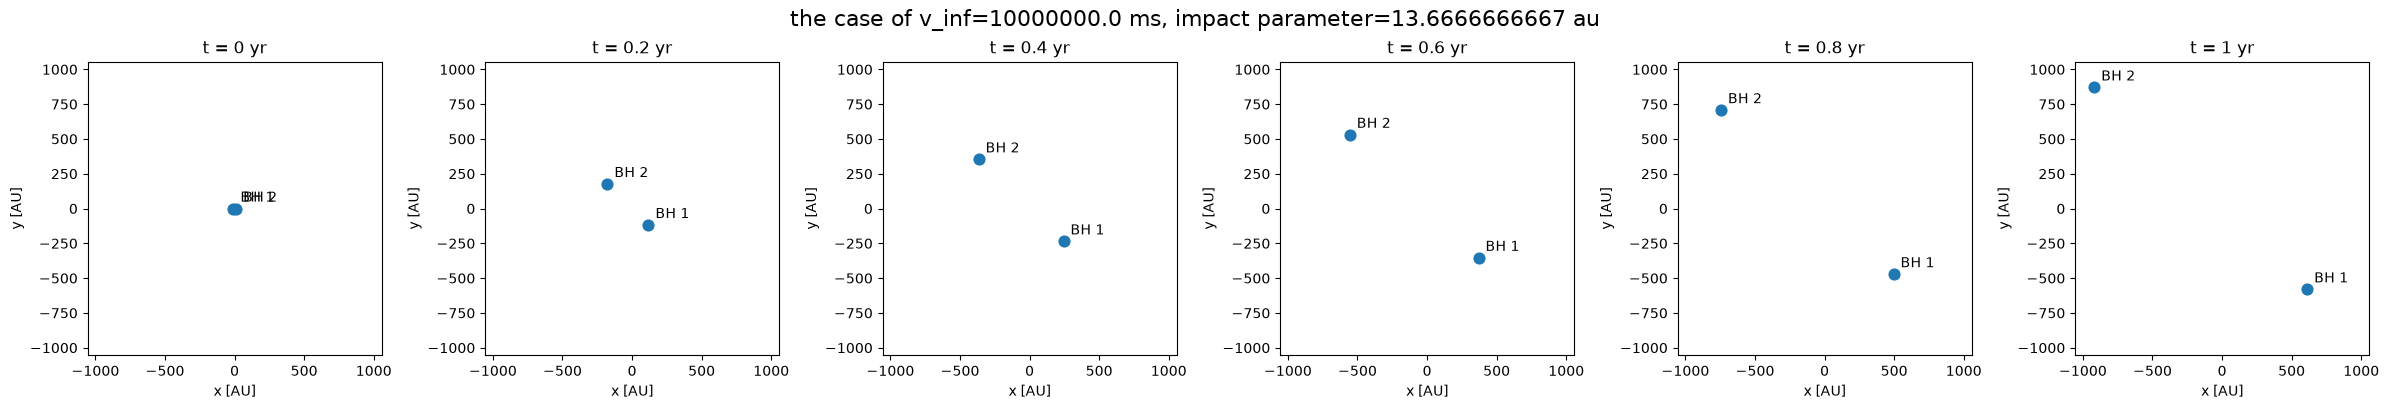

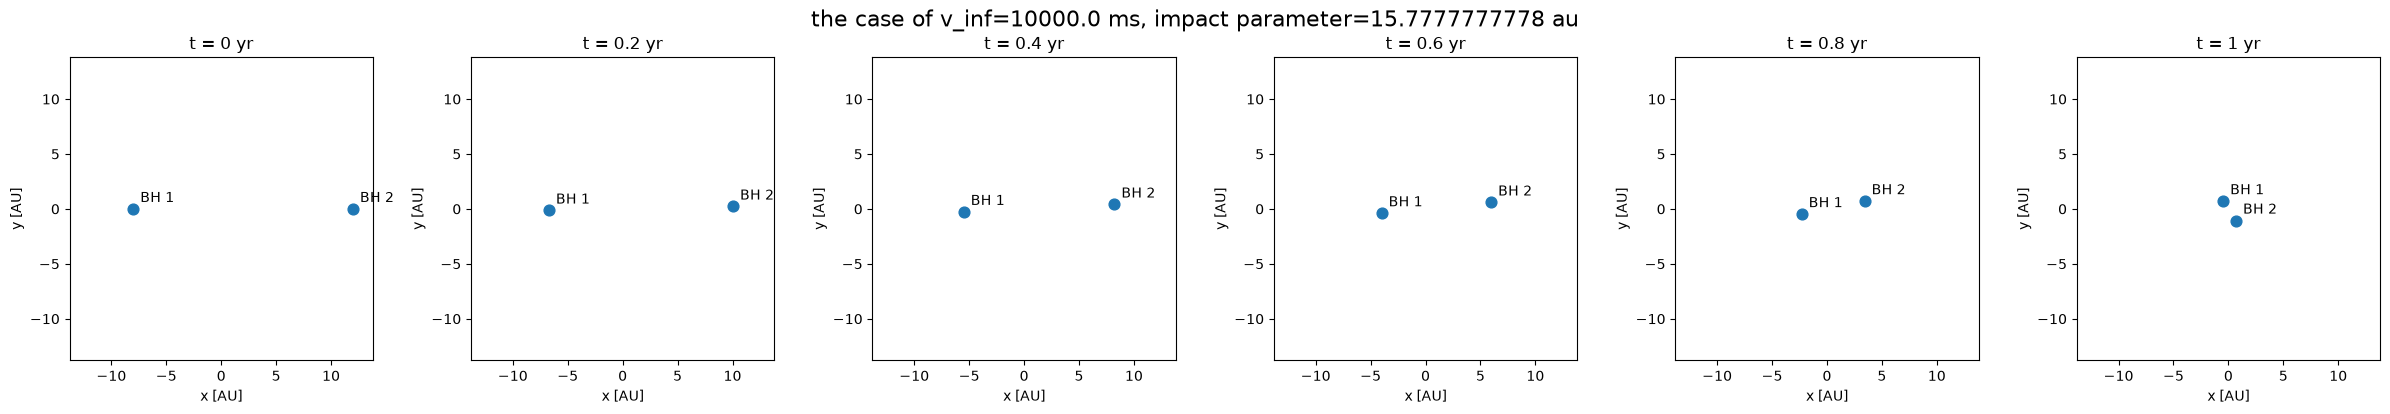

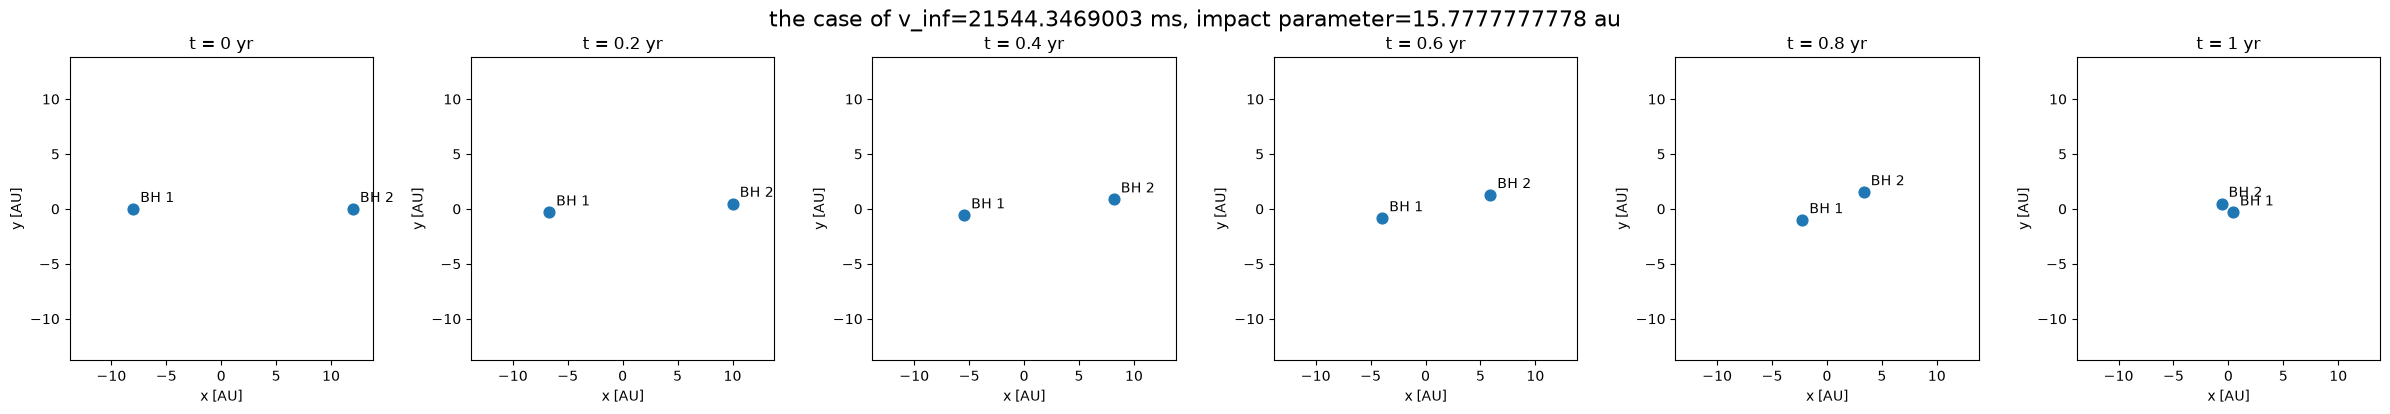

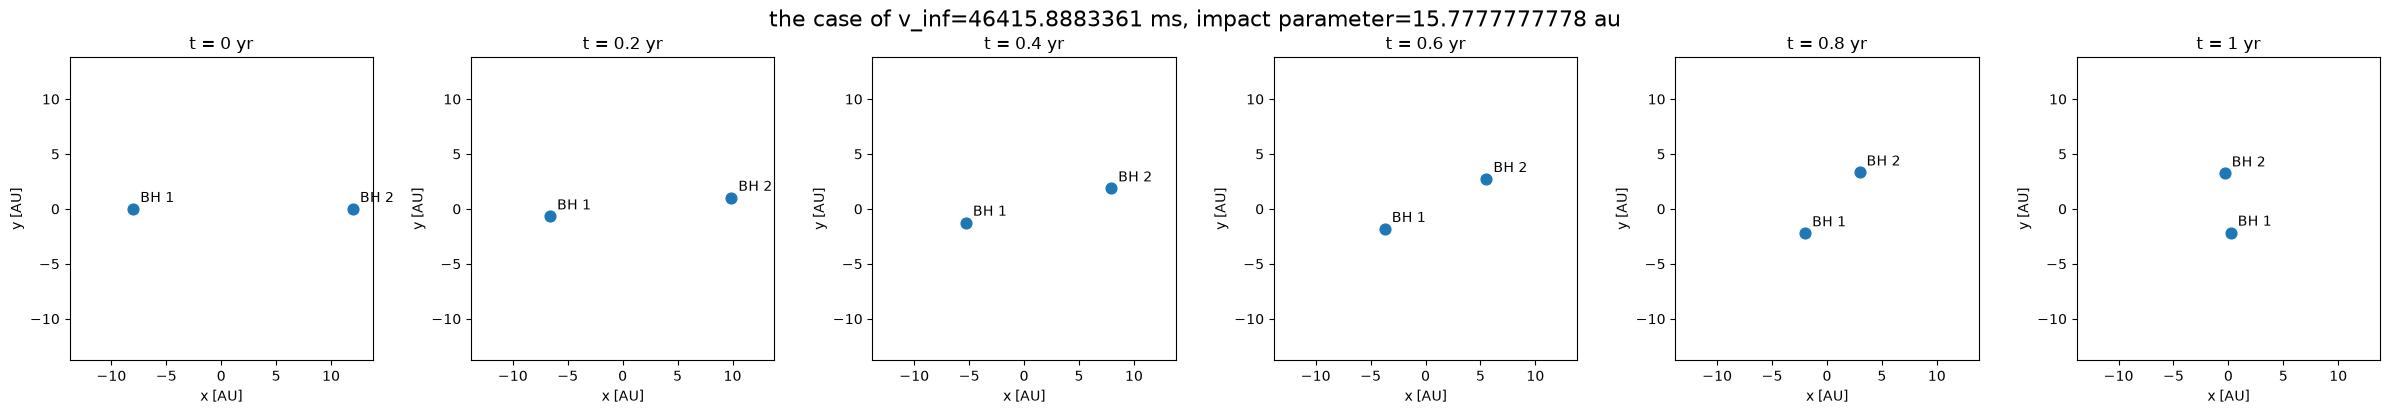

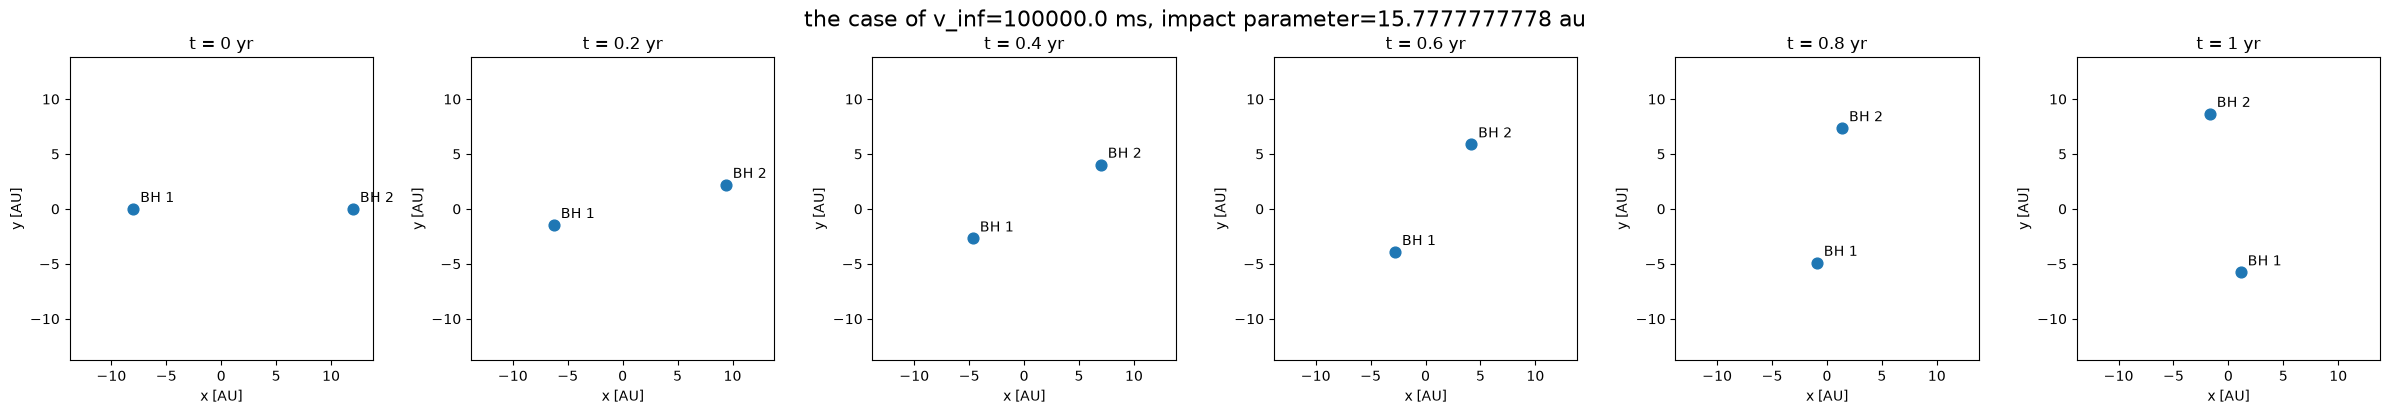

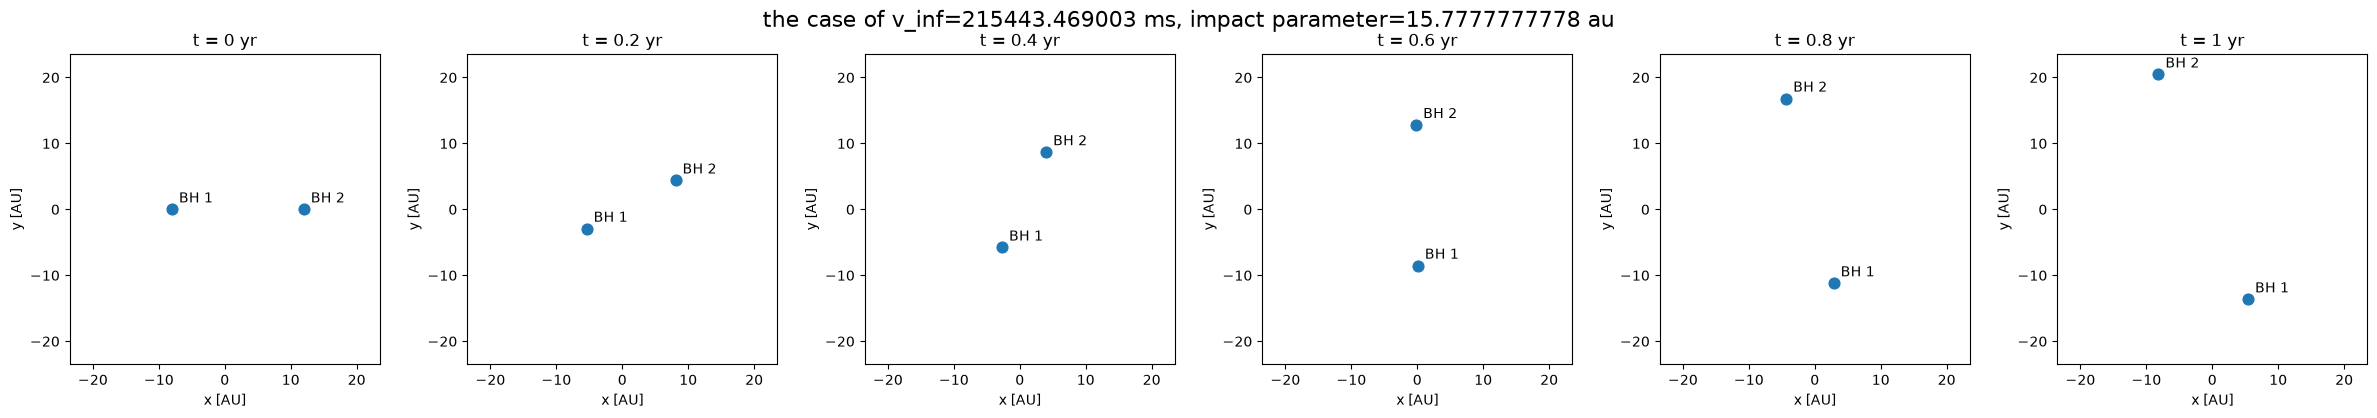

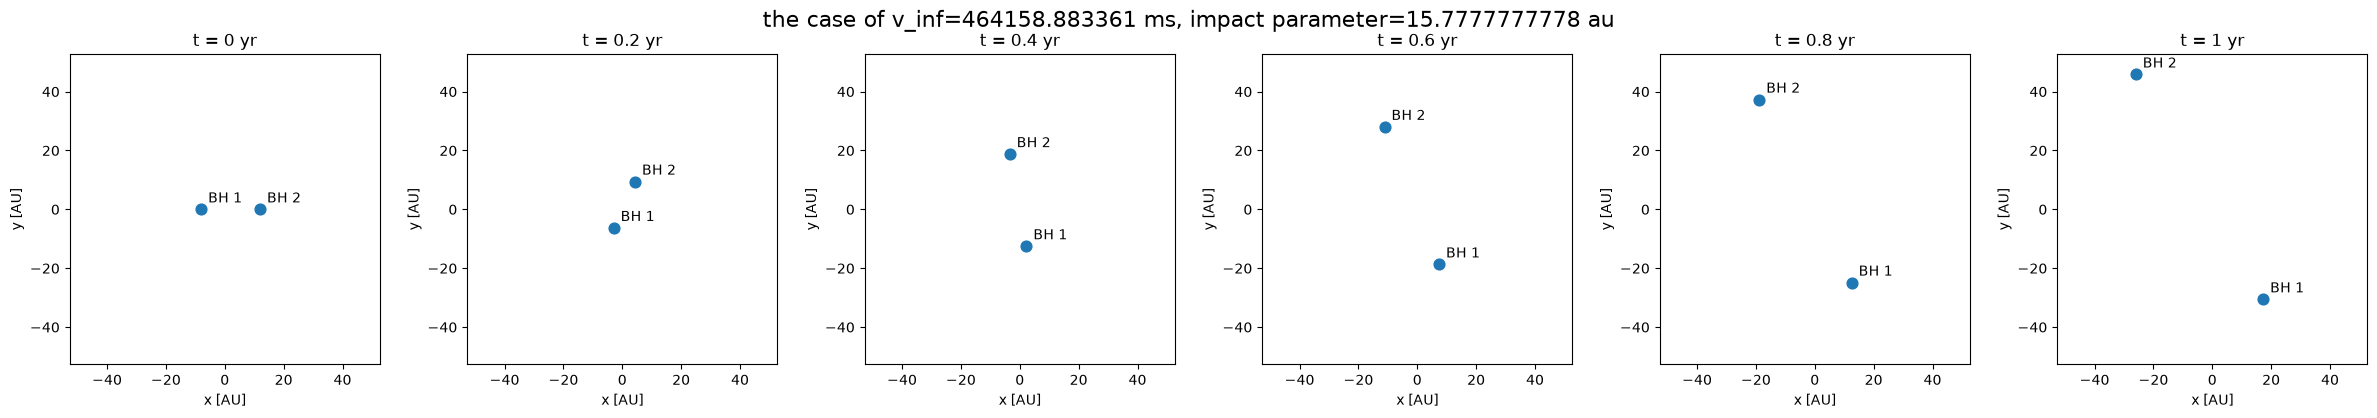

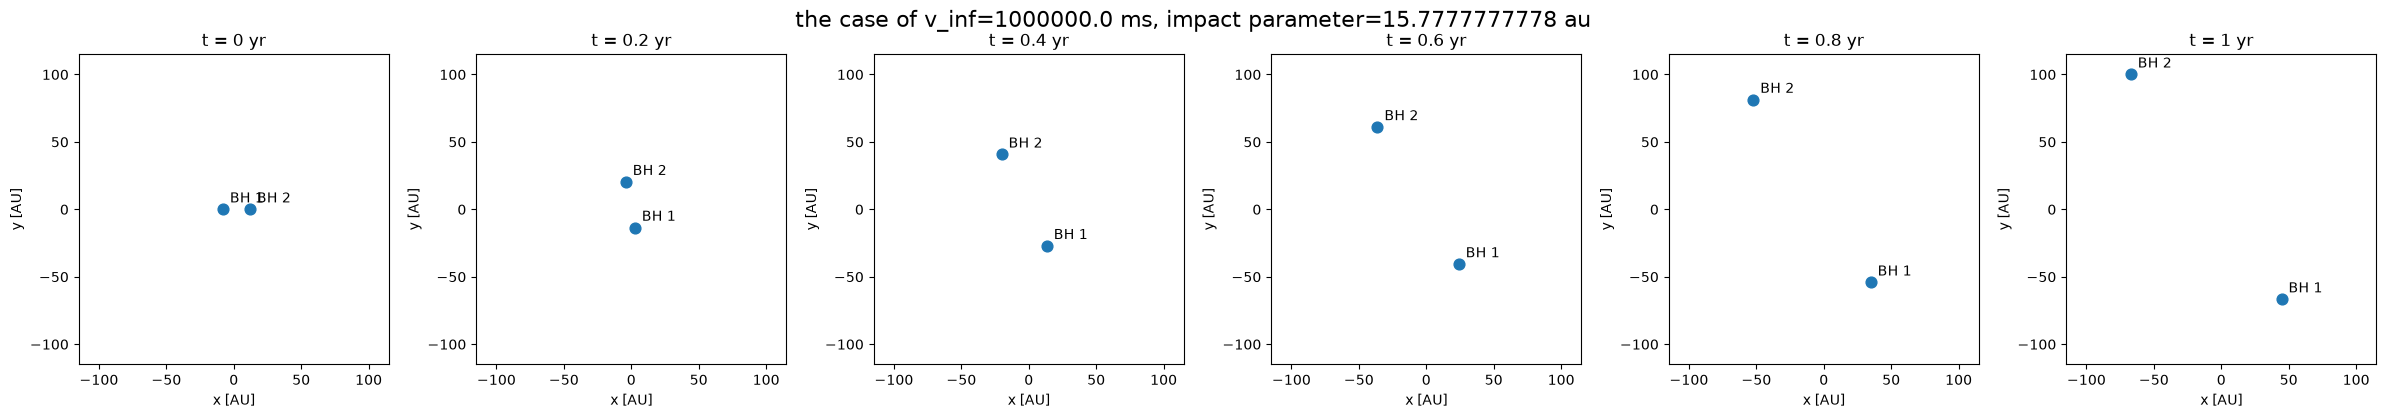

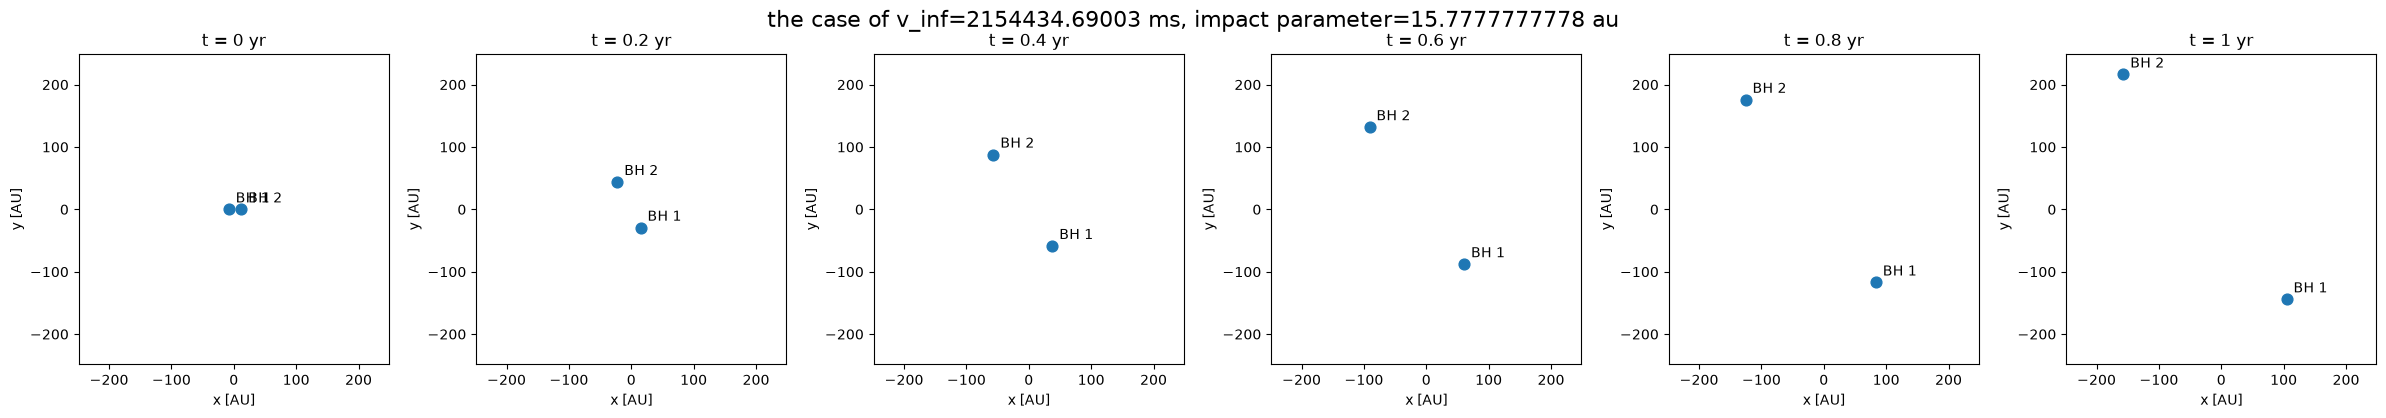

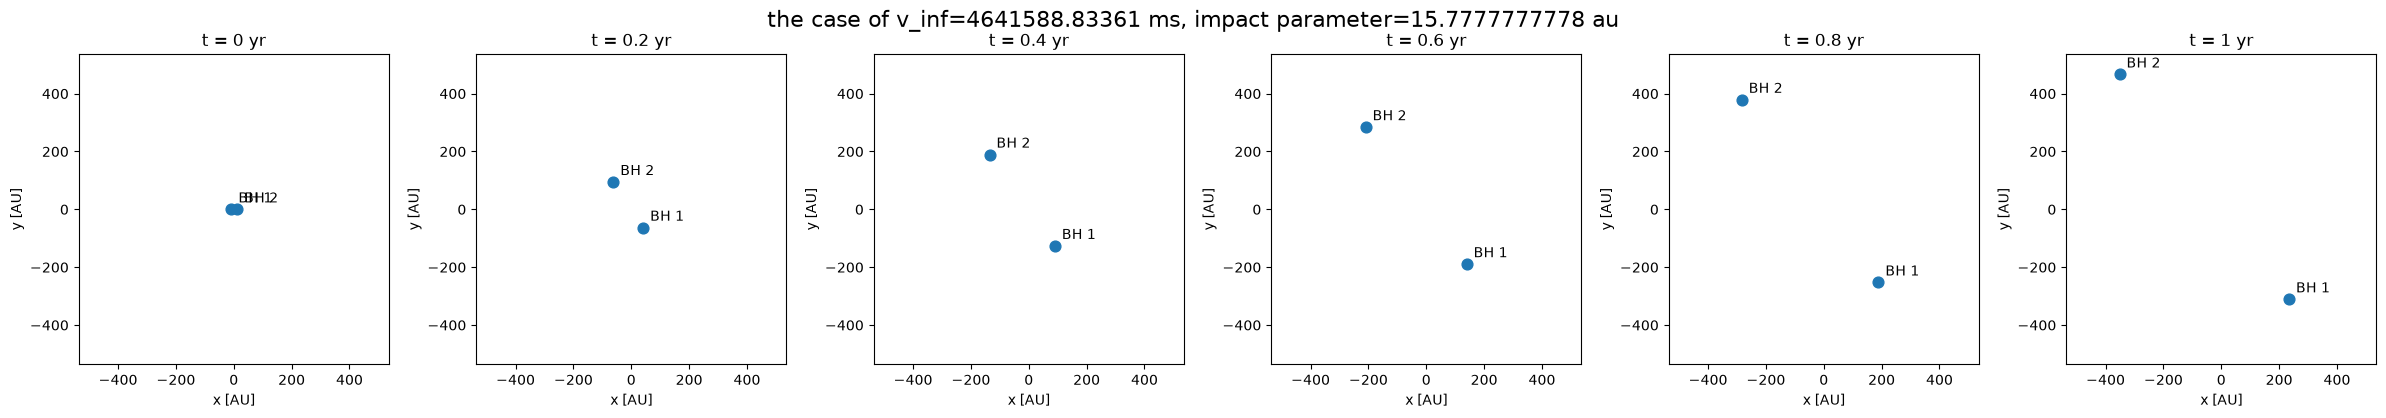

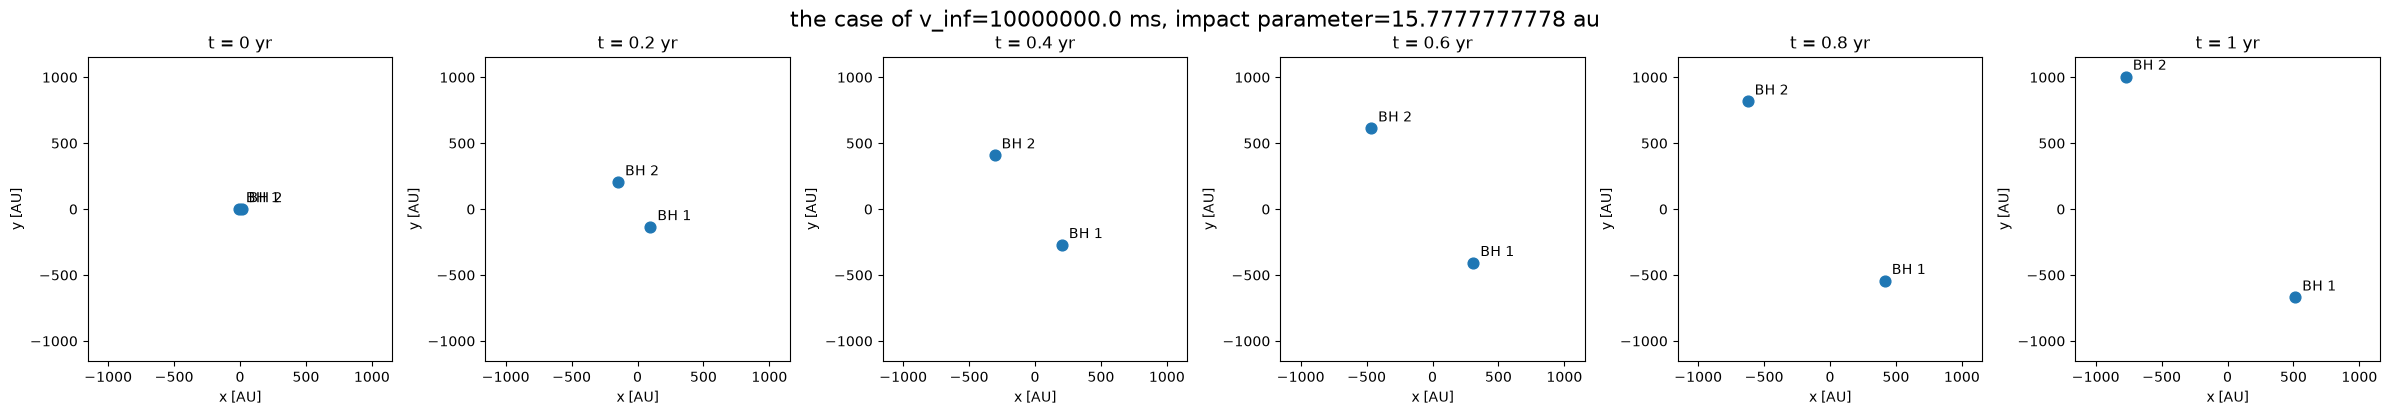

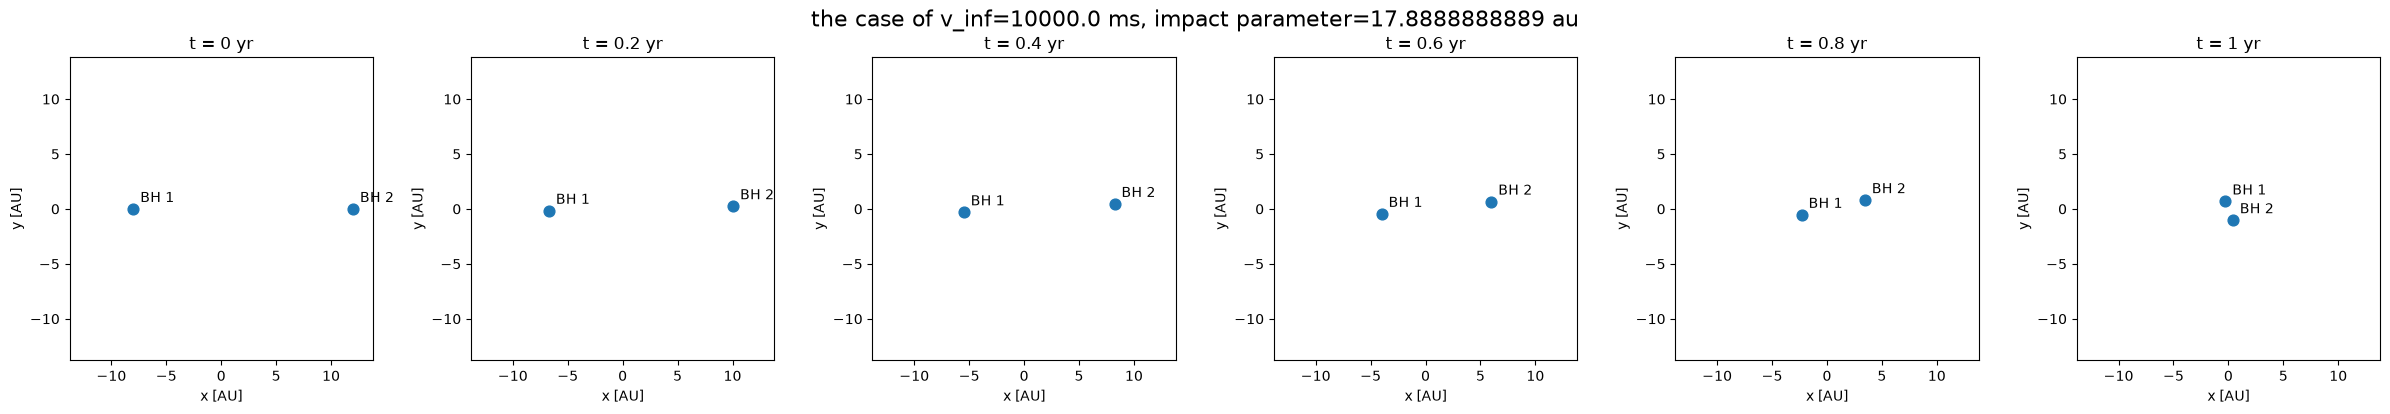

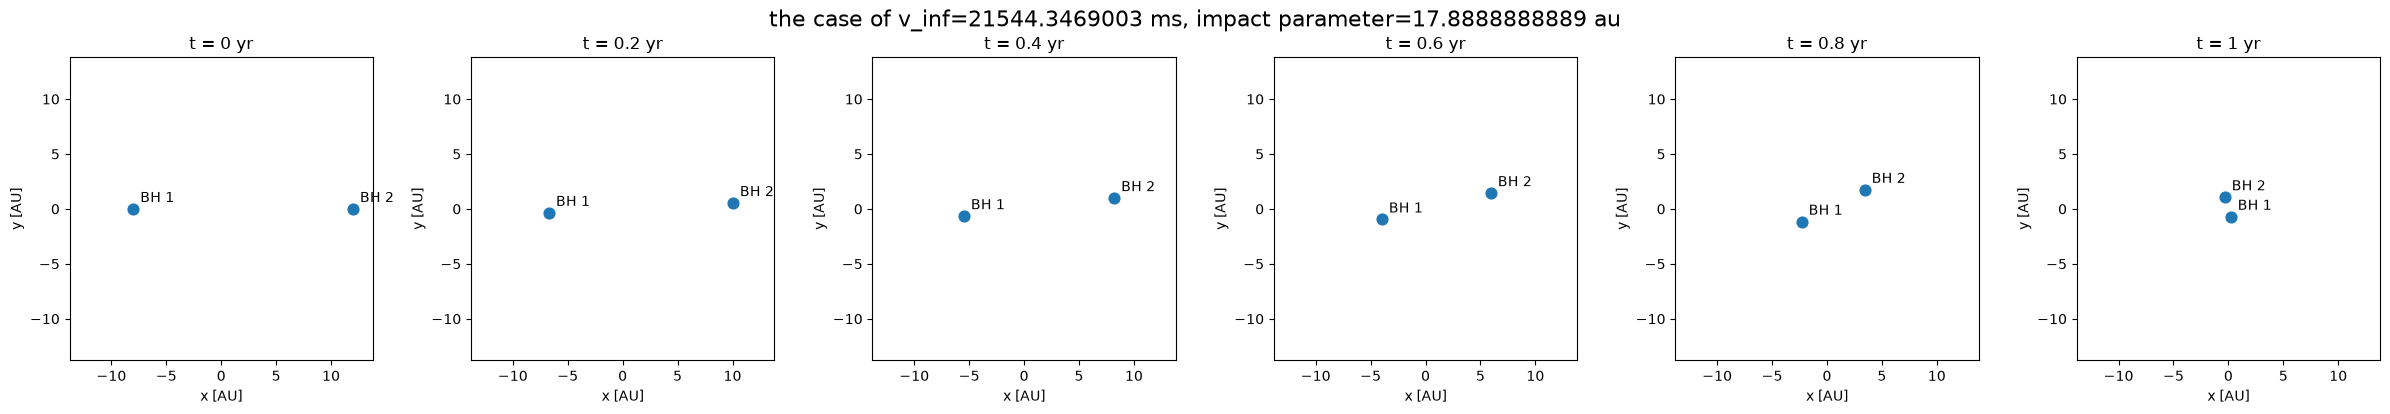

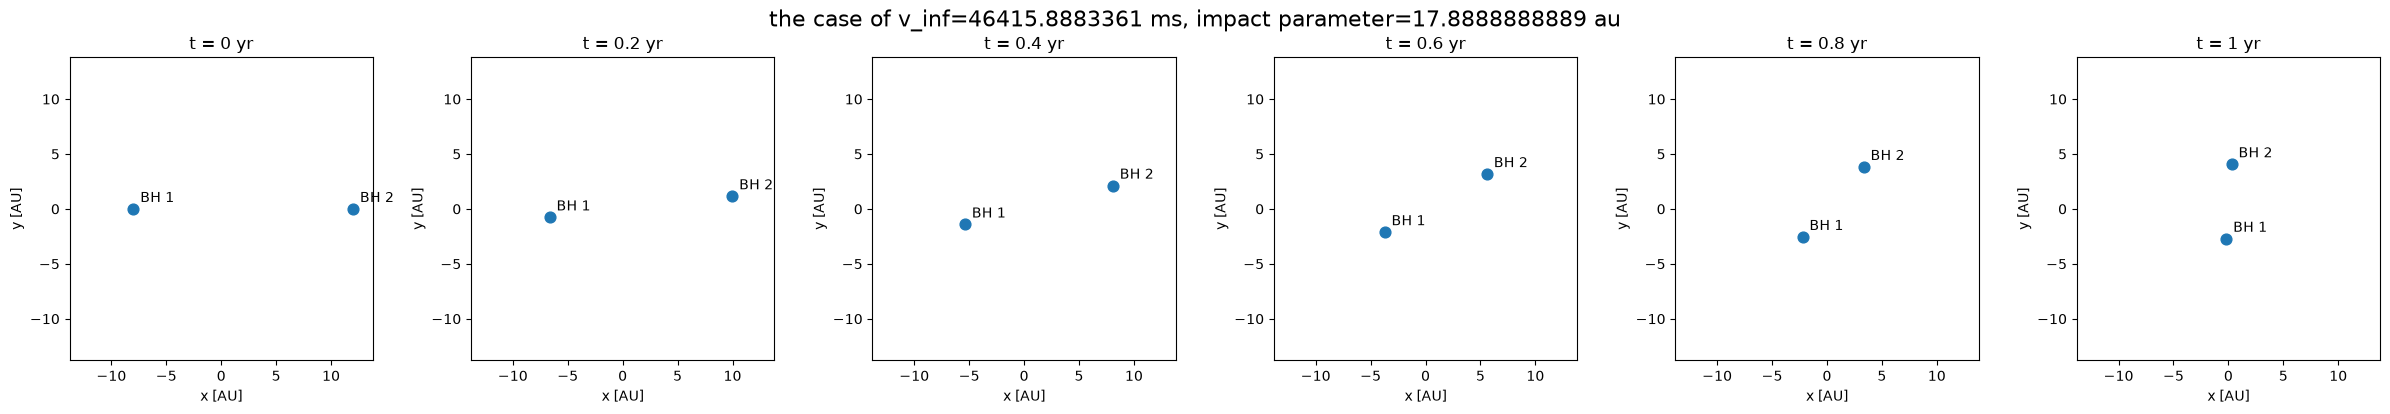

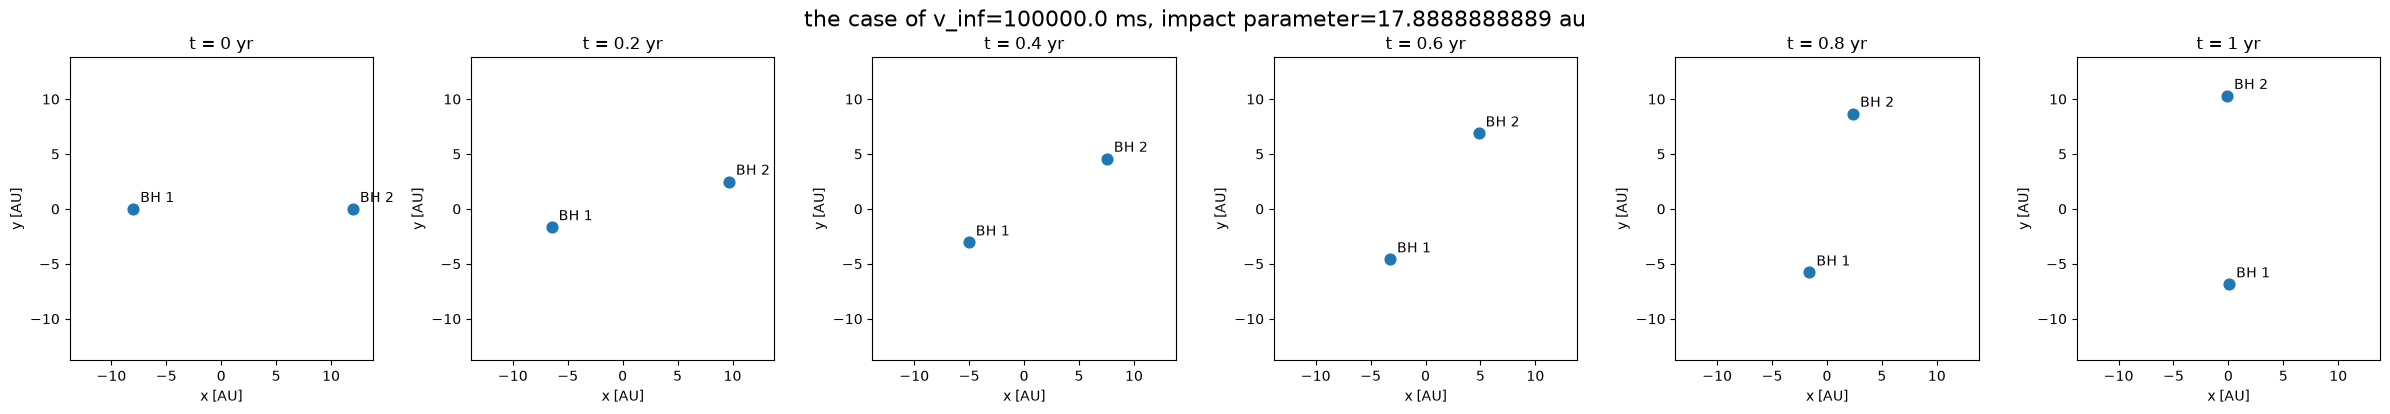

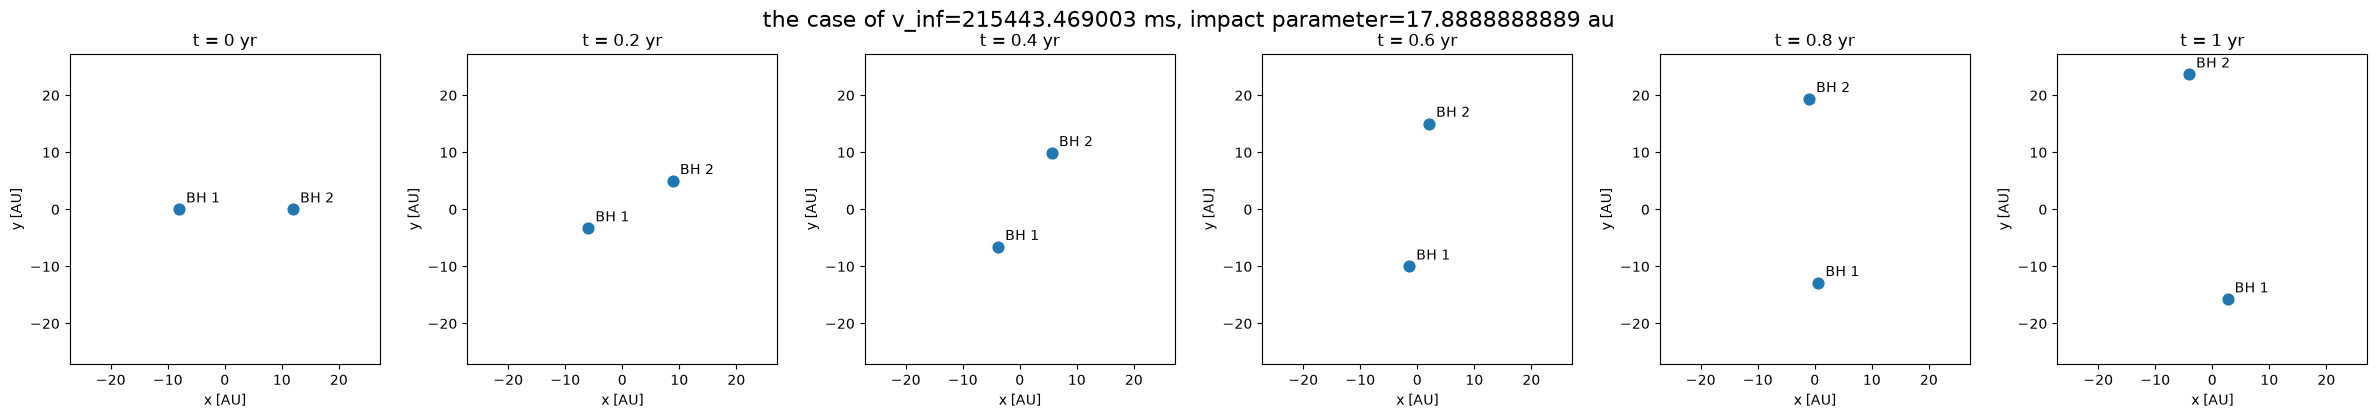

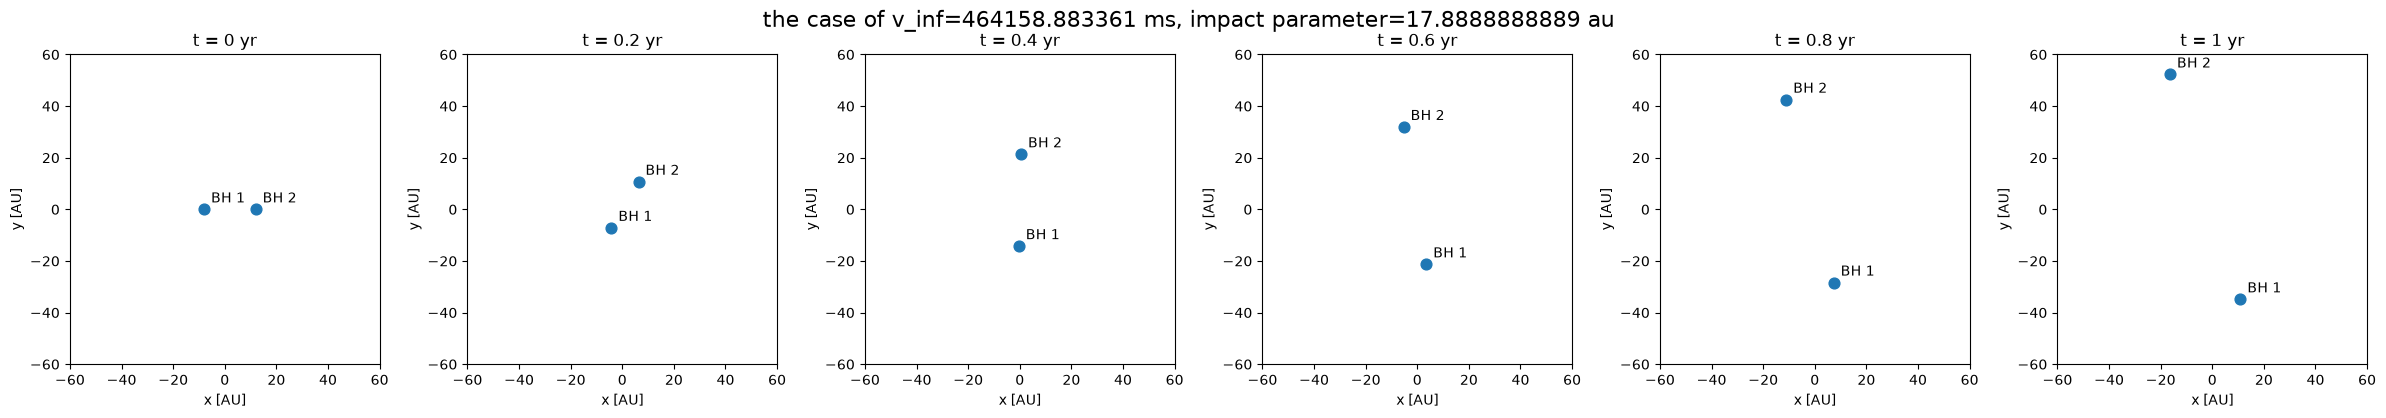

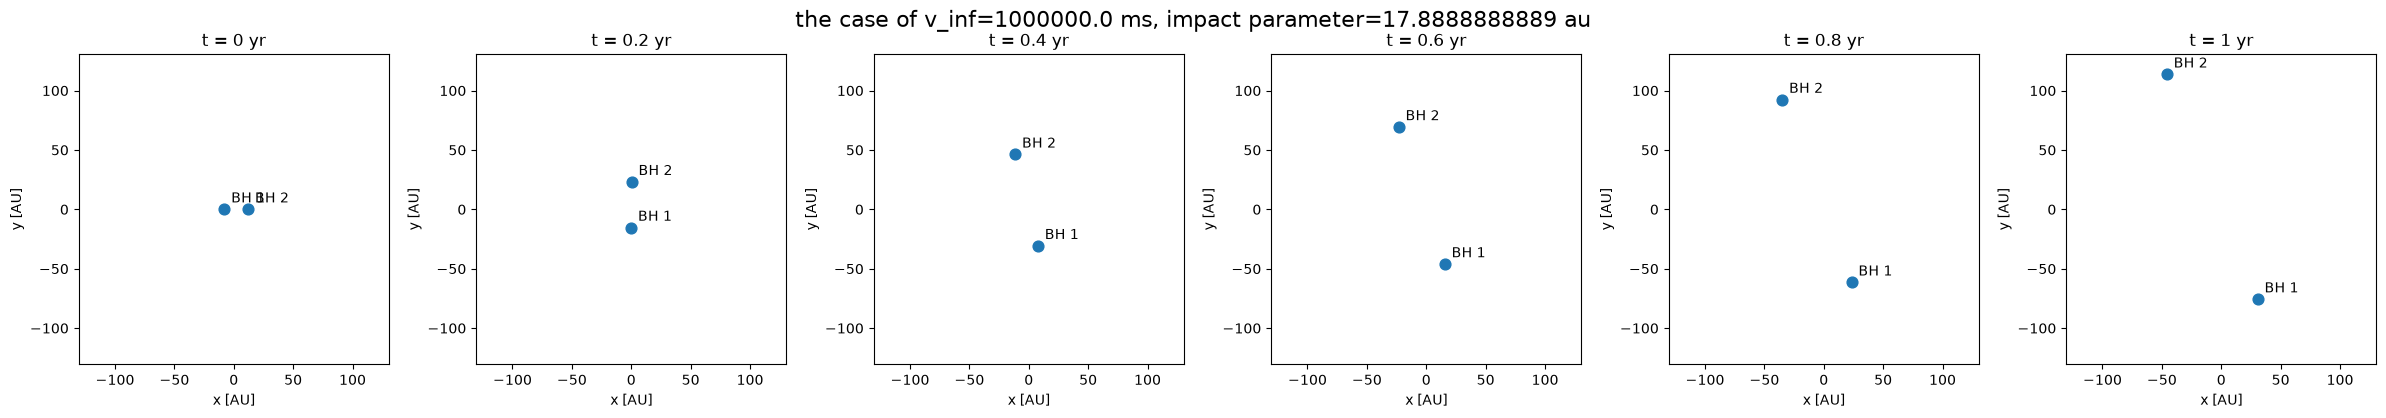

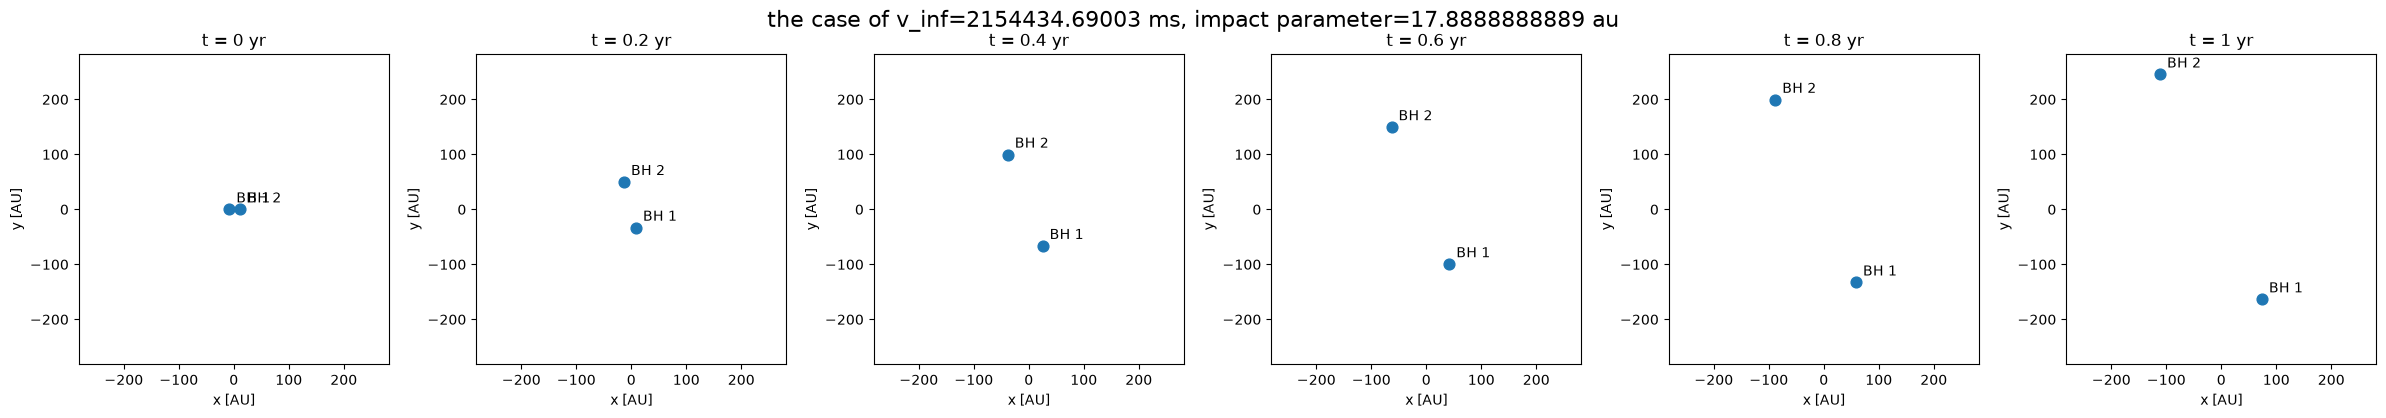

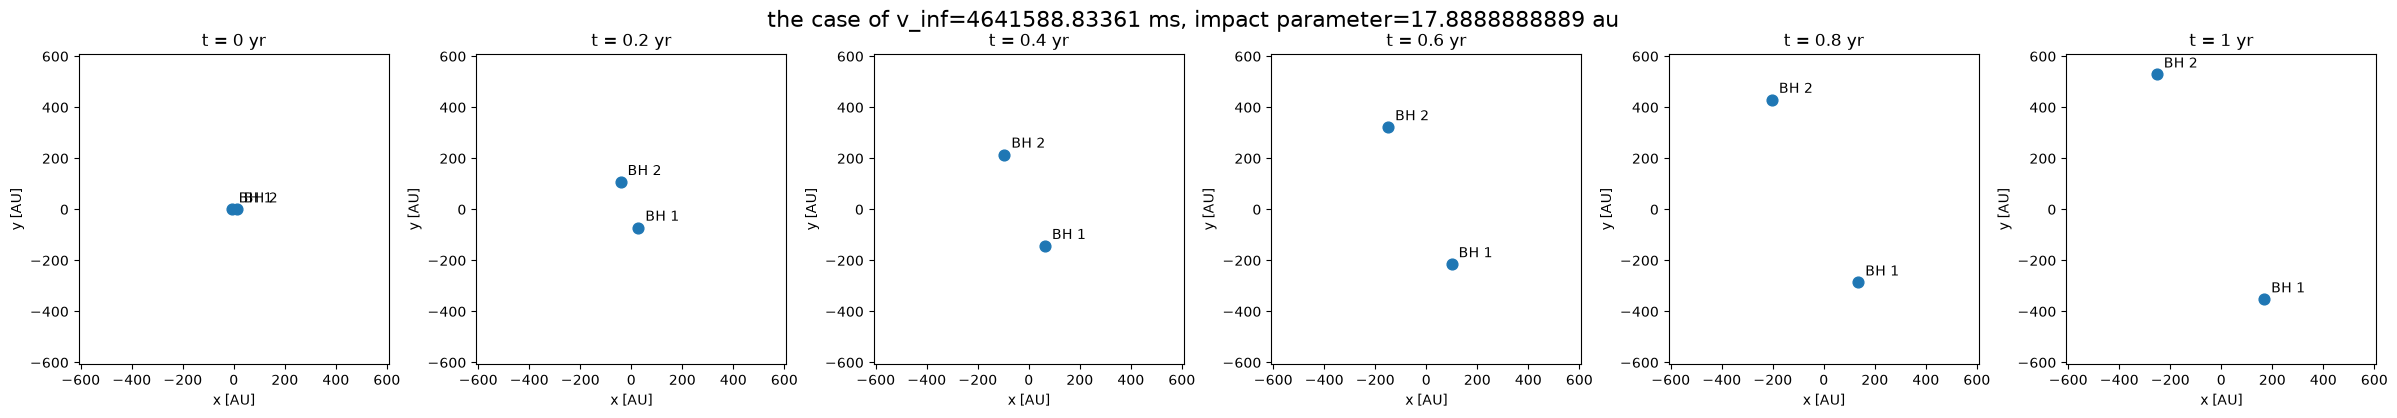

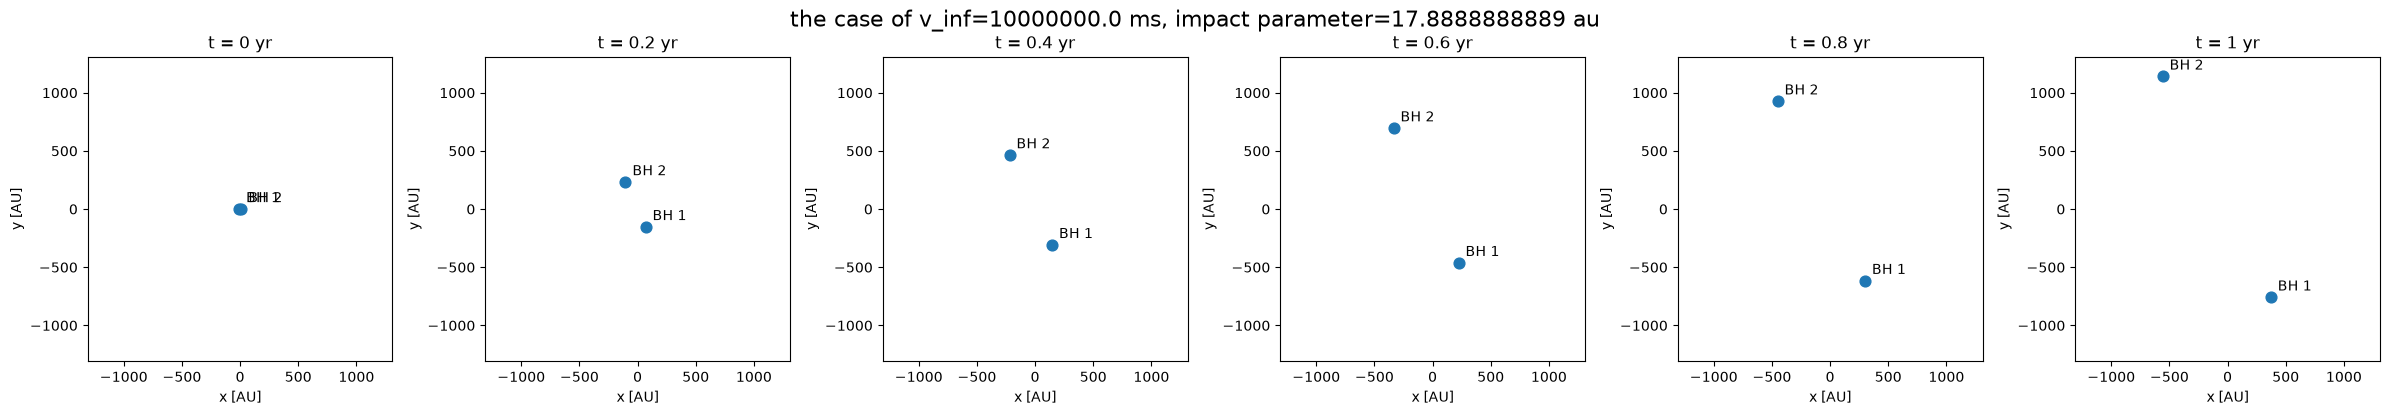

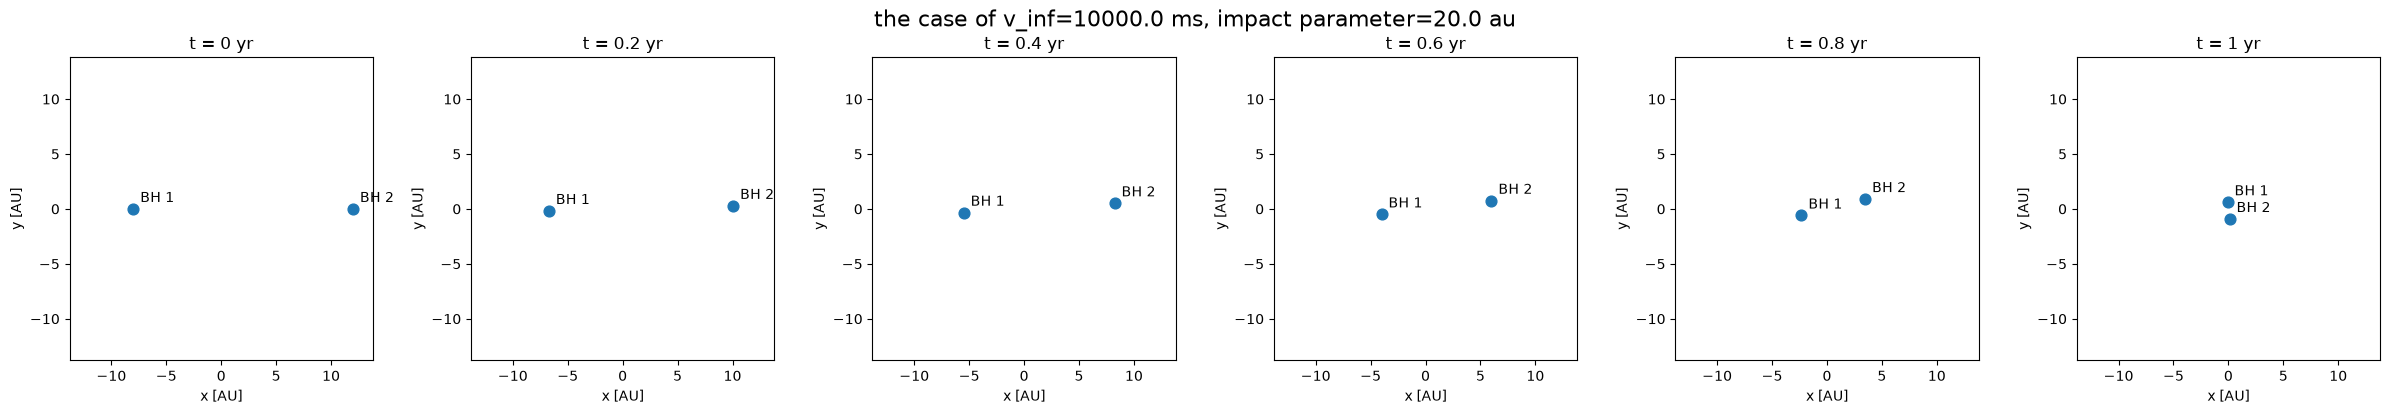

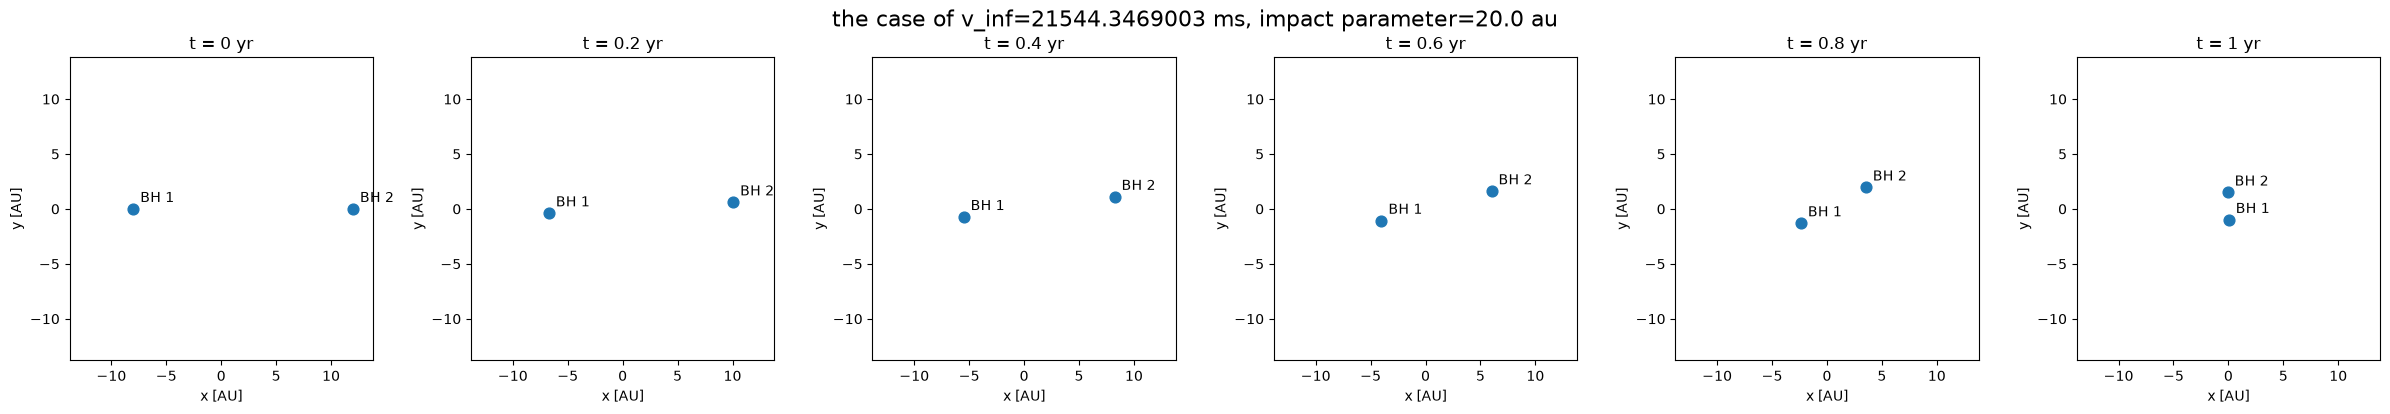

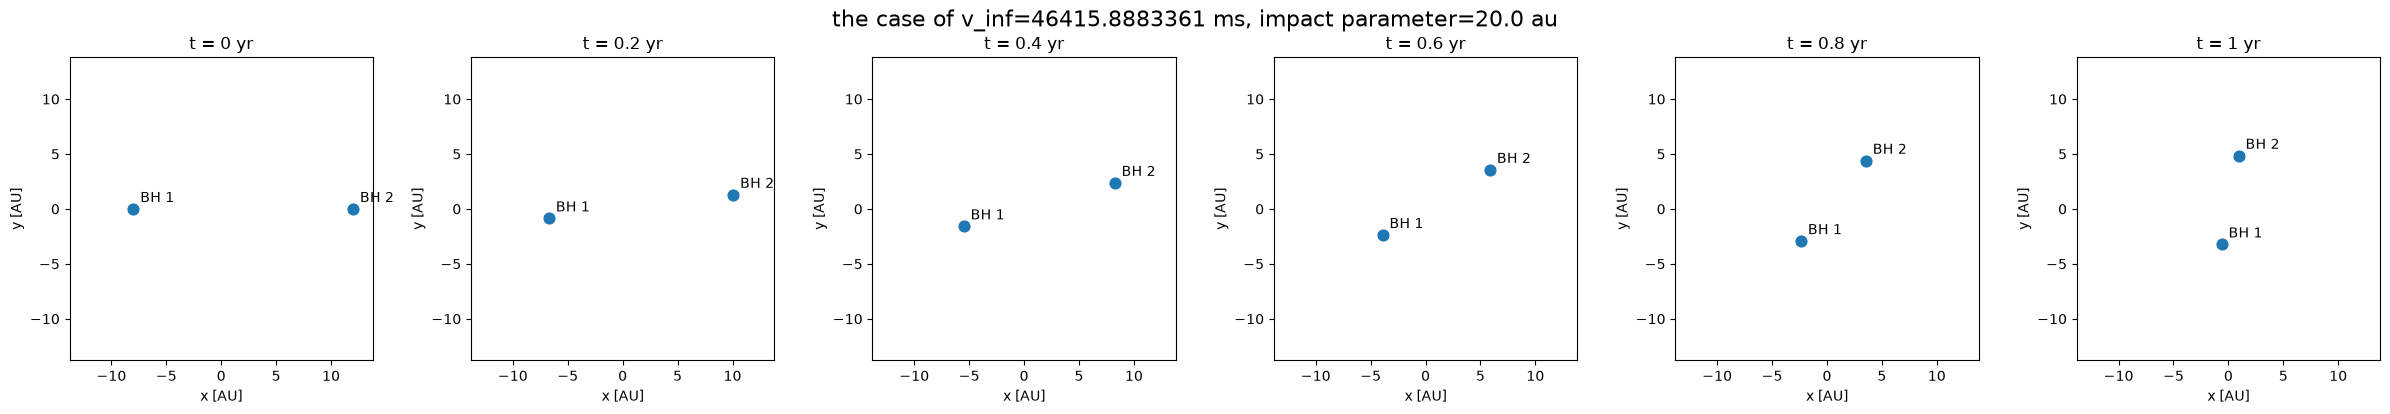

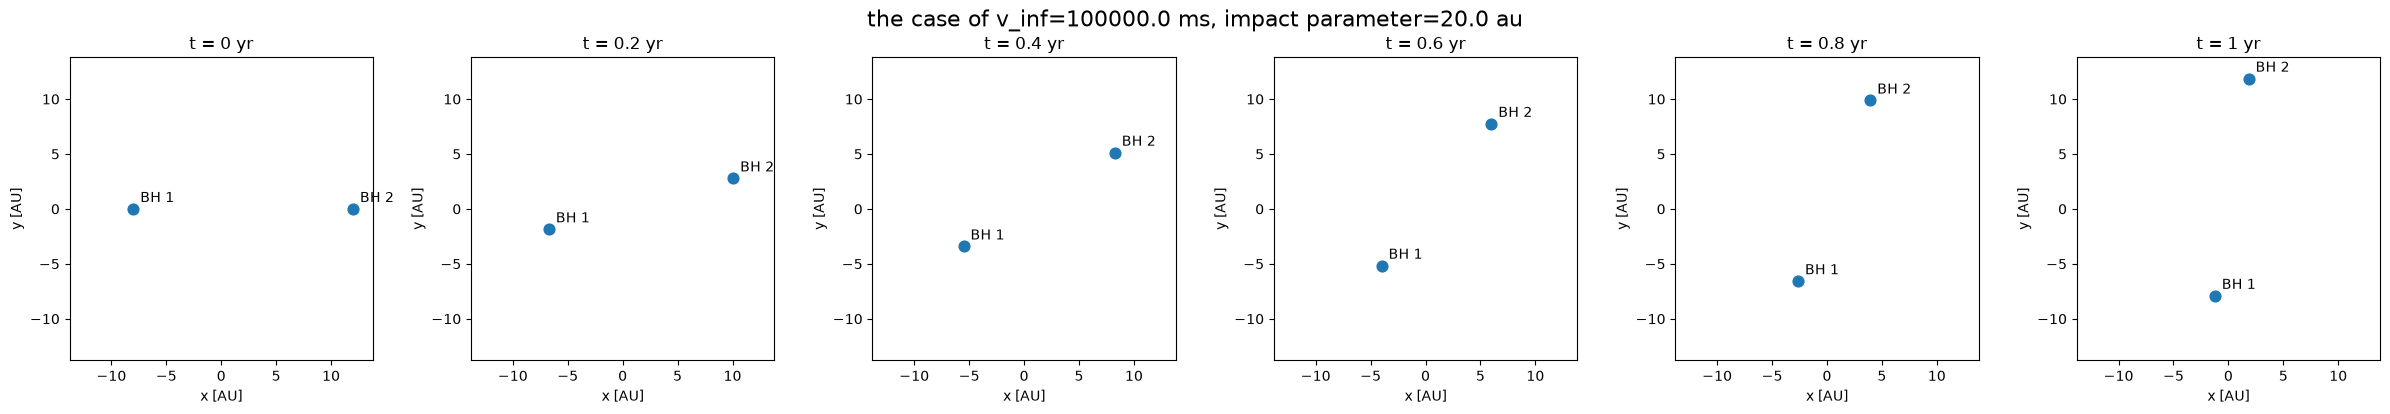

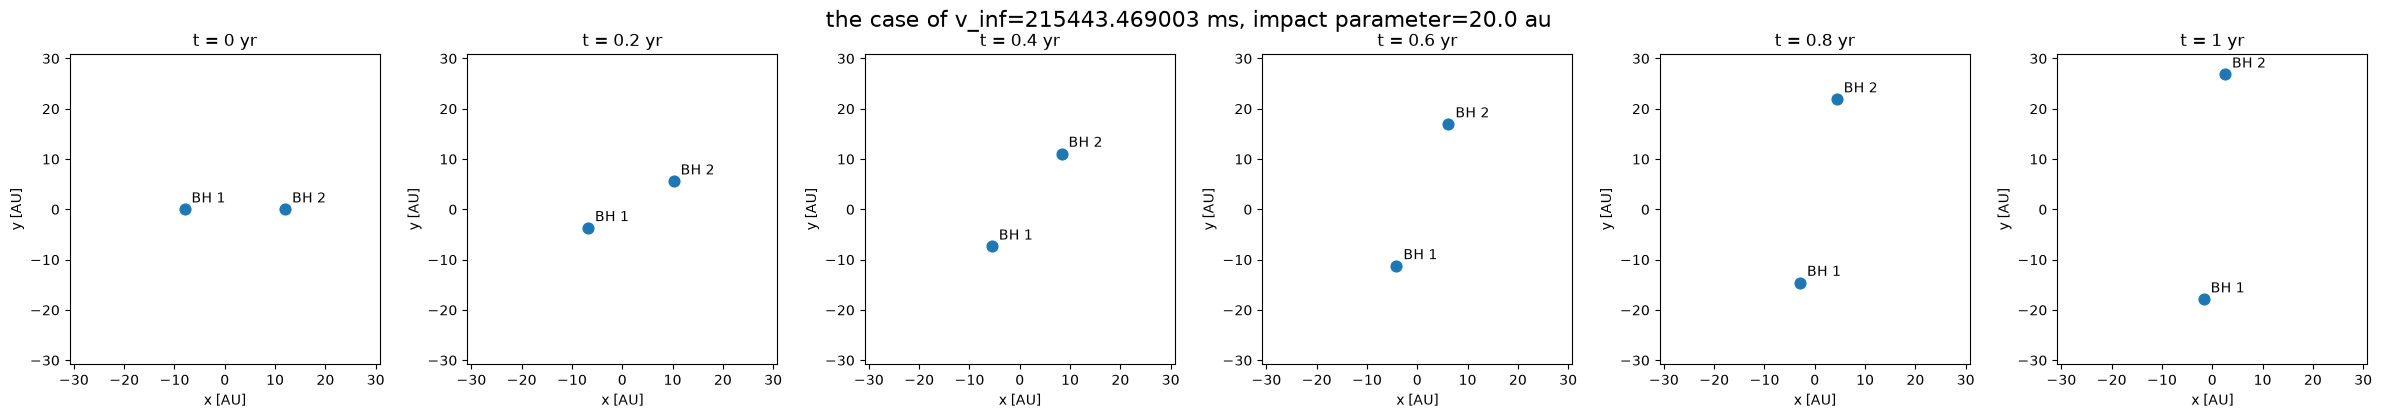

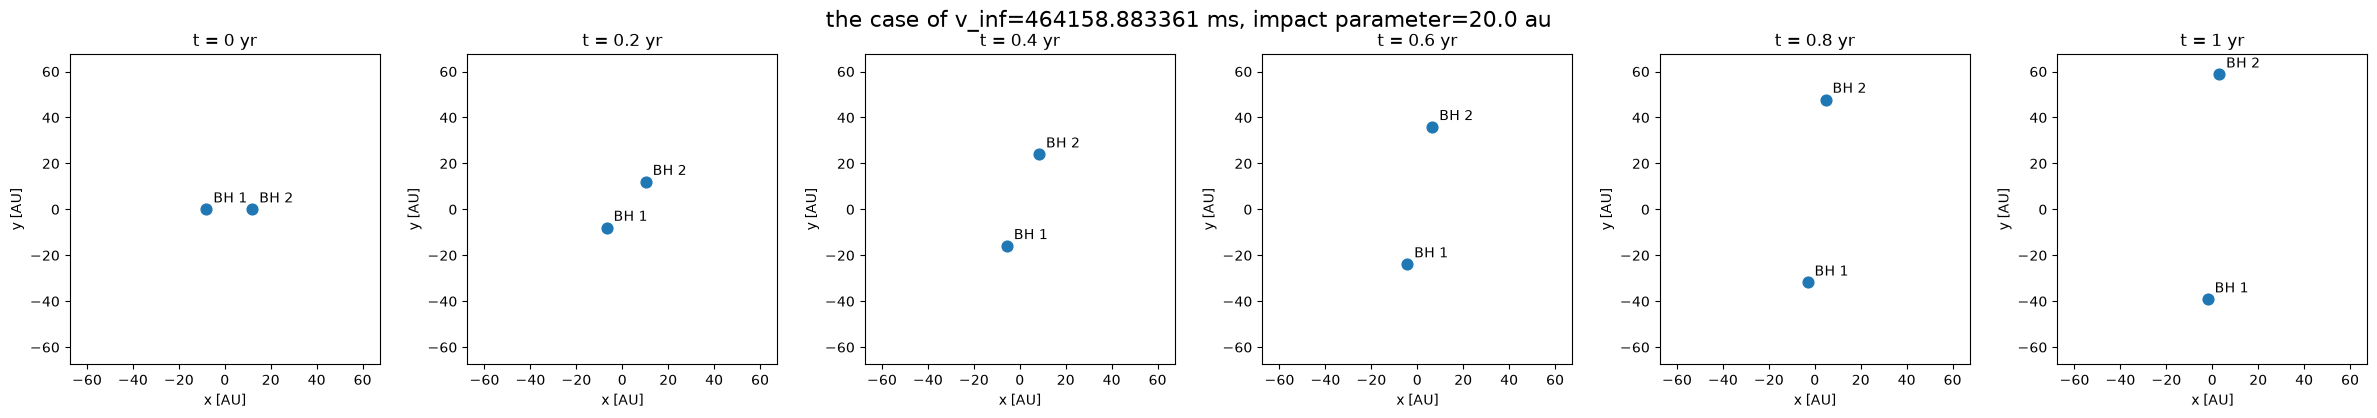

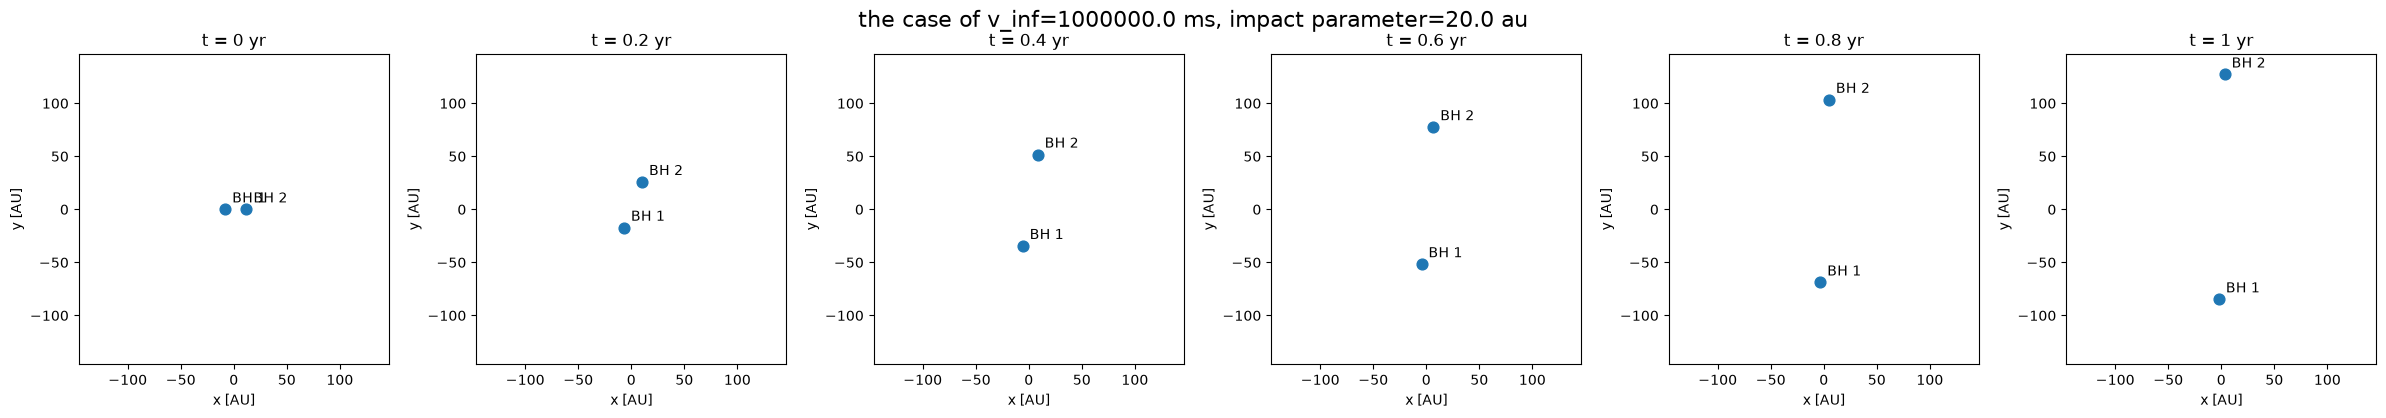

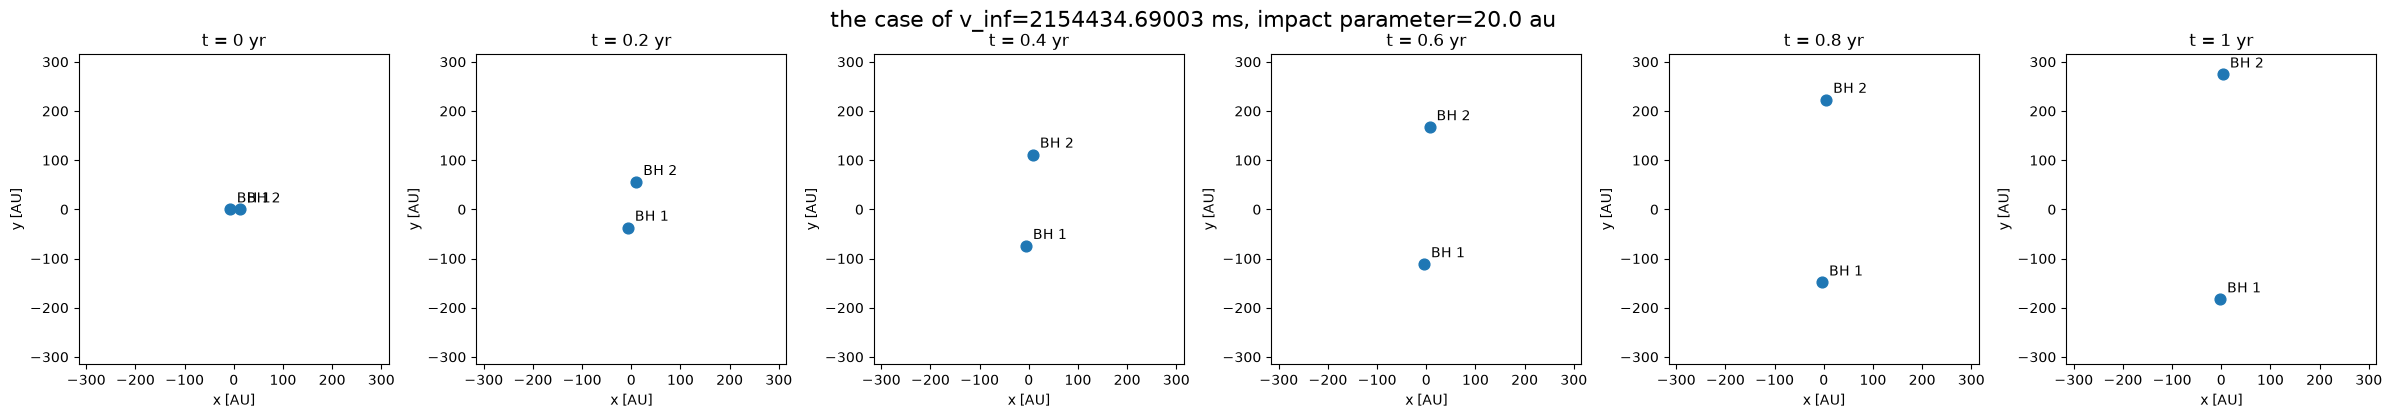

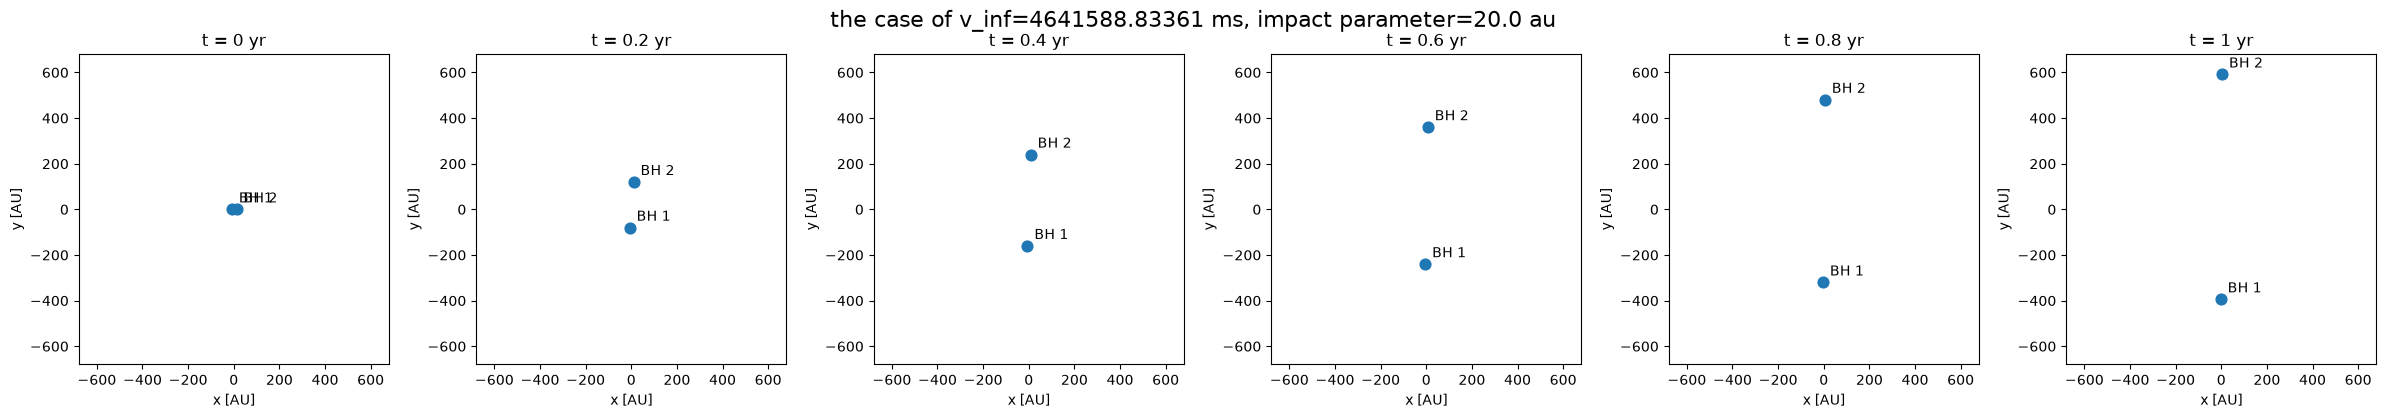

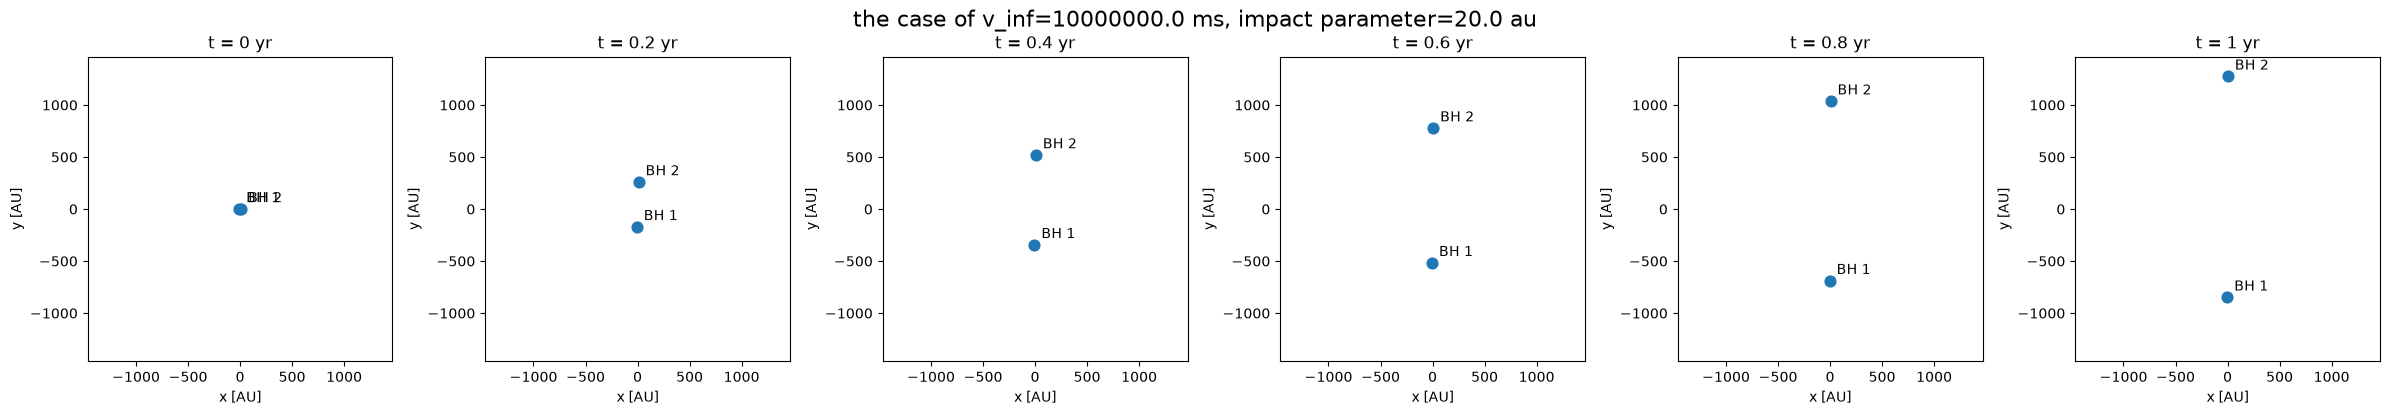

In [5]:
#now crafting the loop
m1 = 30 | units.MSun
m2 = 20 | units.MSun
b = 2 | units.AU
r_init = 20 | units.AU
t_end = 1 |units.yr


velocities_at_inf = np.geomspace(10e3, 10e6, 10, dtype=np.float64) | units.ms
impact_params = np.linspace(1, 20, 10, dtype=np.float64) | units.AU

vel_grid, impact_grid = np.meshgrid(velocities_at_inf, impact_params)
flat_vel_grid = vel_grid.flatten()
flat_impact_grid = impact_grid.flatten()

for i, v_inf in enumerate(flat_vel_grid):
    particles = get_particleset(m1, m2, v_inf, flat_impact_grid[i], r_init)
    #print(f"initial particleset {i+1}, velocity = {v_inf}:")
    #print(particles)
    
    final_particles = evolve_and_plot(particles, r_init, t_end, v_inf, flat_impact_grid[i], n_snapshots=6)
    #print(f"\nfinal particleset {i+1}, velocity = {v_inf}:")
    #print(final_particles)